##Análisis Segmentación Usuarios Billetera W

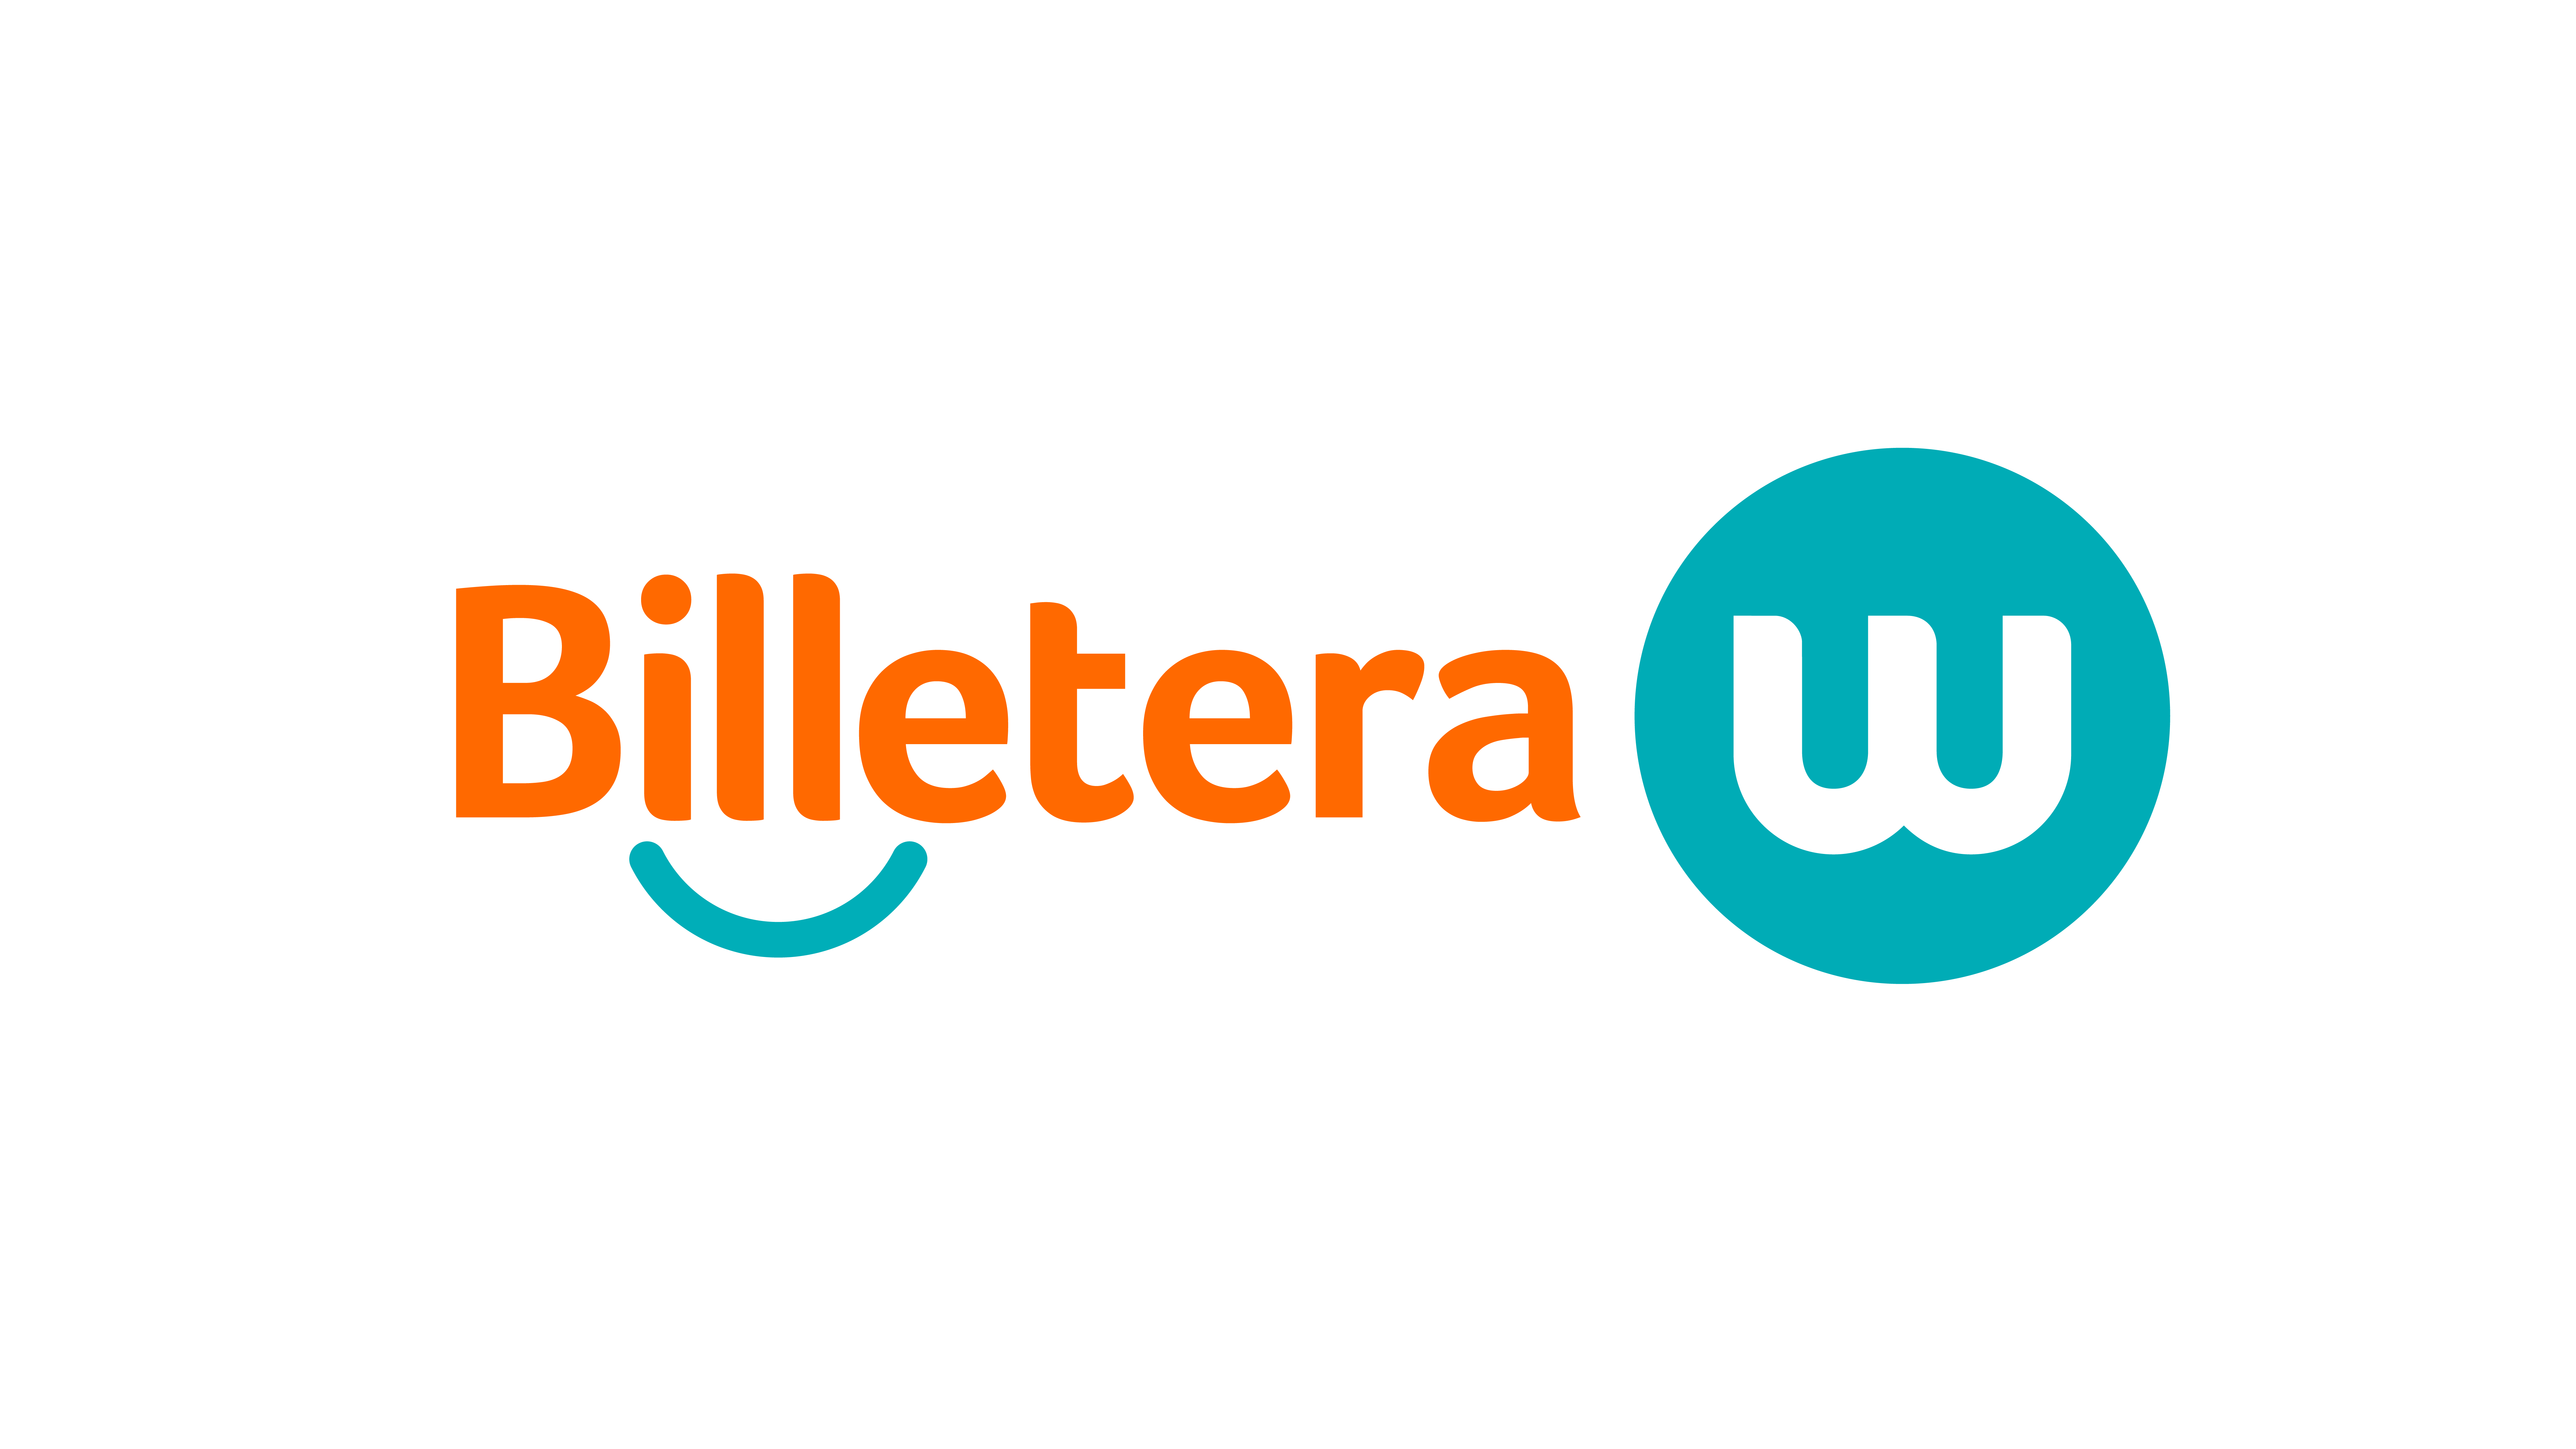

La segmentación permite identificar y clasificar a los usuarios  registrados en Billetera W, mediante la aplicación de técnicas estadísticas se dividen los usuarios en subgrupos con caracteristicas y necesidades similares, lo que facilita la personalización de estrategias de marketing, enfocarse en usuarios mas rentables,aumentar la venta cruzada y mejorar la experiencia del cliente.

## Lectura de los datos

### Objetivo:
Se procece a leer el archivo anonimizado  "Base final para segmentacion Phyton.xlsx"


In [2]:
from google.colab import drive
drive.mount('/content/gdrive')

import pandas as pd

# Ruta del archivo en Google Drive
ruta_archivo = "/content/gdrive/MyDrive/SEGMENTACION USUARIOS BILLETERA/Base final para segmentacion Phyton.xlsx"

df = pd.read_excel(ruta_archivo, engine="openpyxl")
print(df.head())

# 🔹 **Desactivar notación científica**
pd.options.display.float_format = '{:,.2f}'.format  # Formato con comas y dos decimales

# Ver las primeras filas
print(df.head())


Mounted at /content/gdrive
   Identificacion_anonimizada     Genero  Edad_Actual Tipo de sistema  \
0                           1  Masculino    29.618070         Android   
1                           2  Masculino    22.354552         Android   
2                           3  Masculino    21.292266         Android   
3                           4   Femenino    23.827515         Android   
4                           5  Masculino    23.991786             iOS   

        Celular  CUENTACLIENTE  SALDO_Corte_Enero_2025 ESTADOPRODUCTO_Corte  \
0  573142862738        2144087                 1020.21               Normal   
1  573212518935        2123588                    0.00    Cuentas Inactivas   
2  573202858144        2166635                    0.00    Cuentas Inactivas   
3  573194776770        1973501                    0.00    Cuentas Inactivas   
4  573045508299        2087343                    0.00    Cuentas Inactivas   

                      direccionDomicilio CodTipoVivienda  .

In [ ]:
# Convertir la columna "EstratoSocial" en categórica con orden
df["EstratoSocial"] = pd.Categorical(df["EstratoSocial"], ordered=True)


In [ ]:
print(df.info())  # Estructura del dataset
print(df.describe())  # Estadísticas de variables numéricas
print(df.isnull().sum())  # Ver valores nulos


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73046 entries, 0 to 73045
Columns: 240 entries, Identificacion_anonimizada to Saldo_Constante_mayor_10000
dtypes: category(1), datetime64[ns](2), float64(89), int64(115), object(33)
memory usage: 133.3+ MB
None
       Identificacion_anonimizada  Edad_Actual            Celular  \
count                   73,046.00    73,046.00          73,046.00   
mean                    36,523.50        37.48 573,145,116,890.99   
min                          1.00        18.16 571,002,674,916.00   
25%                     18,262.25        26.74 573,112,126,108.25   
50%                     36,523.50        34.70 573,145,171,644.50   
75%                     54,784.75        45.97 573,204,035,913.50   
max                     73,046.00        96.81 576,015,886,099.00   
std                     21,086.71        13.29      79,754,869.44   

       CUENTACLIENTE  SALDO_Corte_Enero_2025  Año_creacion  Mes_creacion  \
count      73,046.00               73,046

In [ ]:
# Función actualizada para asignar generación según año de nacimiento
def asignar_generacion(anio):
    if 1925 <= anio <= 1945:
        return "Generación Silent"
    elif 1946 <= anio <= 1964:
        return "Baby Boomer"
    elif 1965 <= anio <= 1980:
        return "Generación X"
    elif 1981 <= anio <= 1996:
        return "Millennials"
    elif 1997 <= anio <= 2012:
        return "Generación Z"
    elif 2013 <= anio <= 2025:
        return "Generación Alfa"
    else:
        return "Otra"

# Aplicar la función al DataFrame
df["Generacion"] = df["Año_nacimiento"].apply(asignar_generacion)


In [ ]:
from pandas.api.types import CategoricalDtype

# Definir el orden correcto
orden_generaciones = [
    "Generación Silent",
    "Baby Boomer",
    "Generación X",
    "Millennials",
    "Generación Z",
    "Generación Alfa",
    "Otra"
]

# Convertir a tipo categórico ordenado
generacion_ordenada = CategoricalDtype(categories=orden_generaciones, ordered=True)
df["Generacion"] = df["Generacion"].astype(generacion_ordenada)


In [ ]:
df

,Identificacion_anonimizada,Genero,Edad_Actual,Tipo de sistema,Celular,CUENTACLIENTE,SALDO_Corte_Enero_2025,ESTADOPRODUCTO_Corte,direccionDomicilio,CodTipoVivienda,...,Promedio6Meses_Creación_de_Deposito,PromedioUltimos12M_Consulta_Cuenta_Ahorro,PromedioUltimos12M_Consulta_Estado_Cuenta_Ahorro,PromedioUltimos12M_Consulta_OTP_Retiro,PromedioUltimos12M_Creación_de_Deposito,Indicador_TNM,Año_nacimiento,CodActividadEconomica_v2,Saldo_Constante_mayor_10000,Generacion
0,1,Masculino,29.62,Android,573142862738,2144087,"1,020.21",Normal,Urbano Conjunto Oasis T16 A402 S Mate,Familiar,...,0,0.00,0.00,0.00,0,No,1995,Otras actividades,No,Millennials
1,2,Masculino,22.35,Android,573212518935,2123588,0.00,Cuentas Inactivas,Urbano Calle 26 Sur # 6-17,Propia,...,0,0.00,0.00,0.00,0,No,2002,Personas Naturales Subsidiadas por Terceros,No,Generación Z
2,3,Masculino,21.29,Android,573202858144,2166635,0.00,Cuentas Inactivas,Urbano Calle 19 # 102-06 Local 9,Propia,...,0,0.00,0.00,0.00,0,No,2003,Personas Naturales Subsidiadas por Terceros,No,Generación Z
3,4,Femenino,23.83,Android,573194776770,1973501,0.00,Cuentas Inactivas,Urbano Av Calle 145 # 89-16,Propia,...,0,0.00,0.00,0.00,0,No,2001,Personas Naturales Subsidiadas por Terceros,No,Generación Z
4,5,Masculino,23.99,iOS,573045508299,2087343,0.00,Cuentas Inactivas,Urbano Calle 52 No. 50-40,Propia,...,0,0.00,0.00,0.00,0,No,2001,Personas Naturales Subsidiadas por Terceros,No,Generación Z
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
73041,73042,Masculino,43.59,iOS,573225809957,2548426,0.00,Normal,Urbano Cll 70 # 7t Bis-87,Propia,...,0,4.17,0.58,0.00,0,Si,1981,Otras actividades,No,Millennials
73042,73043,Masculino,42.14,Android,573127572245,968395,0.00,Normal,Urbano Chinchina Calle 7 Casa 11 - 06,Familiar,...,0,0.08,0.00,0.00,0,Si,1982,Otras actividades,No,Millennials
73043,73044,Masculino,60.50,Android,573113549354,2287683,0.00,Cuentas Inactivas,Urbano Cra 25 # 68-09 P2,Propia,...,0,0.42,0.00,0.00,0,Si,1964,Personas Naturales Subsidiadas por Terceros,No,Baby Boomer
73044,73045,Masculino,47.85,Android,573122520895,2476636,152.58,Normal,Urbano Vda Cuajaron Junto A La Escuel,Propia,...,0,0.58,0.00,0.08,0,Si,1977,Otras actividades,No,Generación X


In [ ]:
list(df.columns)

['Identificacion_anonimizada',
 'Genero',
 'Edad_Actual',
 'Tipo de sistema',
 'Celular',
 'CUENTACLIENTE',
 'SALDO_Corte_Enero_2025',
 'ESTADOPRODUCTO_Corte',
 'direccionDomicilio',
 'CodTipoVivienda',
 'EstratoSocial',
 'Cod_Ciudad',
 'CodActividadEconomica',
 'Indicador_empleado',
 'MarcaClienteMicroCredito',
 'Año_creacion',
 'Mes_creacion',
 'dia_creacion',
 'Indicador_Giros_Billetera',
 'Promedio_Giro_Pesos',
 'TotalGiros_Pesos',
 'Cantidad_giros',
 'tiene_billetera_mercado',
 'Cantidad_Billeteras',
 'Sucursal',
 'Zona',
 'DescripcionRegional',
 'Saldo_Promedio_3M',
 'Saldo_Promedio_6M',
 'Saldo_Promedio_12M',
 'Tiempo_vida_Billeteraw',
 'Rangos_Antiguedad_Billeteraw',
 'Rangos_Saldo_Corte_Enero_2025',
 'Rangos_SaldoPromedio3M',
 'Rangos_SaldoPromedio6M',
 'Rangos_SaldoPromedio12M',
 'Indicador_TM',
 'dias_desde_ultima_transaccion_CompracontdigitalbilleteraW',
 'dias_desde_ultima_transaccion_RecargaPSEBilletera',
 'dias_desde_ultima_transaccion_TransInterbanBilletera',
 'dias_des

In [ ]:
print(df["Rangos_Saldo_Corte_Enero_2025"].unique())



['Hasta $5000' 'Sin saldo' 'De $20.001 a $50.000' 'De $5.001 a $10.000'
 'De $10.001 a $20.000' 'Mas de $100.000' 'De $50.001 a $100.000']


In [ ]:
print(df["Rangos_SaldoPromedio3M"].unique())


['Hasta $5000' 'Sin saldo' 'De $20.001 a $50.000' 'De $5.001 a $10.000'
 'De $50.001 a $100.000' 'De $10.001 a $20.000' 'Mas de $100.000']


In [ ]:
# Encontrar el valor máximo actual en la columna Edad_Actual
max_edad = df["Edad_Actual"].max()
print(f"🔍 Edad máxima encontrada: {max_edad}")

# Reemplazar el valor máximo por 38.42
df["Edad_Actual"] = df["Edad_Actual"].replace(max_edad, 38.42)

# Verificar que el cambio se realizó correctamente
print(f"✅ Nueva edad máxima después del reemplazo: {df['Edad_Actual'].max()}")


🔍 Edad máxima encontrada: 96.8104038329911
✅ Nueva edad máxima después del reemplazo: 92.18891170431212


In [ ]:
df["Edad_Actual"].describe()

,Edad_Actual
count,"73,046.00"
mean,37.48
std,13.28
min,18.16
25%,26.74
50%,34.70
75%,45.97
max,92.19


In [ ]:
df["Tiempo_vida_Billeteraw"].describe()

,Tiempo_vida_Billeteraw
count,"73,046.00"
mean,6.75
std,5.08
min,0.00
25%,2.76
50%,5.36
75%,9.56
max,26.55


## Exploración de la data (Analisis Univariado y Bivariado)





📊 **Estadísticas para Genero**:

           Cantidad  Porcentaje
Genero                         
Femenino      41190       56.39
Masculino     31856       43.61


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


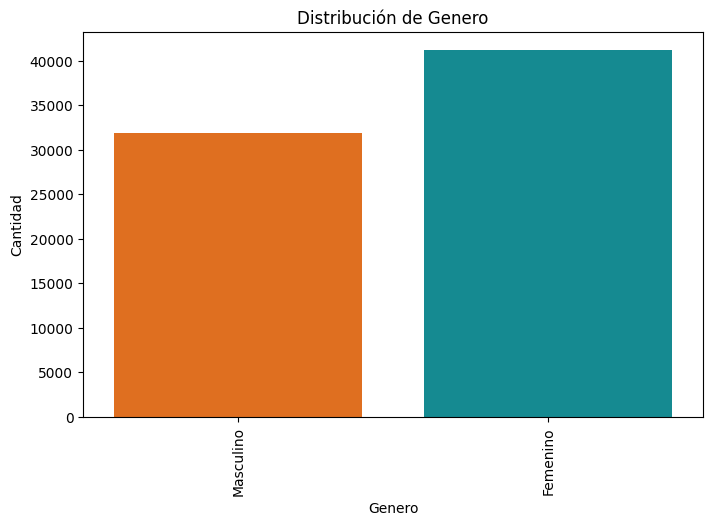


📊 **Estadísticas para Tipo de sistema**:

                 Cantidad  Porcentaje
Tipo de sistema                      
Android             59364       81.27
iOS                 12543       17.17
HarmonyOS            1139        1.56


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


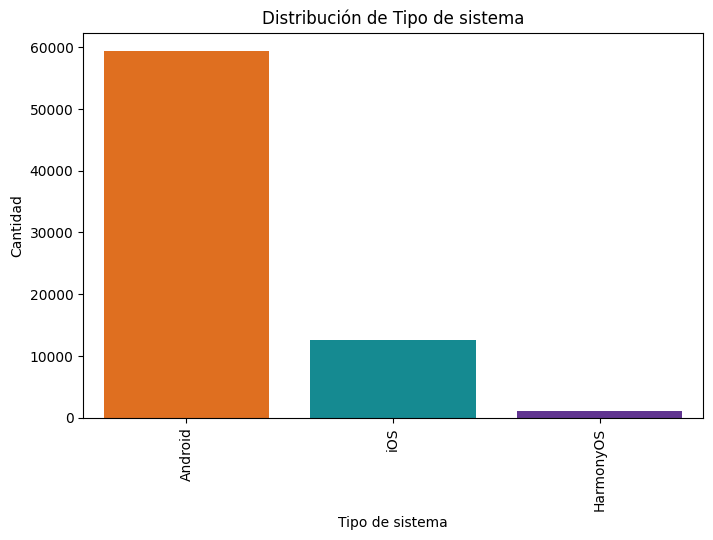

<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(



📊 **Estadísticas para ESTADOPRODUCTO_Corte**:

                      Cantidad  Porcentaje
ESTADOPRODUCTO_Corte                      
Bloqueo Completo             7        0.01
Bloqueo Compliance         285        0.39
Bloqueo Debitos              1        0.00
Cuentas Inactivas        24289       33.25
Icetex Inactiva           1800        2.46
Normal                   46664       63.88


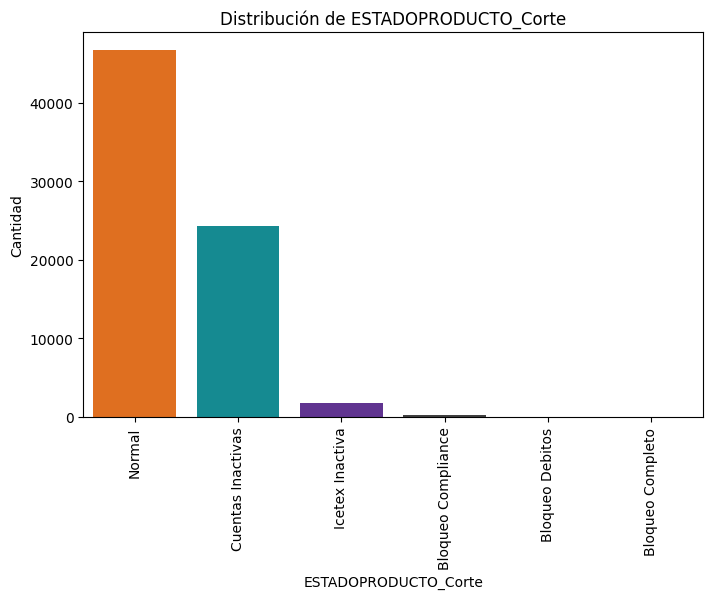

<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(



📊 **Estadísticas para CodTipoVivienda**:

                         Cantidad  Porcentaje
CodTipoVivienda                              
Alquilada                    1082        1.48
Arrendada                    7534       10.31
Familiar                    17835       24.42
Hipotecaria                    32        0.04
No Disponible/Migracion      1425        1.95
Ocupante Autorizado          1607        2.20
Propia                      41970       57.46
Propia con deuda              180        0.25
Propia sin deuda             1320        1.81
Usufructo                      61        0.08


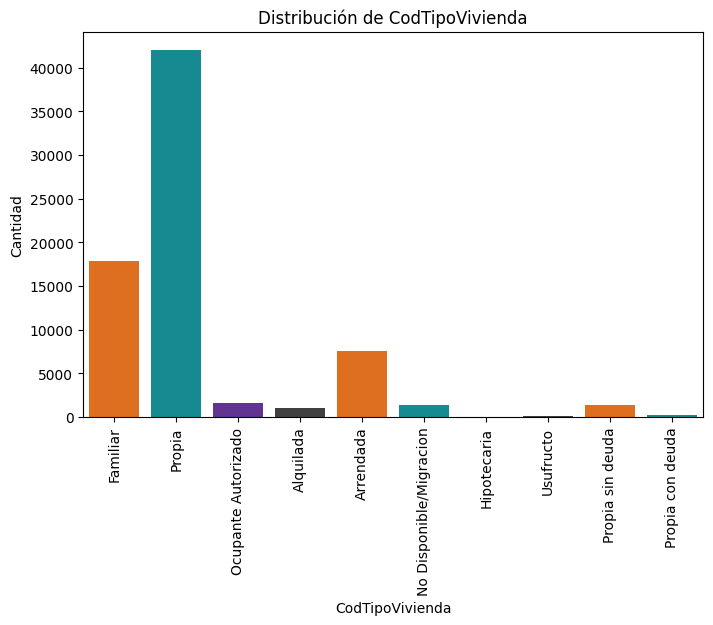


📊 **Estadísticas para EstratoSocial**:

    Cantidad  Porcentaje
0      20810       28.49
1      23532       32.22
2      20265       27.74
3       7356       10.07
4        661        0.90
5        111        0.15
6         40        0.05
99       271        0.37


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


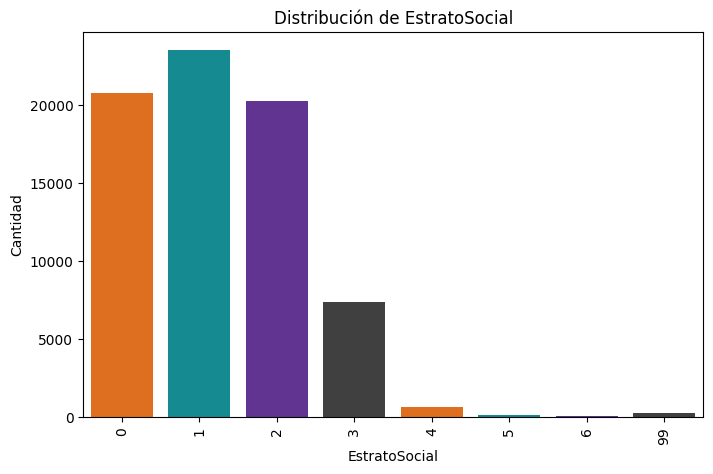


📊 **Estadísticas para Indicador_empleado**:

                    Cantidad  Porcentaje
Indicador_empleado                      
No                     71911       98.45
Si                      1135        1.55


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


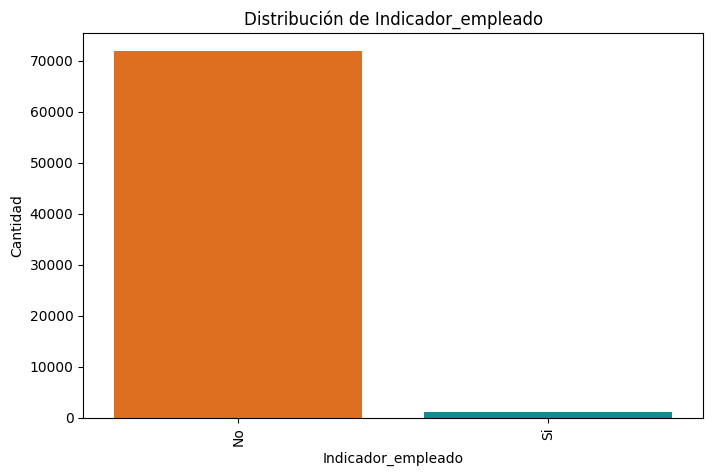


📊 **Estadísticas para MarcaClienteMicroCredito**:

                          Cantidad  Porcentaje
MarcaClienteMicroCredito                      
No                           50297       68.86
Si                           22749       31.14


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


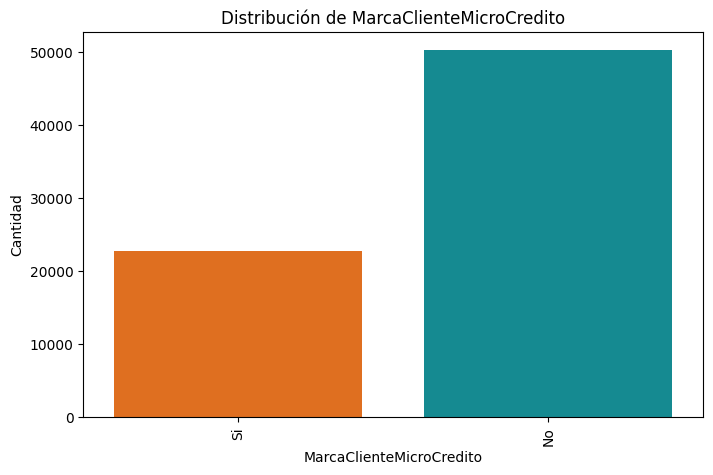


📊 **Estadísticas para Indicador_Giros_Billetera**:

                           Cantidad  Porcentaje
Indicador_Giros_Billetera                      
No                            72613       99.41
Si                              433        0.59


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


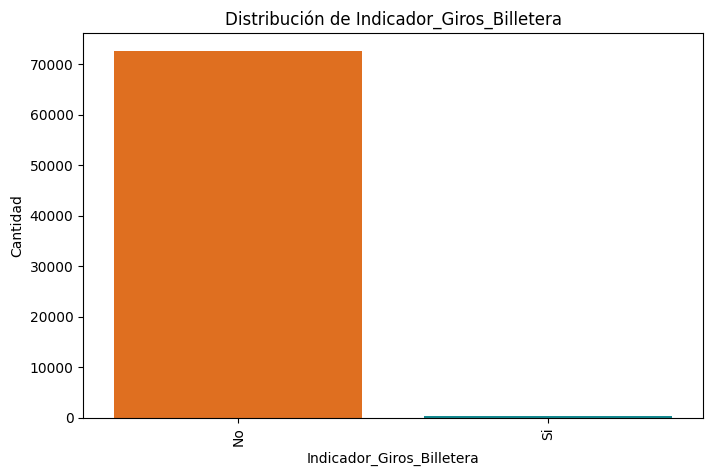


📊 **Estadísticas para tiene_billetera_mercado**:

                         Cantidad  Porcentaje
tiene_billetera_mercado                      
Si                          46363       63.47
No                          26683       36.53


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


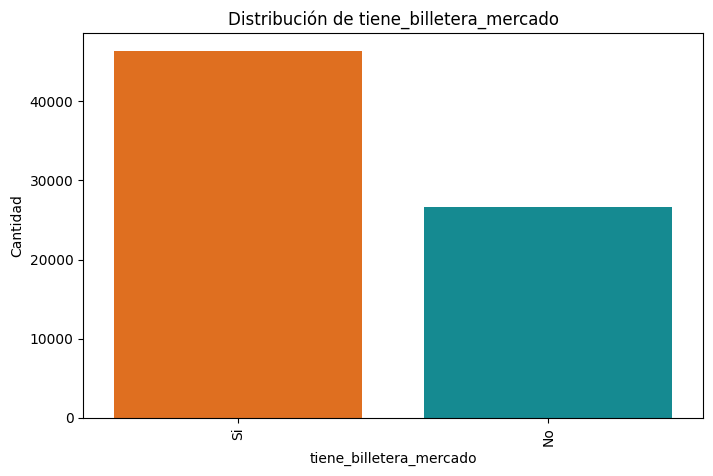


📊 **Estadísticas para DescripcionRegional**:

                     Cantidad  Porcentaje
DescripcionRegional                      
Centro - Oriente        17147       23.47
Centro sur - Llanos      7199        9.86
Eje cafetero            28690       39.28
No Disponible             584        0.80
Región pacífica         19426       26.59


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


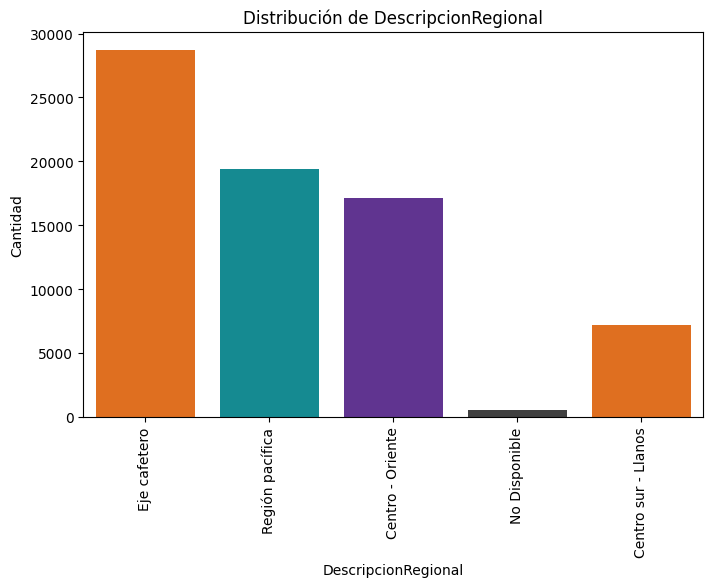

<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(



📊 **Estadísticas para Rangos_Antiguedad_Billeteraw**:

                           Cantidad  Porcentaje
De 1 a menos de 3 meses       14897       20.39
De 12 a menos de 18 meses      8349       11.43
De 3 a menos de 6 meses       20256       27.73
De 6 a menos de 12 meses      21526       29.47
Menos de un mes                4909        6.72
Más de 18 meses                3109        4.26


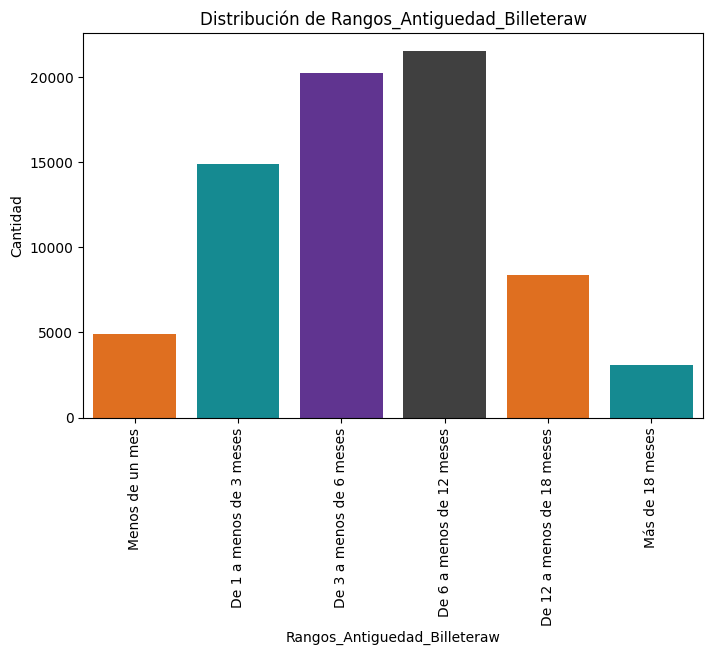


📊 **Estadísticas para Rangos_Saldo_Corte_Enero_2025**:

                       Cantidad  Porcentaje
De $10.001 a $20.000       2482        3.40
De $20.001 a $50.000       3883        5.32
De $5.001 a $10.000        1765        2.42
De $50.001 a $100.000      1576        2.16
Hasta $5000               17310       23.70
Mas de $100.000            3572        4.89
Sin saldo                 42458       58.13


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


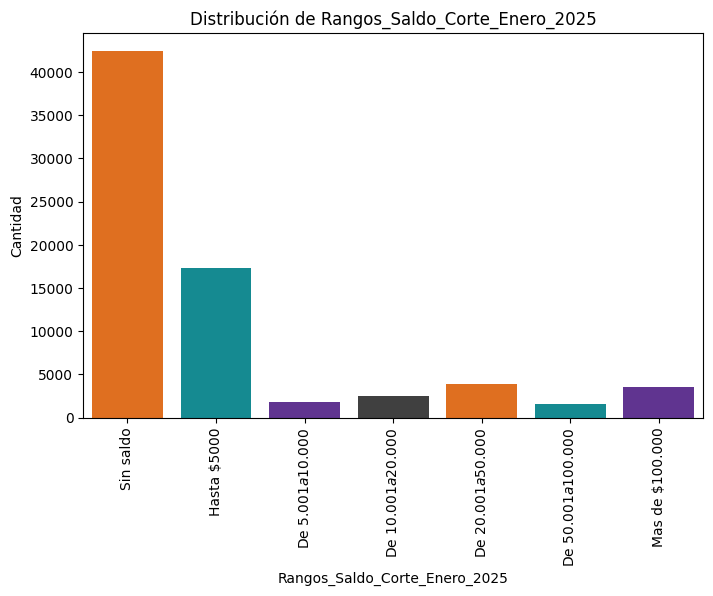


📊 **Estadísticas para Rangos_SaldoPromedio3M**:

                       Cantidad  Porcentaje
De $10.001 a $20.000       2810        3.85
De $20.001 a $50.000       4416        6.05
De $5.001 a $10.000        1998        2.74
De $50.001 a $100.000      1702        2.33
Hasta $5000               16230       22.22
Mas de $100.000            3720        5.09
Sin saldo                 42170       57.73


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


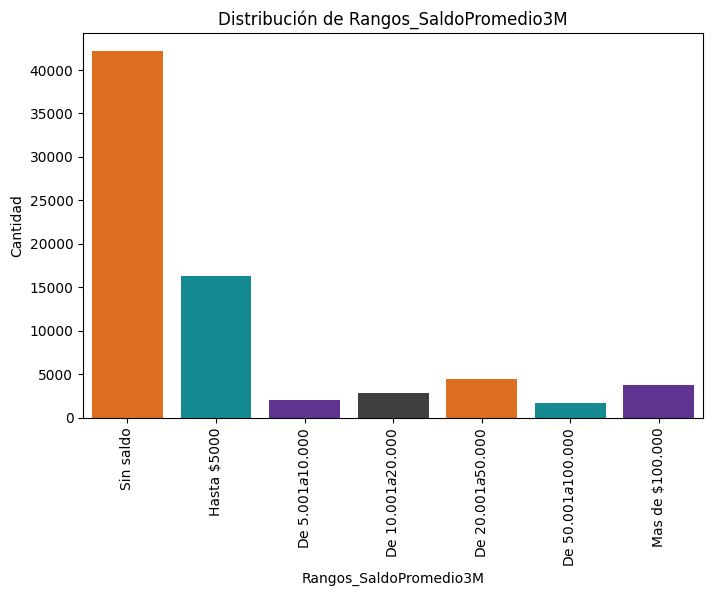


📊 **Estadísticas para Rangos_SaldoPromedio6M**:

                       Cantidad  Porcentaje
De $10.001 a $20.000       3097        4.24
De $20.001 a $50.000       4702        6.44
De $5.001 a $10.000        2191        3.00
De $50.001 a $100.000      1955        2.68
Hasta $5000               15327       20.98
Mas de $100.000            3819        5.23
Sin saldo                 41955       57.44


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


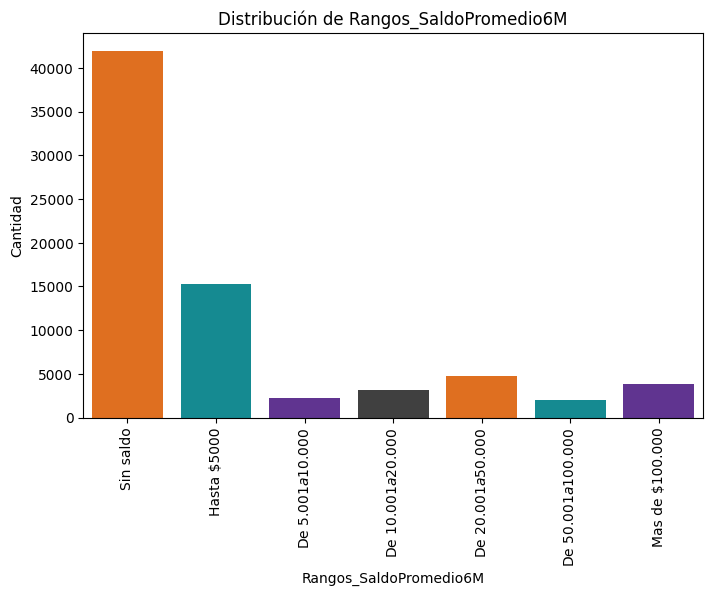


📊 **Estadísticas para Rangos_SaldoPromedio12M**:

                       Cantidad  Porcentaje
De $10.001 a $20.000       3282        4.49
De $20.001 a $50.000       5020        6.87
De $5.001 a $10.000        2293        3.14
De $50.001 a $100.000      2168        2.97
Hasta $5000               14326       19.61
Mas de $100.000            4121        5.64
Sin saldo                 41836       57.27


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


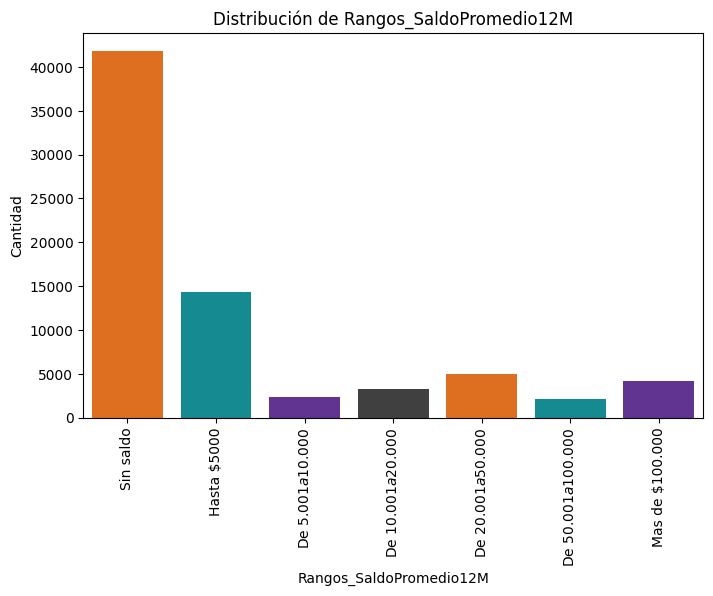


📊 **Estadísticas para Indicador_TM**:

              Cantidad  Porcentaje
Indicador_TM                      
No               63158       86.46
Si                9888       13.54


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


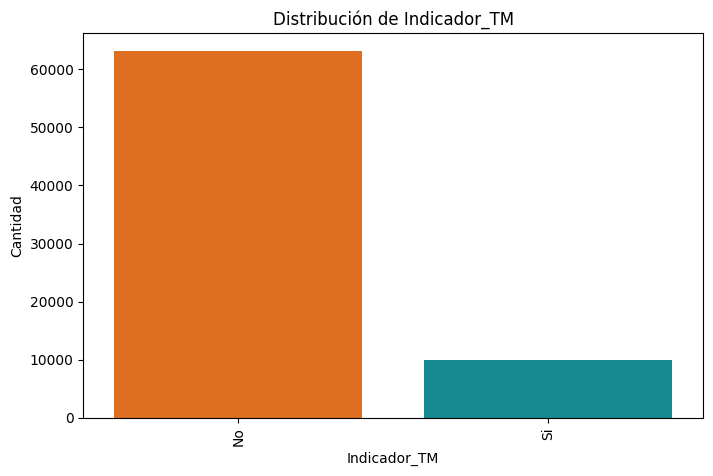


📊 **Estadísticas para indicadorCreditos**:

                   Cantidad  Porcentaje
indicadorCreditos                      
No                    49513       67.78
Si                    23533       32.22


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


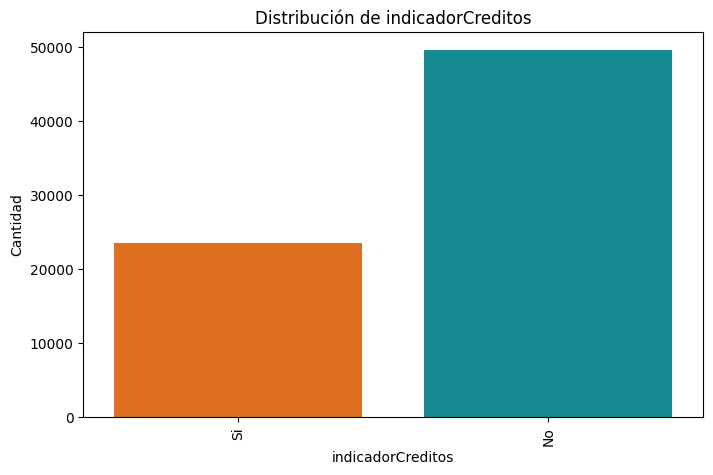


📊 **Estadísticas para indicadorCDT**:

              Cantidad  Porcentaje
indicadorCDT                      
No               71265       97.56
Si                1781        2.44


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


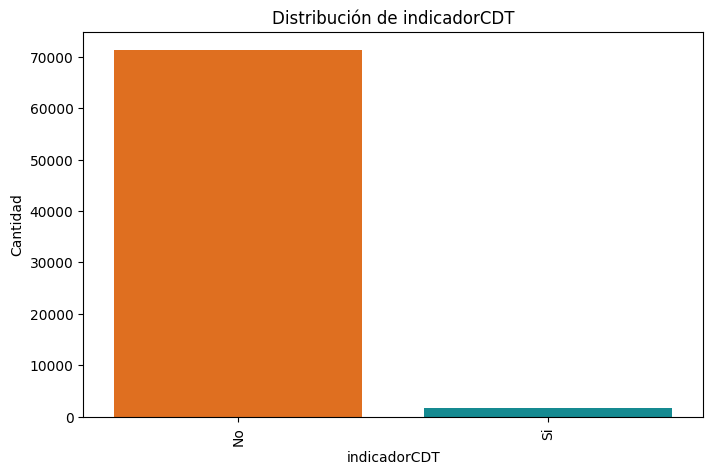


📊 **Estadísticas para indicadorGiros**:

                Cantidad  Porcentaje
indicadorGiros                      
No                 68527       93.81
Si                  4519        6.19


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


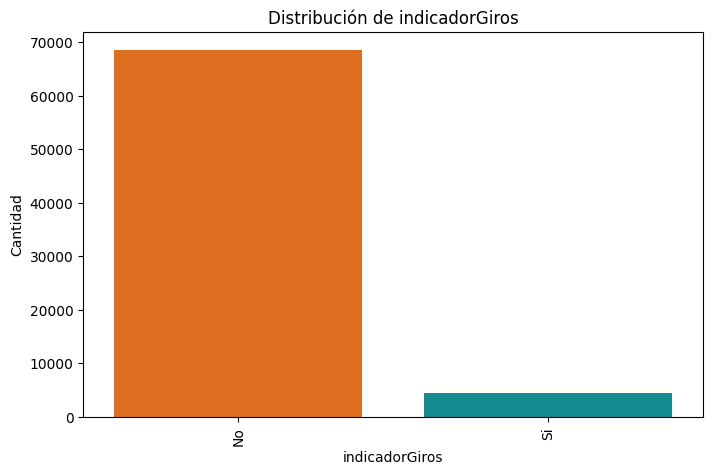


📊 **Estadísticas para indicadorSeguros**:

                  Cantidad  Porcentaje
indicadorSeguros                      
No                   49021       67.11
Si                   24025       32.89


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


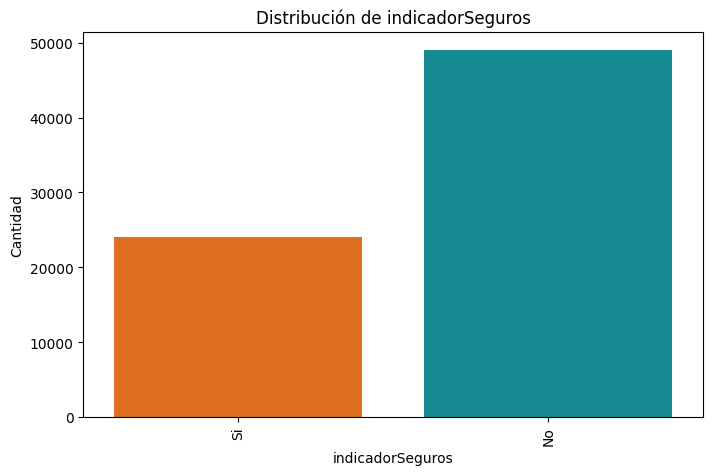


📊 **Estadísticas para exclusivos_billetera**:

                      Cantidad  Porcentaje
exclusivos_billetera                      
No                       38009       52.03
Si                       35037       47.97


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


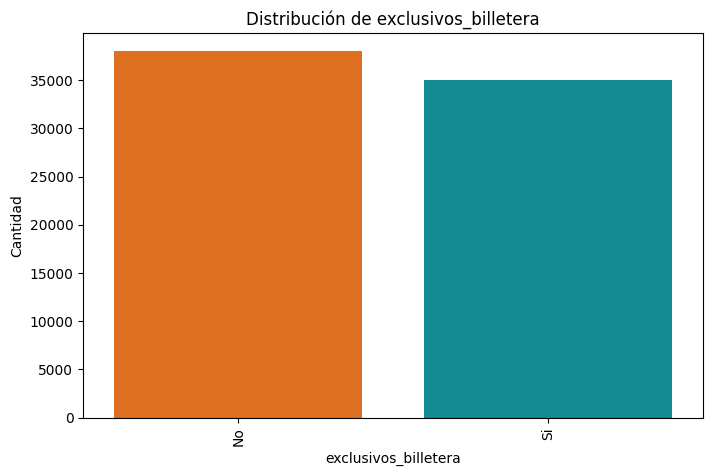


📊 **Estadísticas para Indicador_usuario_fraude**:

                          Cantidad  Porcentaje
Indicador_usuario_fraude                      
No                           72780       99.64
Si                             266        0.36


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


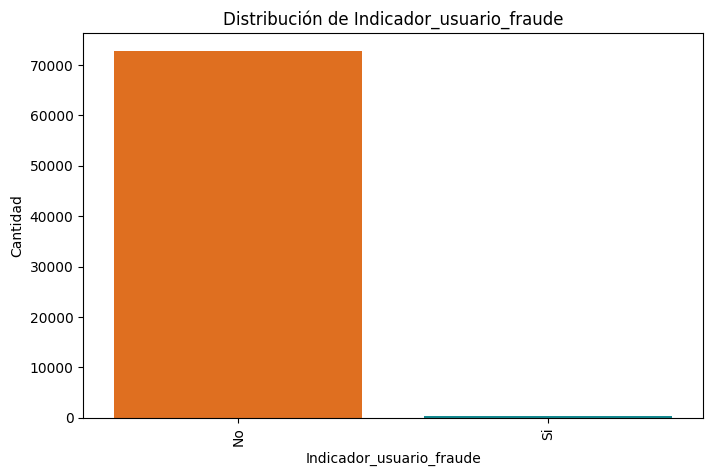


📊 **Estadísticas para Indicador_canal_fisico**:

                        Cantidad  Porcentaje
Indicador_canal_fisico                      
No                         52897       72.42
Si                         20149       27.58


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


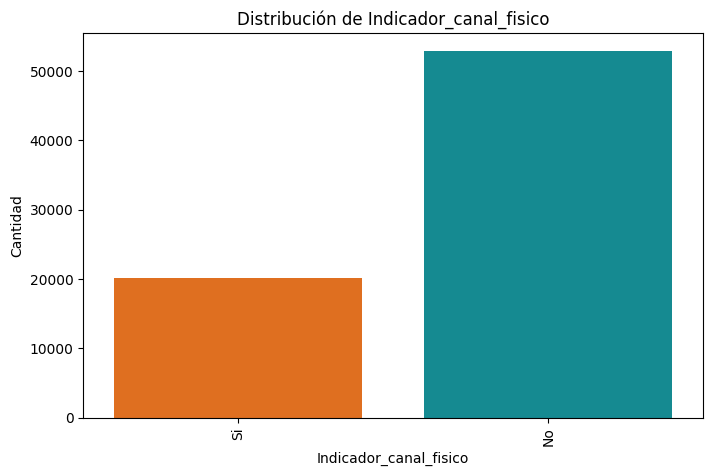


📊 **Estadísticas para Indicador_banca_telefonica**:

                            Cantidad  Porcentaje
Indicador_banca_telefonica                      
No                             69025       94.50
Si                              4021        5.50


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


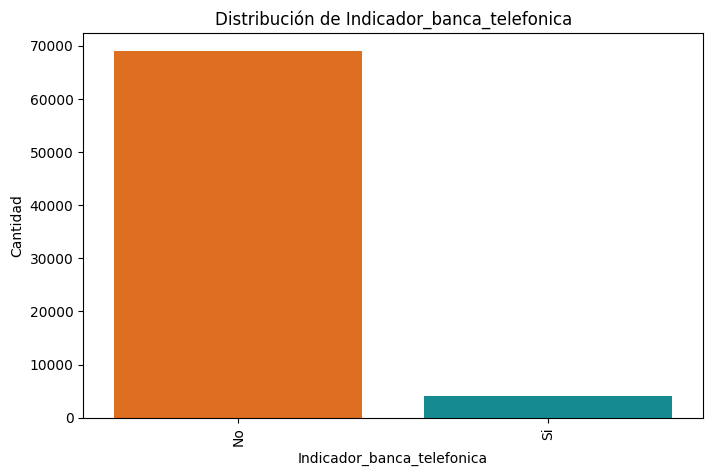


📊 **Estadísticas para TipoCliente_credito**:

                             Cantidad  Porcentaje
TipoCliente_credito                              
Cliente Exclusivo               13550       18.55
Cliente compartido              10144       13.89
Sin Obligación con banco w       3164        4.33
Sin informacion Datacredito     46188       63.23


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


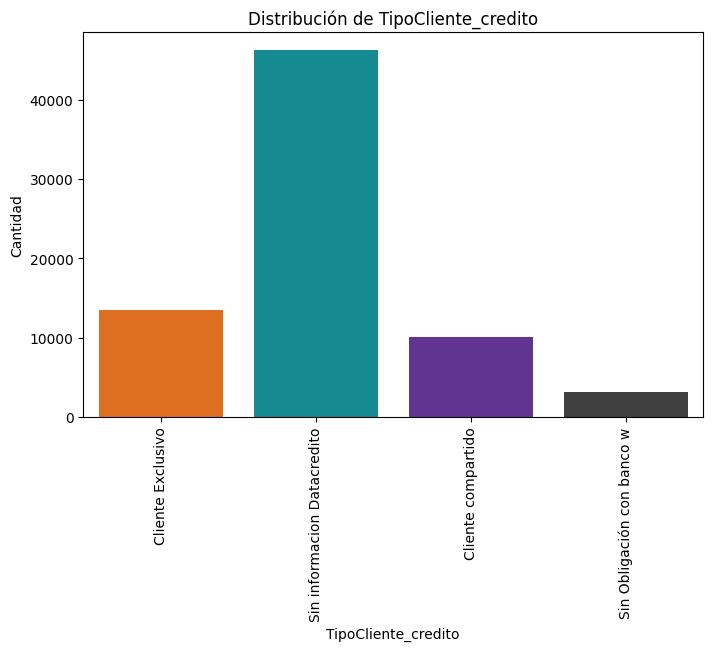


📊 **Estadísticas para Indicador_TNM**:

               Cantidad  Porcentaje
Indicador_TNM                      
No                 8074       11.05
Si                64972       88.95


<ipython-input-13-57d9dc6e5aa3>:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


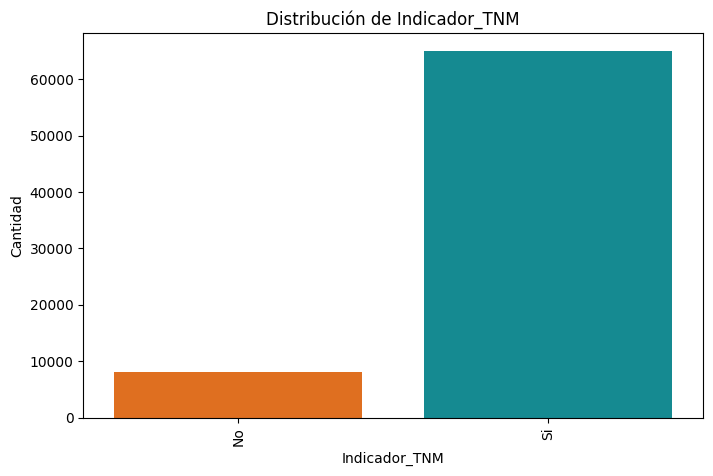

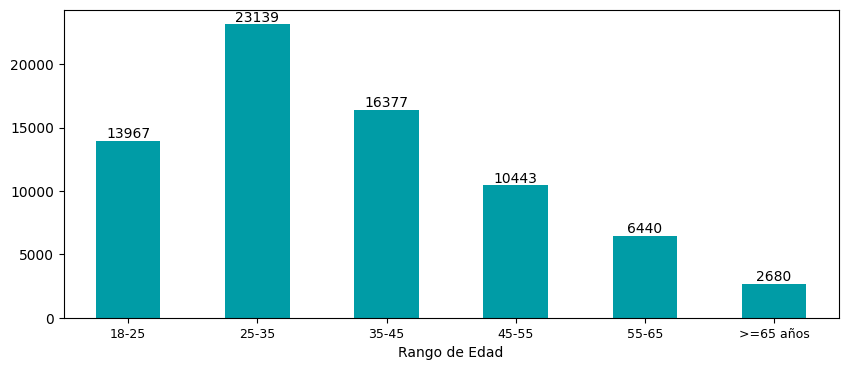

   Edad_Actual Rango_Edad
0        29.62      25-35
1        22.35      18-25
2        21.29      18-25
3        23.83      18-25
4        23.99      18-25
5        23.78      18-25
6        23.12      18-25
7        22.81      18-25
8        30.88      25-35
9        24.96      18-25


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# Lista de variables cualitativas a analizar
variables_cualitativas = [
    "Genero", "Tipo de sistema", "ESTADOPRODUCTO_Corte", "CodTipoVivienda", "EstratoSocial",
    "Indicador_empleado", "MarcaClienteMicroCredito", "Indicador_Giros_Billetera",
    "tiene_billetera_mercado", "DescripcionRegional", "Rangos_Antiguedad_Billeteraw",
    "Rangos_Saldo_Corte_Enero_2025", "Rangos_SaldoPromedio3M", "Rangos_SaldoPromedio6M",
    "Rangos_SaldoPromedio12M", "Indicador_TM", "indicadorCreditos", "indicadorCDT",
    "indicadorGiros", "indicadorSeguros", "exclusivos_billetera", "Indicador_usuario_fraude",
    "Indicador_canal_fisico", "Indicador_banca_telefonica", "TipoCliente_credito", "Indicador_TNM"
]

# Identifico las variables que requieren orden en sus etiquetas
orden_rangos_saldo = [
    "Sin saldo", "Hasta $5000", "De $5.001 a $10.000", "De $10.001 a $20.000", "De $20.001 a $50.000", "De $50.001 a $100.000", "Mas de $100.000"
]

orden_antiguedad = [
    "Menos de un mes", "De 1 a menos de 3 meses", "De 3 a menos de 6 meses", "De 6 a menos de 12 meses", "De 12 a menos de 18 meses", "Más de 18 meses"
]
# Definir colores personalizados
colores = ["#FF6900", "#009CA6", "#5F259F", "#404040"]

# Iterar sobre cada variable y generar estadísticas
for i, var in enumerate(variables_cualitativas):
    plt.figure(figsize=(8, 5))

# Aplicar orden personalizado si la variable es de saldo o antigüedad
    if var in ["Rangos_Saldo_Corte_Enero_2025", "Rangos_SaldoPromedio3M", "Rangos_SaldoPromedio6M", "Rangos_SaldoPromedio12M"]:
        df[var] = pd.Categorical(df[var], categories=orden_rangos_saldo, ordered=True)

    elif var in ["Rangos_Antiguedad_Billeteraw"]:
        df[var] = pd.Categorical(df[var], categories=orden_antiguedad, ordered=True)
    # Contar valores únicos y calcular porcentajes
    conteo = df[var].value_counts()
    porcentaje = df[var].value_counts(normalize=True) * 100

# Contar valores y respetar el orden original si es categoría ordinal
    conteo = df[var].value_counts().reindex(df[var].cat.categories if hasattr(df[var], "cat") else df[var].unique())

    # Crear DataFrame con resultados
    df_estadisticas = pd.DataFrame({"Cantidad": conteo, "Porcentaje": porcentaje})
    print(f"\n📊 **Estadísticas para {var}**:\n")
    print(df_estadisticas)


    # Crear gráfico de barras con colores personalizados
    colores_barras = [colores[i % len(colores)] for i in range(len(conteo))]  # Asigna los colores cíclicamente

# Determinar si la variable tiene categorías ordenadas
    order_values = df[var].cat.categories if hasattr(df[var], "cat") else None

    sns.barplot(
        x=conteo.index.astype(str),
        y=conteo.values,
        palette=colores_barras,
        order=order_values  # Solo aplica order si la variable es categórica
    )

    plt.title(f"Distribución de {var}")
    plt.xlabel(var)
    plt.ylabel("Cantidad")
    plt.xticks(rotation=90)
    plt.show()
#Analizar la Edad y volverla rangos

out = pd.cut(df['Edad_Actual'],
            bins=[18,25,35,45,55,65,np.inf],right=False)
ax = out.value_counts(sort=False).plot.bar(rot=0, color="#009CA6", figsize=(10,4))
ax.set_xticklabels(['18-25', '25-35', '35-45', '45-55', '55-65','>=65 años'],
                   fontdict={'fontsize': 9})
ax.bar_label(ax.containers[0])
ax.set_xlabel('Rango de Edad')
plt.show()

# 🔹 Crear la nueva variable con los rangos de edad (cerrados por la izquierda)
df["Rango_Edad"] = pd.cut(df["Edad_Actual"],
                          bins=[18, 25, 35, 45, 55, 65, np.inf],
                          labels=["18-25", "25-35", "35-45", "45-55", "55-65", ">65 años"],
                          right=False)  # Cerrado por la izquierda

# 🔹 Verificar que la nueva columna se haya creado correctamente
print(df[["Edad_Actual", "Rango_Edad"]].head(10))



In [ ]:
# 📊 Tabla cruzada: conteo de usuarios por Estado del Producto y Género
estado_genero = pd.crosstab(df["ESTADOPRODUCTO_Corte"], df["Genero"])

# 📌 Porcentajes por columna (por género)
estado_genero_pct = estado_genero.div(estado_genero.sum(axis=0), axis=1).round(4) * 100

# 🔍 Mostrar resultados
print("🔢 Conteo de usuarios por Estado del Producto y Género:\n")
print(estado_genero)

print("\n📊 Porcentaje por Género (%):\n")
print(estado_genero_pct)


🔢 Conteo de usuarios por Estado del Producto y Género:

Genero                Femenino  Masculino
ESTADOPRODUCTO_Corte                     
Bloqueo Completo             3          4
Bloqueo Compliance         123        162
Bloqueo Debitos              0          1
Cuentas Inactivas        13193      11096
Icetex Inactiva            928        872
Normal                   26943      19721

📊 Porcentaje por Género (%):

Genero                Femenino  Masculino
ESTADOPRODUCTO_Corte                     
Bloqueo Completo          0.01       0.01
Bloqueo Compliance        0.30       0.51
Bloqueo Debitos           0.00       0.00
Cuentas Inactivas        32.03      34.83
Icetex Inactiva           2.25       2.74
Normal                   65.41      61.91


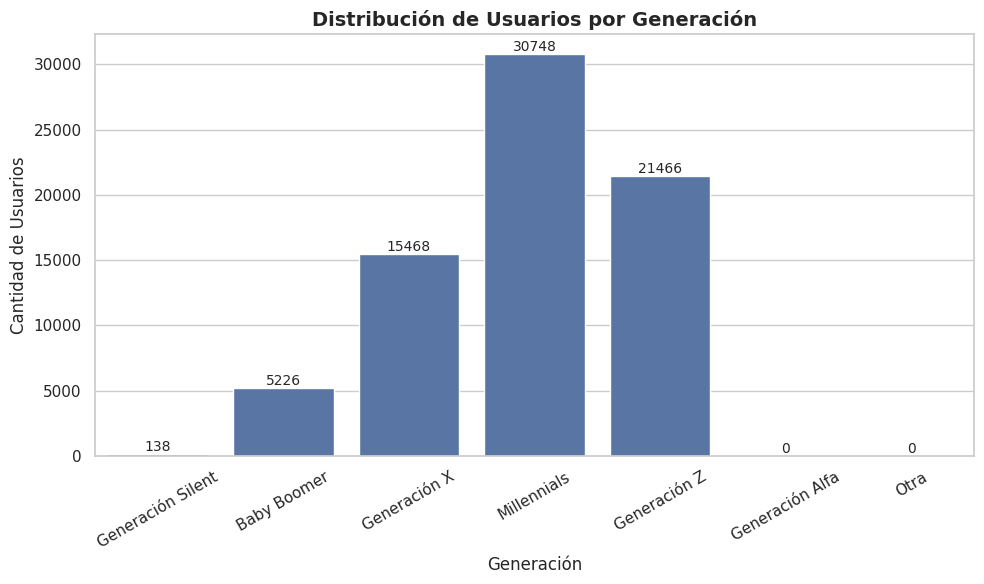

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo visual limpio
sns.set(style="whitegrid")

# Contar valores por generación
conteo_generaciones = df["Generacion"].value_counts().sort_index()

# Crear gráfico de barras
plt.figure(figsize=(10, 6))
ax = sns.barplot(x=conteo_generaciones.index,
                 y=conteo_generaciones.values)

# Etiquetas en cada barra
ax.bar_label(ax.containers[0], fontsize=10)

# Títulos y etiquetas
plt.title("Distribución de Usuarios por Generación", fontsize=14, fontweight="bold")
plt.xlabel("Generación")
plt.ylabel("Cantidad de Usuarios")
plt.xticks(rotation=30)
plt.tight_layout()

# Mostrar gráfico
plt.show()



📊 **Top 5 Ciudades con Más Usuarios de Billetera:**

            Cantidad  Porcentaje
Cod_Ciudad                      
Bogotá          9794       40.10
Cali            8660       35.45
Medellín        2261        9.26
Ibagué          2146        8.79
Cúcuta          1565        6.41


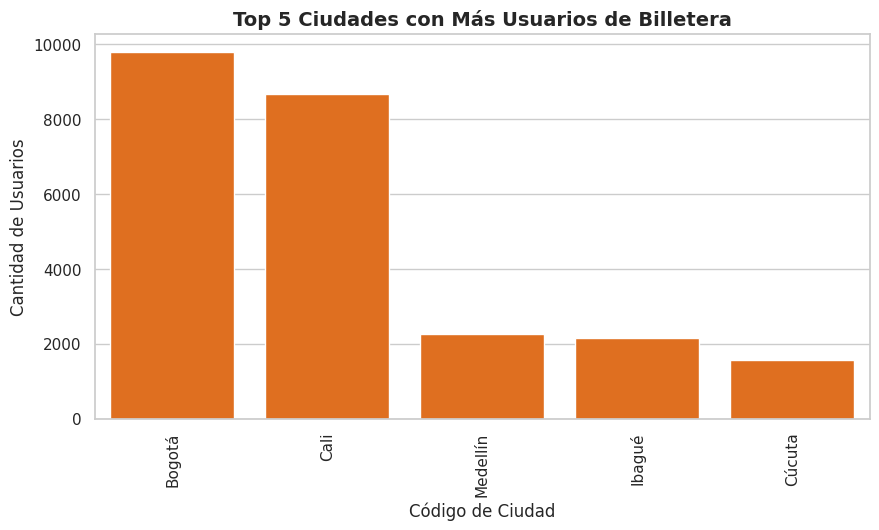

In [ ]:
# 📊 Contar la cantidad de usuarios por ciudad
top_ciudades = df["Cod_Ciudad"].value_counts().head(5)  # Top 5

# 📌 Calcular porcentaje
top_ciudades_porcentaje = (top_ciudades / top_ciudades.sum()) * 100

# 📊 Crear un DataFrame con los resultados
top_ciudades_df = pd.DataFrame({"Cantidad": top_ciudades, "Porcentaje": top_ciudades_porcentaje.round(2)})

# 🔥 Mostrar resumen en conteo y porcentaje
print("\n📊 **Top 5 Ciudades con Más Usuarios de Billetera:**\n")
print(top_ciudades_df)

# 📈 Gráfico de Barras con color personalizado
plt.figure(figsize=(10, 5))
sns.barplot(x=top_ciudades.index, y=top_ciudades.values, color="#FF6900")  # Aplicamos el color del banco

# 📌 Configurar etiquetas y título
plt.title("Top 5 Ciudades con Más Usuarios de Billetera", fontsize=14, fontweight="bold")
plt.xlabel("Código de Ciudad")
plt.ylabel("Cantidad de Usuarios")
plt.xticks(rotation=90) # changed plt.xt to plt.xticks(rotation=90) to rotate x-axis labels
plt.show() # added plt.show() to display the plot

In [ ]:
# 📊 Agrupar por ciudad y calcular suma, promedio y conteo de usuarios
top_ciudades_saldo = df.groupby("Cod_Ciudad").agg(
    Saldo_Total=("SALDO_Corte_Enero_2025", "sum"),
    Saldo_Promedio=("SALDO_Corte_Enero_2025", "mean"),
    Cantidad_Usuarios=("Cod_Ciudad", "count")  # Cuenta cuántos usuarios hay por ciudad
).sort_values(by="Saldo_Total", ascending=False).head(10)

# 📌 Calcular porcentaje del saldo total de cada ciudad respecto al total general
top_ciudades_saldo["Porcentaje_Saldo"] = (top_ciudades_saldo["Saldo_Total"] / top_ciudades_saldo["Saldo_Total"].sum()) * 100

# 🔥 Mostrar resumen en consola
print("\n📊 **Top 10 Ciudades con Mayor Saldo en Billetera:**\n")
print(top_ciudades_saldo.round(2))



📊 **Top 10 Ciudades con Mayor Saldo en Billetera:**

                        Saldo_Total  Saldo_Promedio  Cantidad_Usuarios  \
Cod_Ciudad                                                               
Cali                 623,661,082.74       72,016.29               8660   
Bogotá               325,690,596.92       33,254.09               9794   
Cartagena del Chairá  75,473,890.52      210,820.92                358   
Palmira               70,123,956.84       50,594.49               1386   
Leticia               56,317,059.36      233,680.74                241   
Villavicencio         53,714,811.33       47,874.16               1122   
Barranquilla          50,395,717.25       32,284.25               1561   
Jamundí               49,526,348.50       96,731.15                512   
Cúcuta                49,125,924.30       31,390.37               1565   
Yumbo                 45,718,192.52      126,994.98                360   

                      Porcentaje_Saldo  
Cod_Ciudad      

In [ ]:
# 💾 Guardar el DataFrame en Excel
top_ciudades_saldo.to_excel("Top10_Ciudades_Saldo.xlsx", index=False)

# 📥 Descargar el archivo a tu máquina local
from google.colab import files
files.download("Top10_Ciudades_Saldo.xlsx")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# DataFrame con ciudad, latitud y longitud
coordenadas_df = pd.DataFrame({
    "Cod_Ciudad": [
        "Bogotá", "Palmira", "Cali", "Barranquilla", "Cartagena del Chairá",
        "Leticia", "Villavicencio", "Jamundí", "Cúcuta", "Yumbo"
    ],
    "Latitud": [
        4.649251, 3.531544, 3.413686, 10.977961, 1.332371,
        -4.19895, 4.126369, 3.258751, 7.905725, 3.540097
    ],
    "Longitud": [
        -74.106992, -76.298846, -76.52133, -74.815546, -74.847867,
        -69.941721, -73.622601, -76.538472, -72.508178, -76.499893
    ]
})


In [ ]:
print(coordenadas_df)

             Cod_Ciudad  Latitud  Longitud
0                Bogotá     4.65    -74.11
1               Palmira     3.53    -76.30
2                  Cali     3.41    -76.52
3          Barranquilla    10.98    -74.82
4  Cartagena del Chairá     1.33    -74.85
5               Leticia    -4.20    -69.94
6         Villavicencio     4.13    -73.62
7               Jamundí     3.26    -76.54
8                Cúcuta     7.91    -72.51
9                 Yumbo     3.54    -76.50


In [ ]:
# Agrupar y renombrar
saldos_df = df.groupby("Cod_Ciudad")["SALDO_Corte_Enero_2025"].sum().reset_index()
saldos_df.rename(columns={"SALDO_Corte_Enero_2025": "Monto_Total"}, inplace=True)

# Ordenar de mayor a menor y quedarte con el top 10
saldos_top10 = saldos_df.sort_values(by="Monto_Total", ascending=False).head(10).reset_index(drop=True)
print(saldos_top10)


             Cod_Ciudad    Monto_Total
0                  Cali 623,661,082.74
1                Bogotá 325,690,596.92
2  Cartagena del Chairá  75,473,890.52
3               Palmira  70,123,956.84
4               Leticia  56,317,059.36
5         Villavicencio  53,714,811.33
6          Barranquilla  50,395,717.25
7               Jamundí  49,526,348.50
8                Cúcuta  49,125,924.30
9                 Yumbo  45,718,192.52


In [ ]:
# Unir top 10 ciudades con sus coordenadas
ciudades_monto_final = pd.merge(saldos_top10, coordenadas_df, on="Cod_Ciudad", how="inner")

# Verificar que todo salió bien
print(ciudades_monto_final)


             Cod_Ciudad    Monto_Total  Latitud  Longitud
0                  Cali 623,661,082.74     3.41    -76.52
1                Bogotá 325,690,596.92     4.65    -74.11
2  Cartagena del Chairá  75,473,890.52     1.33    -74.85
3               Palmira  70,123,956.84     3.53    -76.30
4               Leticia  56,317,059.36    -4.20    -69.94
5         Villavicencio  53,714,811.33     4.13    -73.62
6          Barranquilla  50,395,717.25    10.98    -74.82
7               Jamundí  49,526,348.50     3.26    -76.54
8                Cúcuta  49,125,924.30     7.91    -72.51
9                 Yumbo  45,718,192.52     3.54    -76.50


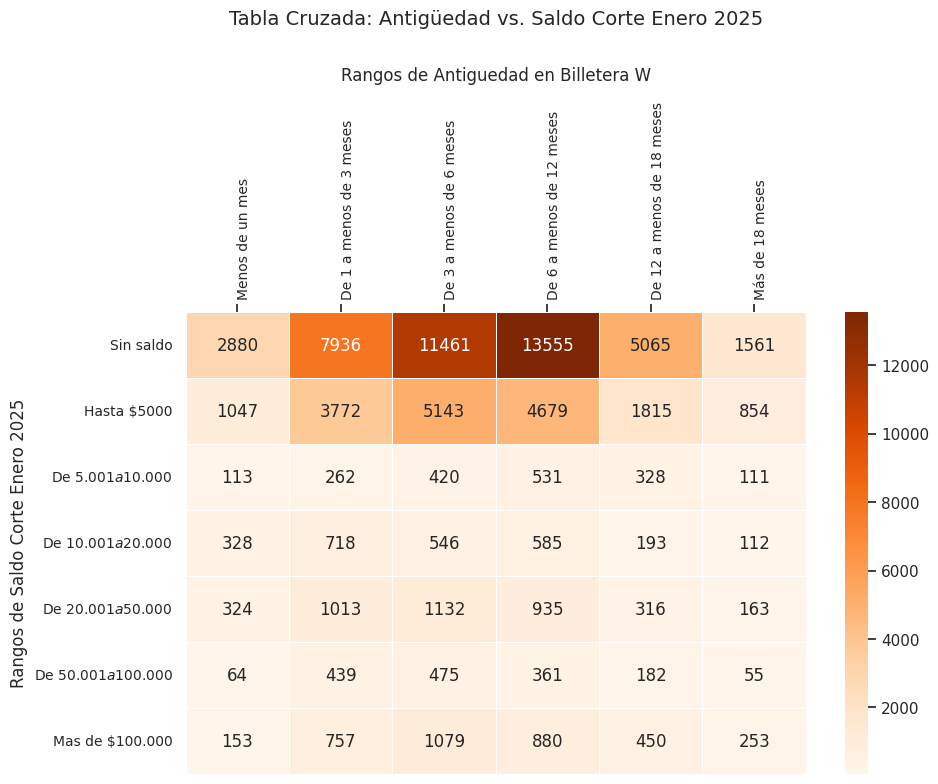

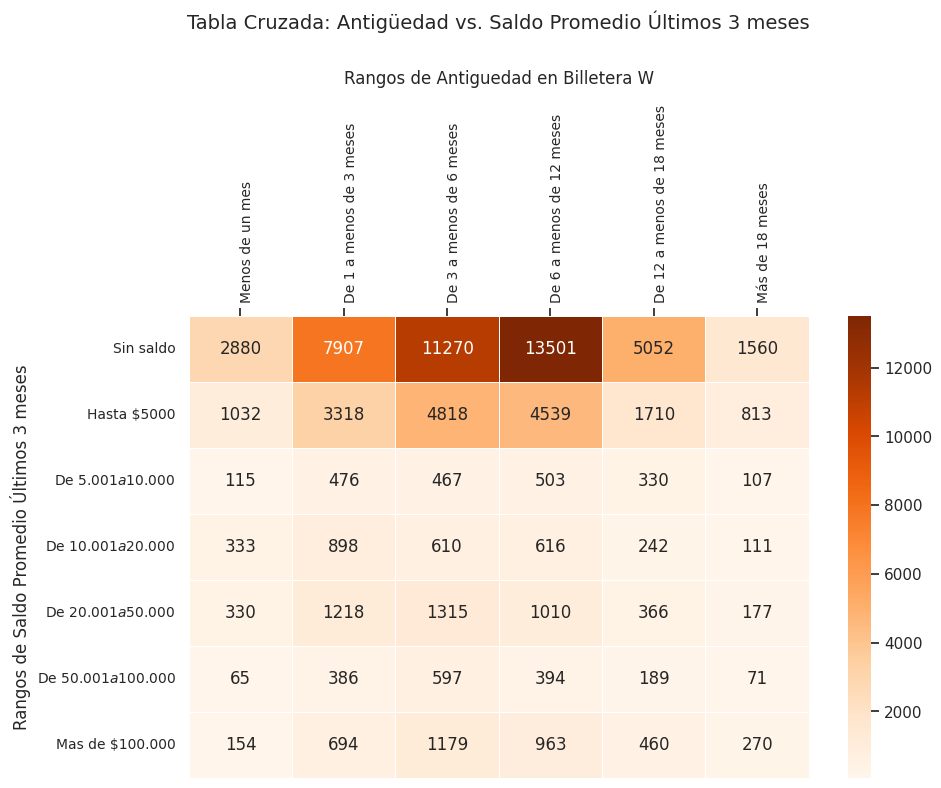

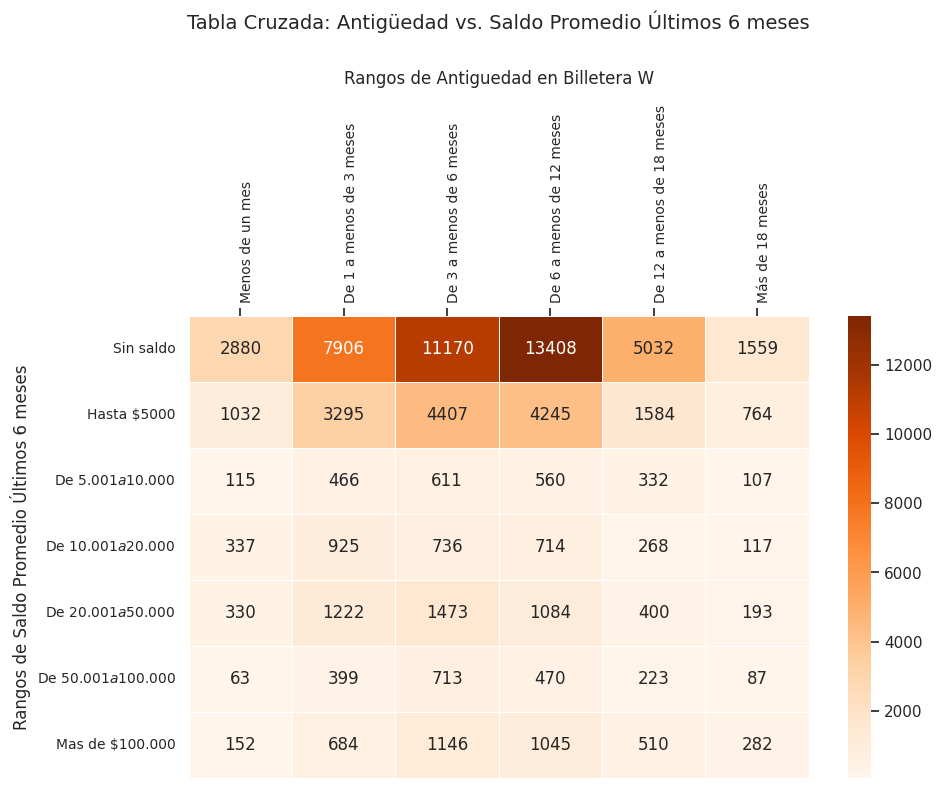

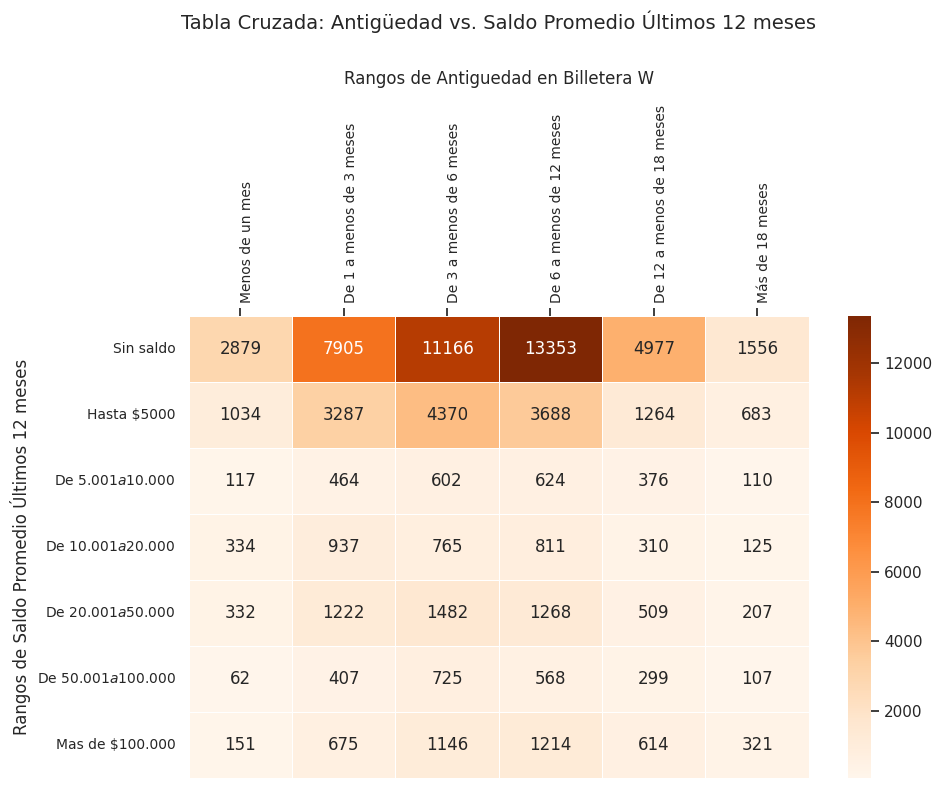

In [ ]:
# Lista de columnas de saldo y títulos para los gráficos
columnas_saldo = [
    ("Rangos_Saldo_Corte_Enero_2025", "Saldo Corte Enero 2025"),
    ("Rangos_SaldoPromedio3M", "Saldo Promedio Últimos 3 meses"),
    ("Rangos_SaldoPromedio6M", "Saldo Promedio Últimos 6 meses"),
    ("Rangos_SaldoPromedio12M", "Saldo Promedio Últimos 12 meses")
]

# Función para generar mapa de calor
def generar_mapa_calor(df, columna_saldo, titulo):
    tabla_cruzada = pd.crosstab(df[columna_saldo], df["Rangos_Antiguedad_Billeteraw"])

    plt.figure(figsize=(10, 6))
    ax = sns.heatmap(tabla_cruzada, annot=True, fmt="d", cmap="Oranges", linewidths=0.5)

    # Mover etiquetas del eje X a la parte superior
    ax.xaxis.set_label_position('top')
    ax.xaxis.tick_top()

    # Configurar títulos y etiquetas con separación
    plt.title(f"Tabla Cruzada: Antigüedad vs. {titulo}", pad=30, fontsize=14)  # Aumenta el espacio
    plt.xlabel(f"Rangos de Antiguedad en Billetera W", labelpad=15, fontsize=12)  # Espacio extra para la etiqueta del eje X
    plt.ylabel(f"Rangos de {titulo}", fontsize=12)

    # Ajustar la separación de los ticks
    plt.xticks(rotation=90, ha="left", fontsize=10)  # Rotar y alinear los ticks del eje X
    plt.yticks(fontsize=10)  # Ajustar el tamaño de los ticks del eje Y

    plt.show()

# Generar gráficos con un bucle
for columna, titulo in columnas_saldo:
    generar_mapa_calor(df, columna, titulo)



📊 **Frecuencias Absolutas:**

Indicador_canal_fisico     No     Si
Indicador_TM                        
No                      46630  16528
Si                       6267   3621

📊 **Porcentajes (%):**

Indicador_canal_fisico    No    Si
Indicador_TM                      
No                     63.84 22.63
Si                      8.58  4.96


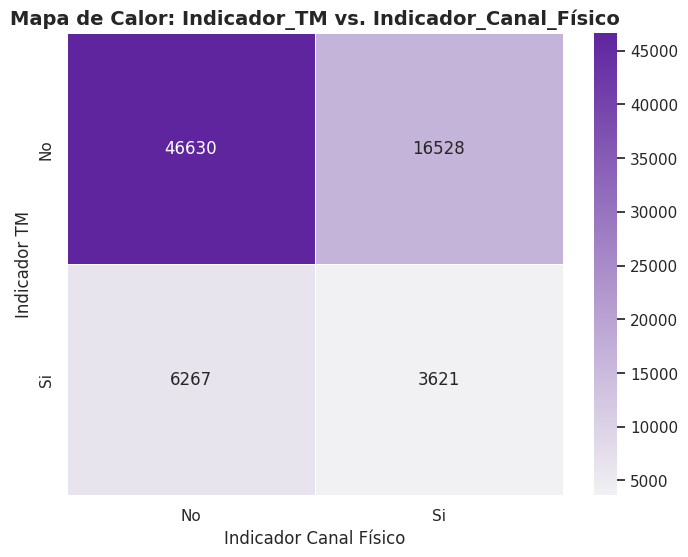

In [ ]:
# 📊 Crear tabla cruzada con frecuencias absolutas
tabla_cruzada = pd.crosstab(df["Indicador_TM"], df["Indicador_canal_fisico"])

# 📌 Crear tabla cruzada con porcentajes (sobre el total)
tabla_porcentaje = pd.crosstab(df["Indicador_TM"], df["Indicador_canal_fisico"], normalize="all") * 100

# 📊 Mostrar frecuencias absolutas y porcentajes
print("\n📊 **Frecuencias Absolutas:**\n")
print(tabla_cruzada)

print("\n📊 **Porcentajes (%):**\n")
print(tabla_porcentaje.round(2))  # Redondeamos a 2 decimales para mejor lectura

# 🎨 Definir el color personalizado (#5F259F / Pantone 267 C)
color_custom = "#5F259F"

# 🔥 Generar el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(tabla_cruzada, annot=True, fmt="d", cmap=sns.light_palette(color_custom, as_cmap=True), linewidths=0.5)

# 📌 Configurar títulos y etiquetas
plt.title("Mapa de Calor: Indicador_TM vs. Indicador_Canal_Físico", fontsize=14, fontweight="bold")
plt.xlabel("Indicador Canal Físico")
plt.ylabel("Indicador TM")

# 📊 Mostrar gráfico
plt.show()



📊 **Frecuencias Absolutas:**

Rangos_Saldo_Corte_Enero_2025  Sin saldo  Hasta $5000  De $5.001 a $10.000  \
ESTADOPRODUCTO_Corte                                                         
Bloqueo Completo                       0            7                    0   
Bloqueo Compliance                   118           79                   11   
Bloqueo Debitos                        0            0                    0   
Cuentas Inactivas                  19830         2998                  290   
Icetex Inactiva                       14         1083                  247   
Normal                             22496        13143                 1217   

Rangos_Saldo_Corte_Enero_2025  De $10.001 a $20.000  De $20.001 a $50.000  \
ESTADOPRODUCTO_Corte                                                        
Bloqueo Completo                                  0                     0   
Bloqueo Compliance                               41                    17   
Bloqueo Debitos                     

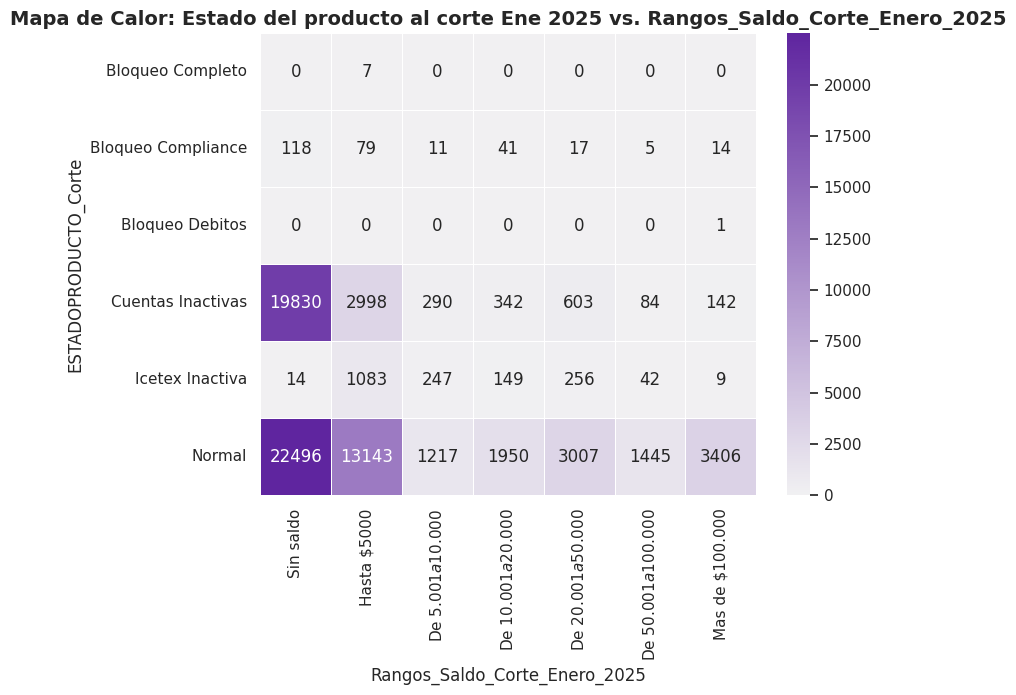

In [ ]:
# 📊 Crear tabla cruzada con frecuencias absolutas
tabla_cruzada = pd.crosstab(df["ESTADOPRODUCTO_Corte"], df["Rangos_Saldo_Corte_Enero_2025"])

# 📌 Crear tabla cruzada con porcentajes (sobre el total)
tabla_porcentaje = pd.crosstab(df["ESTADOPRODUCTO_Corte"], df["Rangos_Saldo_Corte_Enero_2025"], normalize="all") * 100

# 📊 Mostrar frecuencias absolutas y porcentajes
print("\n📊 **Frecuencias Absolutas:**\n")
print(tabla_cruzada)

print("\n📊 **Porcentajes (%):**\n")
print(tabla_porcentaje.round(2))  # Redondeamos a 2 decimales para mejor lectura

# 🎨 Definir el color personalizado (#5F259F / Pantone 267 C)
color_custom = "#5F259F"

# 🔥 Generar el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(tabla_cruzada, annot=True, fmt="d", cmap=sns.light_palette(color_custom, as_cmap=True), linewidths=0.5)

# 📌 Configurar títulos y etiquetas
plt.title("Mapa de Calor: Estado del producto al corte Ene 2025 vs. Rangos_Saldo_Corte_Enero_2025", fontsize=14, fontweight="bold")
plt.xlabel("Rangos_Saldo_Corte_Enero_2025")
plt.ylabel("ESTADOPRODUCTO_Corte")

# 📊 Mostrar gráfico
plt.show()

📊 Frecuencia Absoluta:
exclusivos_billetera        No     Si
tiene_billetera_mercado              
No                        9295  17388
Si                       28714  17649

📈 Porcentaje por Fila (%):
exclusivos_billetera       No    Si
tiene_billetera_mercado            
No                      34.83 65.17
Si                      61.93 38.07


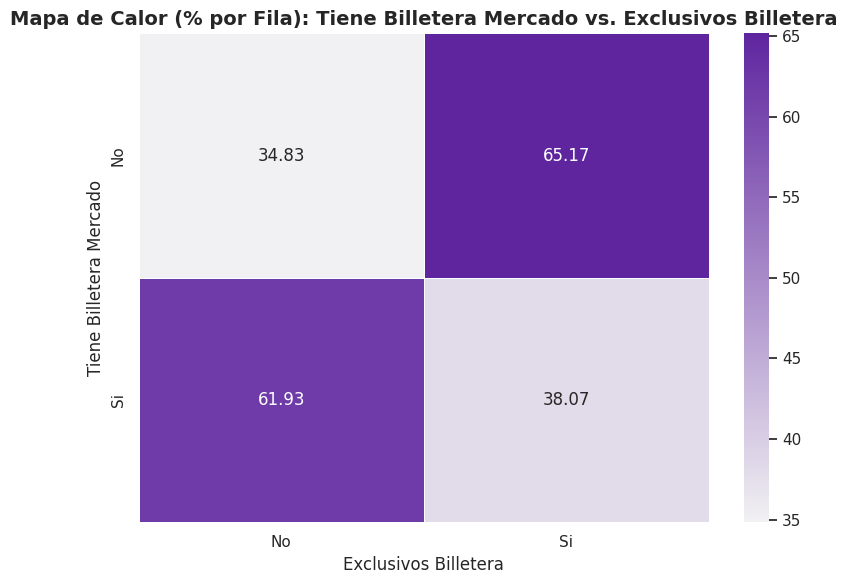

In [ ]:
# 📊 Tabla de frecuencias absolutas
tabla_cruzada = pd.crosstab(df["tiene_billetera_mercado"], df["exclusivos_billetera"])

# 📌 Porcentaje por fila (cada fila suma 100%)
tabla_porcentaje_fila = pd.crosstab(df["tiene_billetera_mercado"],
                                     df["exclusivos_billetera"],
                                     normalize="index") * 100

# 🔍 Mostrar tablas
print("📊 Frecuencia Absoluta:")
print(tabla_cruzada)
print("\n📈 Porcentaje por Fila (%):")
print(tabla_porcentaje_fila.round(2))

# 🎨 Mapa de calor con % por fila
plt.figure(figsize=(8, 6))
sns.heatmap(tabla_porcentaje_fila.round(2), annot=True, fmt=".2f",
            cmap=sns.light_palette("#5F259F", as_cmap=True), linewidths=0.5)

# 🏷 Etiquetas y título
plt.title("Mapa de Calor (% por Fila): Tiene Billetera Mercado vs. Exclusivos Billetera", fontsize=14, fontweight="bold")
plt.xlabel("Exclusivos Billetera")
plt.ylabel("Tiene Billetera Mercado")

# Mostrar gráfico
plt.tight_layout()
plt.show()


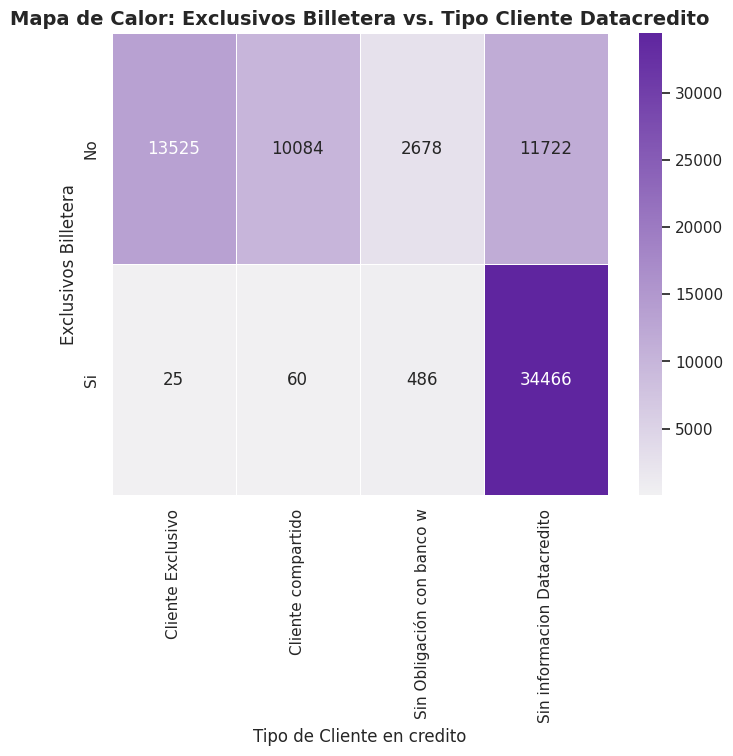

In [ ]:

# 📊 Crear tabla cruzada con frecuencias absolutas
tabla_cruzada = pd.crosstab(df["exclusivos_billetera"], df["TipoCliente_credito"])

# 📌 Crear tabla cruzada con porcentajes (sobre el total)
tabla_porcentaje = pd.crosstab(df["exclusivos_billetera"], df["TipoCliente_credito"], normalize="all") * 100


# 🎨 Definir el color personalizado (#5F259F / Pantone 267 C)
color_custom = "#5F259F"

# 🔥 Generar el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(tabla_cruzada, annot=True, fmt="d", cmap=sns.light_palette(color_custom, as_cmap=True), linewidths=0.5)

# 📌 Configurar títulos y etiquetas
plt.title("Mapa de Calor: Exclusivos Billetera vs. Tipo Cliente Datacredito", fontsize=14, fontweight="bold")
plt.xlabel("Tipo de Cliente en credito")
plt.ylabel("Exclusivos Billetera")

# 📊 Mostrar gráfico
plt.show()


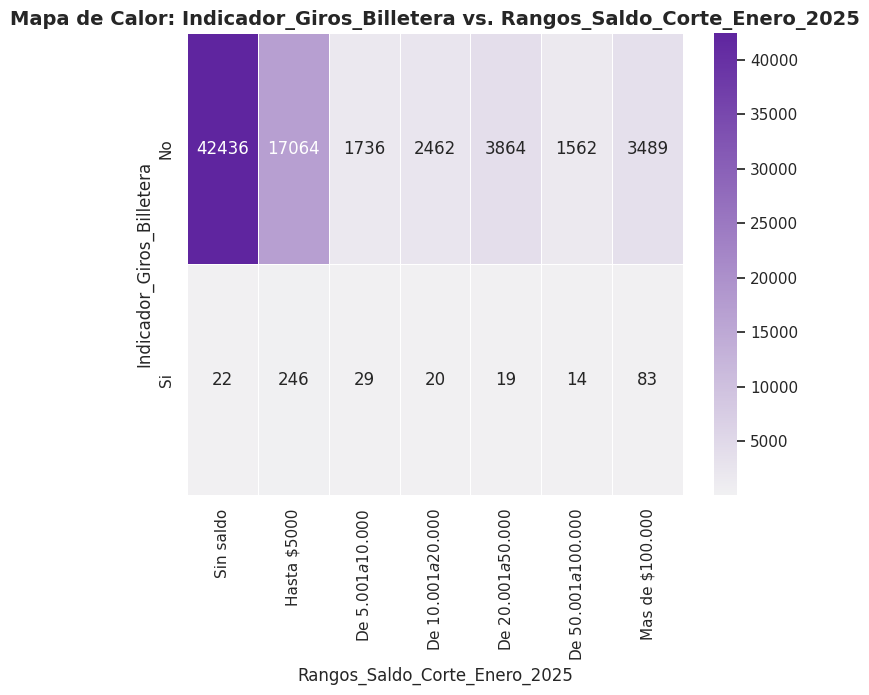

In [ ]:
# 📊 Crear tabla cruzada con frecuencias absolutas
tabla_cruzada = pd.crosstab(df["Indicador_Giros_Billetera"], df["Rangos_Saldo_Corte_Enero_2025"])

# 📌 Crear tabla cruzada con porcentajes (sobre el total)
tabla_porcentaje = pd.crosstab(df["Indicador_Giros_Billetera"], df["Rangos_Saldo_Corte_Enero_2025"], normalize="all") * 100


# 🎨 Definir el color personalizado (#5F259F / Pantone 267 C)
color_custom = "#5F259F"

# 🔥 Generar el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(tabla_cruzada, annot=True, fmt="d", cmap=sns.light_palette(color_custom, as_cmap=True), linewidths=0.5)

# 📌 Configurar títulos y etiquetas
plt.title("Mapa de Calor: Indicador_Giros_Billetera vs. Rangos_Saldo_Corte_Enero_2025", fontsize=14, fontweight="bold")
plt.xlabel("Rangos_Saldo_Corte_Enero_2025")
plt.ylabel("Indicador_Giros_Billetera")

# 📊 Mostrar gráfico
plt.show()

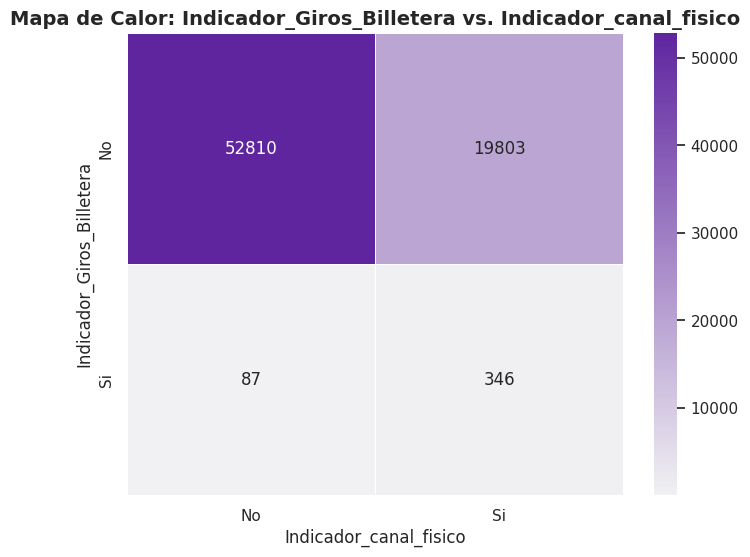

In [ ]:
# 📊 Crear tabla cruzada con frecuencias absolutas
tabla_cruzada = pd.crosstab(df["Indicador_Giros_Billetera"], df["Indicador_canal_fisico"])

# 📌 Crear tabla cruzada con porcentajes (sobre el total)
tabla_porcentaje = pd.crosstab(df["Indicador_Giros_Billetera"], df["Indicador_canal_fisico"], normalize="all") * 100


# 🎨 Definir el color personalizado (#5F259F / Pantone 267 C)
color_custom = "#5F259F"

# 🔥 Generar el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(tabla_cruzada, annot=True, fmt="d", cmap=sns.light_palette(color_custom, as_cmap=True), linewidths=0.5)

# 📌 Configurar títulos y etiquetas
plt.title("Mapa de Calor: Indicador_Giros_Billetera vs. Indicador_canal_fisico", fontsize=14, fontweight="bold")
plt.xlabel("Indicador_canal_fisico")
plt.ylabel("Indicador_Giros_Billetera")

# 📊 Mostrar gráfico
plt.show()

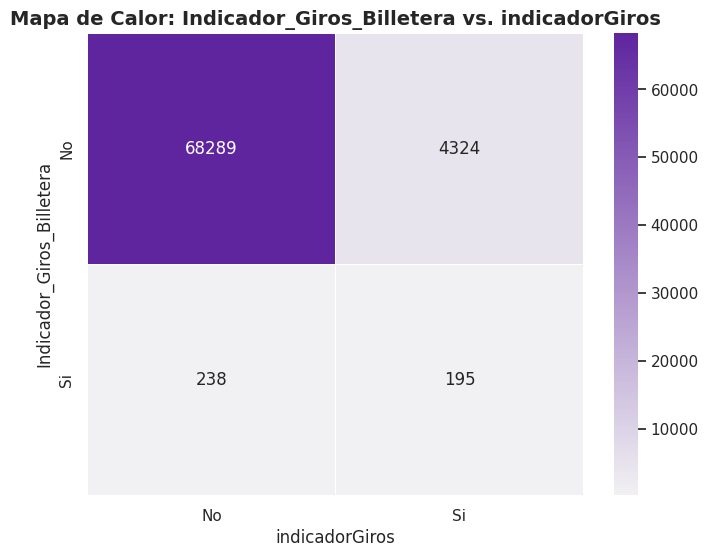

In [ ]:
# 📊 Crear tabla cruzada con frecuencias absolutas
tabla_cruzada = pd.crosstab(df["Indicador_Giros_Billetera"], df["indicadorGiros"])

# 📌 Crear tabla cruzada con porcentajes (sobre el total)
tabla_porcentaje = pd.crosstab(df["Indicador_Giros_Billetera"], df["indicadorGiros"], normalize="all") * 100


# 🎨 Definir el color personalizado (#5F259F / Pantone 267 C)
color_custom = "#5F259F"

# 🔥 Generar el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(tabla_cruzada, annot=True, fmt="d", cmap=sns.light_palette(color_custom, as_cmap=True), linewidths=0.5)

# 📌 Configurar títulos y etiquetas
plt.title("Mapa de Calor: Indicador_Giros_Billetera vs. indicadorGiros", fontsize=14, fontweight="bold")
plt.xlabel("indicadorGiros")
plt.ylabel("Indicador_Giros_Billetera")

# 📊 Mostrar gráfico
plt.show()

## Análisis de variables Cuantitativas

### Descripción:
Se realiza el analisis de las variables cuantitativas y se revisa las posibles correlaciones de las mismas,posteriormente ya se revisan posibles asociaciones con las vaiables cualitativas.


**Reasoning**:
Calculate descriptive statistics for numerical variables, analyze the frequency distribution of categorical variables, investigate correlations between numerical variables, and explore relationships between numerical and categorical variables.  This involves using `.describe()`, `.value_counts()`, `.corr()`, and potentially groupby operations along with visualization using a heatmap.



In [ ]:
# 📊 Definir las variables a analizar
variables_saldo = ["SALDO_Corte_Enero_2025", "Saldo_Promedio_3M", "Saldo_Promedio_6M", "Saldo_Promedio_12M"]

# 📉 Generar estadísticas descriptivas
estadisticas_saldo = df[variables_saldo].describe().T  # Transpuesta para mejor lectura

# 🔥 Agregar estadísticas adicionales
estadisticas_saldo["mediana"] = df[variables_saldo].median()
estadisticas_saldo["suma_total"] = df[variables_saldo].sum()  # Suma total
estadisticas_saldo["valores_unicos"] = df[variables_saldo].nunique()

# 📊 Mostrar estadísticas
print("\n📊 **Resumen Estadístico de Saldos:**\n")
print(estadisticas_saldo)



📊 **Resumen Estadístico de Saldos:**

                           count      mean        std  min  25%  50%      75%  \
SALDO_Corte_Enero_2025 73,046.00 43,917.01 370,966.76 0.00 0.00 0.00 1,020.75   
Saldo_Promedio_3M      73,046.00 43,711.04 339,581.94 0.00 0.00 0.00 1,389.69   
Saldo_Promedio_6M      73,046.00 43,239.82 321,981.01 0.00 0.00 0.00 2,017.85   
Saldo_Promedio_12M     73,046.00 43,644.49 304,012.80 0.00 0.00 0.00 2,873.85   

                                 max  mediana       suma_total  valores_unicos  
SALDO_Corte_Enero_2025 10,272,203.88     0.00 3,207,961,949.60           20600  
Saldo_Promedio_3M      10,136,956.90     0.00 3,192,916,698.68           21510  
Saldo_Promedio_6M      10,038,484.72     0.00 3,158,496,086.40           22314  
Saldo_Promedio_12M     10,038,484.72     0.00 3,188,055,465.30           23107  


In [ ]:

# 📊 Definir las variables de saldo a analizar
variables_saldo = ["SALDO_Corte_Enero_2025", "Saldo_Promedio_3M", "Saldo_Promedio_6M", "Saldo_Promedio_12M"]

# 📉 Calcular suma, promedio y conteo por género
estadisticas_genero = df.groupby("Genero")[variables_saldo].agg(["sum", "mean", "count"]).T  # Transponer para mejor lectura

# 📊 Mostrar estadísticas
print("\n📊 **Suma, Promedio y Conteo de Saldos por Género:**\n")
print(estadisticas_genero)



📊 **Suma, Promedio y Conteo de Saldos por Género:**

Genero                               Femenino        Masculino
SALDO_Corte_Enero_2025 sum   2,001,861,413.35 1,206,100,536.25
                       mean         48,600.67        37,861.02
                       count        41,190.00        31,856.00
Saldo_Promedio_3M      sum   1,969,509,020.40 1,223,407,678.28
                       mean         47,815.22        38,404.31
                       count        41,190.00        31,856.00
Saldo_Promedio_6M      sum   1,954,561,490.26 1,203,934,596.15
                       mean         47,452.33        37,793.02
                       count        41,190.00        31,856.00
Saldo_Promedio_12M     sum   1,951,128,281.10 1,236,927,184.20
                       mean         47,368.98        38,828.70
                       count        41,190.00        31,856.00


In [ ]:
# 📊 Definir las variables de saldo a analizar
variables_saldo = ["SALDO_Corte_Enero_2025", "Saldo_Promedio_3M", "Saldo_Promedio_6M", "Saldo_Promedio_12M"]

# 📉 Calcular suma, promedio y conteo por Tipodesistema
estadisticas_Rango_Edad = df.groupby("Rango_Edad")[variables_saldo].agg(["sum", "mean", "count"]).T  # Transponer para mejor lectura

# 📊 Mostrar estadísticas
print("\n📊 **Suma, Promedio y Conteo de Saldos por Rangos de Edad:**\n")
print(estadisticas_Rango_Edad)


📊 **Suma, Promedio y Conteo de Saldos por Rangos de Edad:**

Rango_Edad                            18-25          25-35          35-45  \
SALDO_Corte_Enero_2025 sum   319,853,957.54 877,479,951.10 816,813,931.81   
                       mean       22,900.69      37,922.12      49,875.68   
                       count      13,967.00      23,139.00      16,377.00   
Saldo_Promedio_3M      sum   292,894,752.10 874,771,227.78 803,126,089.08   
                       mean       20,970.48      37,805.06      49,039.88   
                       count      13,967.00      23,139.00      16,377.00   
Saldo_Promedio_6M      sum   312,295,912.13 864,316,057.70 793,029,441.62   
                       mean       22,359.56      37,353.22      48,423.36   
                       count      13,967.00      23,139.00      16,377.00   
Saldo_Promedio_12M     sum   325,964,174.88 868,939,464.74 805,270,812.91   
                       mean       23,338.17      37,553.03      49,170.84   
              

<ipython-input-32-3cecf33e12be>:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  estadisticas_Rango_Edad = df.groupby("Rango_Edad")[variables_saldo].agg(["sum", "mean", "count"]).T  # Transponer para mejor lectura


In [ ]:
# 📊 Definir las variables de saldo a analizar
variables_saldo = ["SALDO_Corte_Enero_2025", "Saldo_Promedio_3M", "Saldo_Promedio_6M", "Saldo_Promedio_12M"]

# 📉 Calcular suma, promedio y conteo por Tipodesistema
estadisticas_estado_corte = df.groupby("ESTADOPRODUCTO_Corte")[variables_saldo].agg(["sum", "mean", "count"]).T  # Transponer para mejor lectura

# 📊 Mostrar estadísticas
print("\n📊 **Suma, Promedio y Conteo de Saldos por Estado del producto al corte Enero 2025:**\n")
print(estadisticas_estado_corte)


📊 **Suma, Promedio y Conteo de Saldos por Estado del producto al corte Enero 2025:**

ESTADOPRODUCTO_Corte          Bloqueo Completo  Bloqueo Compliance  \
SALDO_Corte_Enero_2025 sum            7,275.92       14,332,099.60   
                       mean           1,039.42           50,288.07   
                       count              7.00              285.00   
Saldo_Promedio_3M      sum            7,269.10       12,046,485.84   
                       mean           1,038.44           42,268.37   
                       count              7.00              285.00   
Saldo_Promedio_6M      sum            7,262.62       10,273,542.95   
                       mean           1,037.52           36,047.52   
                       count              7.00              285.00   
Saldo_Promedio_12M     sum            7,262.62        9,840,981.20   
                       mean           1,037.52           34,529.76   
                       count              7.00              285.00   

ES

In [ ]:
# 📊 Definir las variables de saldo a analizar
variables_saldo = ["SALDO_Corte_Enero_2025", "Saldo_Promedio_3M", "Saldo_Promedio_6M", "Saldo_Promedio_12M"]

# 📉 Calcular suma, promedio y conteo por Tipodesistema
estadisticas_tipodesistema = df.groupby("Tipo de sistema")[variables_saldo].agg(["sum", "mean", "count"]).T  # Transponer para mejor lectura

# 📊 Mostrar estadísticas
print("\n📊 **Suma, Promedio y Conteo de Saldos por Tipodesistema:**\n")
print(estadisticas_tipodesistema)



📊 **Suma, Promedio y Conteo de Saldos por Tipodesistema:**

Tipo de sistema                       Android     HarmonyOS            iOS
SALDO_Corte_Enero_2025 sum   2,697,871,818.04 41,727,326.10 468,362,805.46
                       mean         45,446.26     36,635.05      37,340.57
                       count        59,364.00      1,139.00      12,543.00
Saldo_Promedio_3M      sum   2,724,596,836.17 44,338,216.43 423,981,646.08
                       mean         45,896.45     38,927.32      33,802.25
                       count        59,364.00      1,139.00      12,543.00
Saldo_Promedio_6M      sum   2,687,999,436.89 48,572,596.10 421,924,053.42
                       mean         45,279.96     42,644.95      33,638.21
                       count        59,364.00      1,139.00      12,543.00
Saldo_Promedio_12M     sum   2,698,172,600.63 49,244,585.08 440,638,279.59
                       mean         45,451.33     43,234.93      35,130.21
                       count        59,

In [ ]:
#Adentrarnos un poco en el conocimiento de los usuarios que hacen Giros por la billetera#

# 📊 Filtrar solo los usuarios donde Indicador_Giros_Billetera es "Si"
df_giros = df[df["Indicador_Giros_Billetera"] == "Si"]

# 📉 Calcular estadísticas sin valores cero en los saldos
saldo_corte_cantidad = df_giros["SALDO_Corte_Enero_2025"][df_giros["SALDO_Corte_Enero_2025"] != 0].count()
saldo_corte_promedio = df_giros["SALDO_Corte_Enero_2025"][df_giros["SALDO_Corte_Enero_2025"] != 0].mean()
saldo_prom_3m_cantidad = df_giros["Saldo_Promedio_3M"][df_giros["Saldo_Promedio_3M"] != 0].count()
saldo_prom_3m_promedio = df_giros["Saldo_Promedio_3M"][df_giros["Saldo_Promedio_3M"] != 0].mean()

# 📊 Calcular cuenta, suma y promedio de las demás variables
estadisticas_giros = df_giros.agg(
    Cantidad_Usuarios=("Indicador_Giros_Billetera", "count"),
    Suma_Promedio_Giro_Pesos=("Promedio_Giro_Pesos", "sum"),
    Promedio_Giro_Pesos=("Promedio_Giro_Pesos", "mean"),
    Suma_TotalGiros_Pesos=("TotalGiros_Pesos", "sum"),
    Promedio_TotalGiros_Pesos=("TotalGiros_Pesos", "mean"),
    Suma_Cantidad_Giros=("Cantidad_giros", "sum"),
    Promedio_Cantidad_Giros=("Cantidad_giros", "mean")
)

# 📌 Agregar los valores de los saldos excluyendo ceros
estadisticas_giros.loc["Saldo_Corte_Enero_2025_NoCero_Cantidad"] = saldo_corte_cantidad
estadisticas_giros.loc["Saldo_Corte_Enero_2025_NoCero_Promedio"] = saldo_corte_promedio
estadisticas_giros.loc["Saldo_Promedio_3M_NoCero_Cantidad"] = saldo_prom_3m_cantidad
estadisticas_giros.loc["Saldo_Promedio_3M_NoCero_Promedio"] = saldo_prom_3m_promedio

# 🔥 Mostrar resultados
print("\n📊 **Estadísticas de Giros para Usuarios con 'Si' en Indicador_Giros_Billetera (Excluyendo Ceros en Saldos):**\n")
print(estadisticas_giros.round(2))



📊 **Estadísticas de Giros para Usuarios con 'Si' en Indicador_Giros_Billetera (Excluyendo Ceros en Saldos):**

                                        Indicador_Giros_Billetera  \
Cantidad_Usuarios                                          433.00   
Suma_Promedio_Giro_Pesos                                      NaN   
Promedio_Giro_Pesos                                           NaN   
Suma_TotalGiros_Pesos                                         NaN   
Promedio_TotalGiros_Pesos                                     NaN   
Suma_Cantidad_Giros                                           NaN   
Promedio_Cantidad_Giros                                       NaN   
Saldo_Corte_Enero_2025_NoCero_Cantidad                     411.00   
Saldo_Corte_Enero_2025_NoCero_Promedio                 409,416.22   
Saldo_Promedio_3M_NoCero_Cantidad                          411.00   
Saldo_Promedio_3M_NoCero_Promedio                      369,006.31   

                                        Promedio_Giro_Pesos

In [ ]:
# 📊 Calcular el promedio de Edad_Actual y Tiempo de vida según Indicador_Giros_Billetera
promedio_edad_por_grupo = df.groupby("Indicador_Giros_Billetera")["Edad_Actual"].mean().round(2)
promedio_Tiempo_vida_Giros = df.groupby("Indicador_Giros_Billetera")["Tiempo_vida_Billeteraw"].mean().round(2)
promedio_Tiempo_vida_Banco = df.groupby("Indicador_Giros_Billetera")["TiempoVidaBancoW"].mean().round(2)
# 🔥 Mostrar resultados
print("\n📊 **Promedio de Edad según Indicador_Giros_Billetera:**\n")
print(promedio_edad_por_grupo)
print("\n📊 **Promedio de Tiempo Vida Billetera según Indicador_Giros_Billetera:**\n")
print(promedio_Tiempo_vida_Giros)
print("\n📊 **Promedio de Tiempo Vida Banco según Indicador_Giros_Billetera:**\n")
print(promedio_Tiempo_vida_Banco)



📊 **Promedio de Edad según Indicador_Giros_Billetera:**

Indicador_Giros_Billetera
No   37.48
Si   38.18
Name: Edad_Actual, dtype: float64

📊 **Promedio de Tiempo Vida Billetera según Indicador_Giros_Billetera:**

Indicador_Giros_Billetera
No   6.75
Si   6.91
Name: Tiempo_vida_Billeteraw, dtype: float64

📊 **Promedio de Tiempo Vida Banco según Indicador_Giros_Billetera:**

Indicador_Giros_Billetera
No   25.45
Si   23.51
Name: TiempoVidaBancoW, dtype: float64



📊 **Top 10 Ciudades con Mayor Monto en Giros y Cantidad de Usuarios:**

            Total_Giros_Pesos  Cantidad_Usuarios  Porcentaje
Cod_Ciudad                                                  
Cali                300377827                 95       21.19
Cúcuta              296168421                 42       20.89
Bogotá              246903418                 47       17.42
Palmira             112393031                 16        7.93
Soacha              111393463                  5        7.86
Medellín             85363162                 20        6.02
Bello                78614823                  4        5.55
Ibagué               74343068                 14        5.24
Ábrego               66576850                  2        4.70
Cartago              45502409                  5        3.21


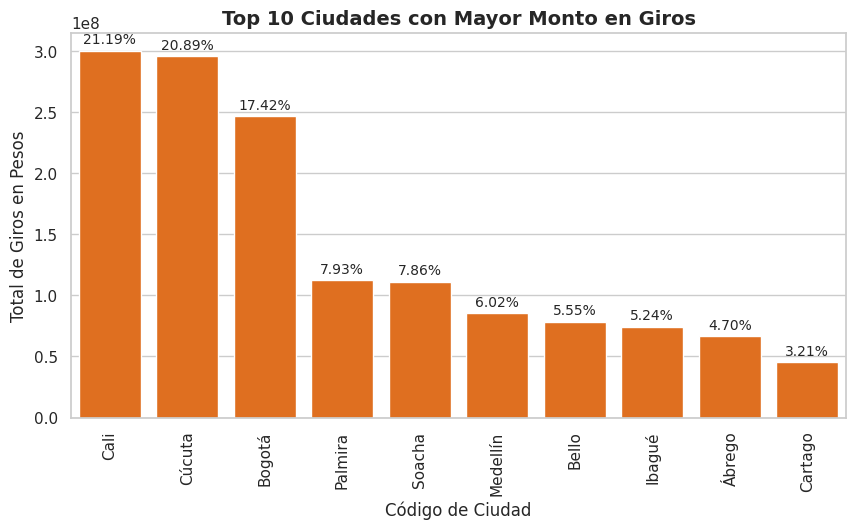

In [ ]:
# 📊 Filtrar solo los usuarios que hacen giros por la billetera
df_giros = df[df["Indicador_Giros_Billetera"] == "Si"]

# 📉 Sumar el monto total de giros y contar usuarios por ciudad
top_ciudades_giros = df_giros.groupby("Cod_Ciudad").agg(
    Total_Giros_Pesos=("TotalGiros_Pesos", "sum"),
    Cantidad_Usuarios=("Cod_Ciudad", "count")  # 🔹 Agregamos el conteo de usuarios
).sort_values(by="Total_Giros_Pesos", ascending=False).head(10)

# 📊 Calcular el porcentaje sobre el total
top_ciudades_giros["Porcentaje"] = (top_ciudades_giros["Total_Giros_Pesos"] / top_ciudades_giros["Total_Giros_Pesos"].sum() * 100).round(2)

# 🔥 Mostrar tabla con el Top 10
print("\n📊 **Top 10 Ciudades con Mayor Monto en Giros y Cantidad de Usuarios:**\n")
print(top_ciudades_giros)

# 📈 Gráfico de Barras con etiquetas de porcentaje
plt.figure(figsize=(10, 5))
ax = sns.barplot(x=top_ciudades_giros.index, y=top_ciudades_giros["Total_Giros_Pesos"], color="#FF6900")

# 📌 Agregar etiquetas de porcentaje (redondeadas a 2 decimales)
ax.bar_label(ax.containers[0], labels=[f"{p:.2f}%" for p in top_ciudades_giros["Porcentaje"]],
             label_type="edge", fontsize=10, padding=3)

# 📌 Configurar etiquetas y título
plt.title("Top 10 Ciudades con Mayor Monto en Giros", fontsize=14, fontweight="bold")
plt.xlabel("Código de Ciudad")
plt.ylabel("Total de Giros en Pesos")
plt.xticks(rotation=90)

# 📊 Mostrar gráfico
plt.show()


In [ ]:
# 📊 Filtrar solo los usuarios donde Indicador_TM es "Si"
df_tm = df[df["Indicador_TM"] == "Si"]

# 📌 Total de usuarios con Indicador_TM = "Si"
total_usuarios_tm = len(df_tm)

# 📌 Lista de variables transaccionales en los últimos 3 meses
variables_TM_3M = [
    # 🔹 Variables de Monto
    "promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW",
    "promedio_MONTO_ultimos_3m_RecargaPSEBilletera",
    "promedio_MONTO_ultimos_3m_TransInterbanBilletera",
    "promedio_MONTO_ultimos_3m_TransfentreBilleterasW",
    "promedio_MONTO_ultimos_3m_Tusaludyseguros",
    "promedio_MONTO_ultimos_3m_TusTelecomunicaciones",
    "promedio_MONTO_ultimos_3m_TusfacturasbilleteraW",
    "promedio_MONTO_ultimos_3m_Tusserviciospúblicosbille",
    "promedio_MONTO_ultimos_3m_TusviajesbilleteraW",
    # 🔹 Variables de Transacciones
    "prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW",
    "prom_transacciones_ultimos_3m_RecargaPSEBilletera",
    "prom_transacciones_ultimos_3m_TransInterbanBilletera",
    "prom_transacciones_ultimos_3m_TransfentreBilleterasW",
    "prom_transacciones_ultimos_3m_Tusaludyseguros",
    "prom_transacciones_ultimos_3m_TusTelecomunicaciones",
    "prom_transacciones_ultimos_3m_TusfacturasbilleteraW",
    "prom_transacciones_ultimos_3m_Tusserviciospúblicosbille",
    "prom_transacciones_ultimos_3m_TusviajesbilleteraW"
]

# 📉 Calcular el conteo, porcentaje y promedio excluyendo los ceros
estadisticas_TM_3M = pd.DataFrame({
    "Conteo_Sin_Cero": [df_tm[var][df_tm[var] != 0].count() for var in variables_TM_3M],
    "Porcentaje": [(df_tm[var][df_tm[var] != 0].count() / total_usuarios_tm * 100) for var in variables_TM_3M],
    "Promedio_Sin_Cero": [df_tm[var][df_tm[var] != 0].mean() for var in variables_TM_3M]
}, index=variables_TM_3M).round(2)

# 🔥 Mostrar resultados
print("\n📊 **Conteo, Porcentaje y Promedio (Excluyendo Ceros) para Variables de Transacciones Monetarias (Últimos 3 Meses):**\n")
print(estadisticas_TM_3M)




📊 **Conteo, Porcentaje y Promedio (Excluyendo Ceros) para Variables de Transacciones Monetarias (Últimos 3 Meses):**

                                                    Conteo_Sin_Cero  \
promedio_MONTO_ultimos_3m_Compracontdigitalbill...              457   
promedio_MONTO_ultimos_3m_RecargaPSEBilletera                   983   
promedio_MONTO_ultimos_3m_TransInterbanBilletera               3722   
promedio_MONTO_ultimos_3m_TransfentreBilleterasW               1080   
promedio_MONTO_ultimos_3m_Tusaludyseguros                         1   
promedio_MONTO_ultimos_3m_TusTelecomunicaciones                  87   
promedio_MONTO_ultimos_3m_TusfacturasbilleteraW                   7   
promedio_MONTO_ultimos_3m_Tusserviciospúblicosb...               42   
promedio_MONTO_ultimos_3m_TusviajesbilleteraW                     0   
prom_transacciones_ultimos_3m_Compracontdigital...              457   
prom_transacciones_ultimos_3m_RecargaPSEBilletera               983   
prom_transacciones_ultimos_3m

<ipython-input-39-7102b8b264cb>:18: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tm["Total_Transacciones"] = df_tm[variables_transacciones_prom_3m].ne(0).sum(axis=1)


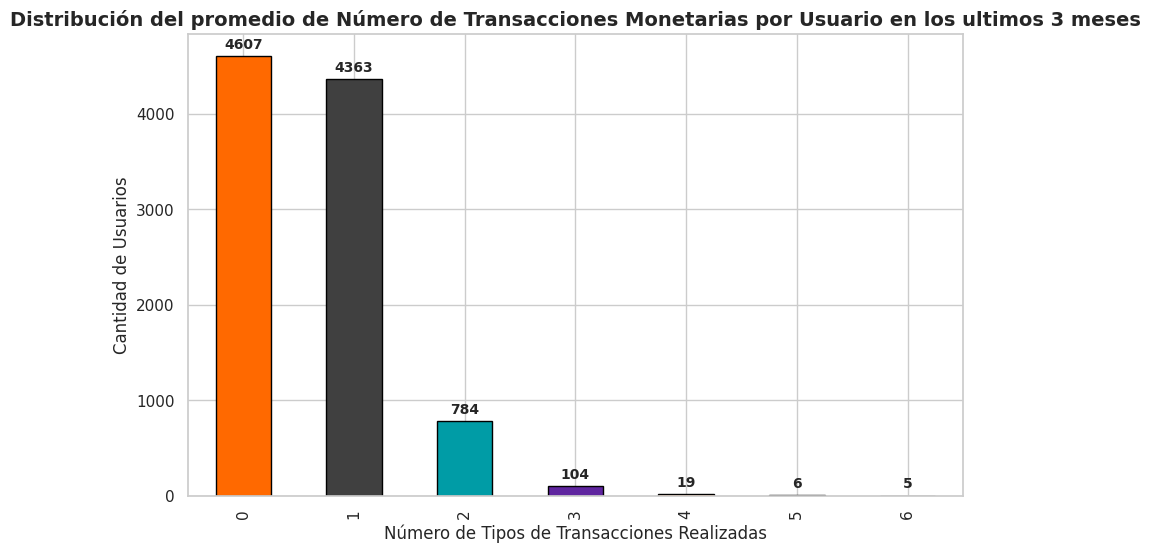

In [ ]:
# 📊 Filtrar solo los usuarios donde Indicador_TM es "Si"
df_tm = df[df["Indicador_TM"] == "Si"]

# 📌 Lista de variables transaccionales (excluyendo montos)
variables_transacciones_prom_3m = [
    "prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW",
    "prom_transacciones_ultimos_3m_RecargaPSEBilletera",
    "prom_transacciones_ultimos_3m_TransInterbanBilletera",
    "prom_transacciones_ultimos_3m_TransfentreBilleterasW",
    "prom_transacciones_ultimos_3m_Tusaludyseguros",
    "prom_transacciones_ultimos_3m_TusTelecomunicaciones",
    "prom_transacciones_ultimos_3m_TusfacturasbilleteraW",
    "prom_transacciones_ultimos_3m_Tusserviciospúblicosbille",
    "prom_transacciones_ultimos_3m_TusviajesbilleteraW"
]

# 📌 Contar cuántas transacciones diferentes ha hecho cada usuario
df_tm["Total_Transacciones"] = df_tm[variables_transacciones_prom_3m].ne(0).sum(axis=1)

# 📊 Contar cuántos usuarios hay en cada nivel de transacciones
distribucion_transacciones = df_tm["Total_Transacciones"].value_counts().sort_index()

# 🎨 Paleta de colores para las barras (repetida según el número de categorías)
colores = ["#FF6900", "#404040", "#009CA6", "#5F259F"] * (len(distribucion_transacciones) // 4 + 1)

# 📈 Crear gráfico de barras
plt.figure(figsize=(10, 6))
ax = distribucion_transacciones.plot(kind="bar", color=colores[:len(distribucion_transacciones)], edgecolor="black")

# 📌 Etiquetas y título
plt.xlabel("Número de Tipos de Transacciones Realizadas")
plt.ylabel("Cantidad de Usuarios")
plt.title("Distribución del promedio de Número de Transacciones Monetarias por Usuario en los ultimos 3 meses", fontsize=14, fontweight="bold")

# 📊 Agregar etiquetas sobre las barras
for i, v in enumerate(distribucion_transacciones):
    ax.text(i, v + 50, str(v), ha="center", va="bottom", fontsize=10, fontweight="bold")

# 📊 Mostrar gráfico
plt.show()


<ipython-input-40-c8865fd6a21c>:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tm["Total_Transacciones"] = df_tm[variables_transacciones_prom_ultimo_año].ne(0).sum(axis=1)


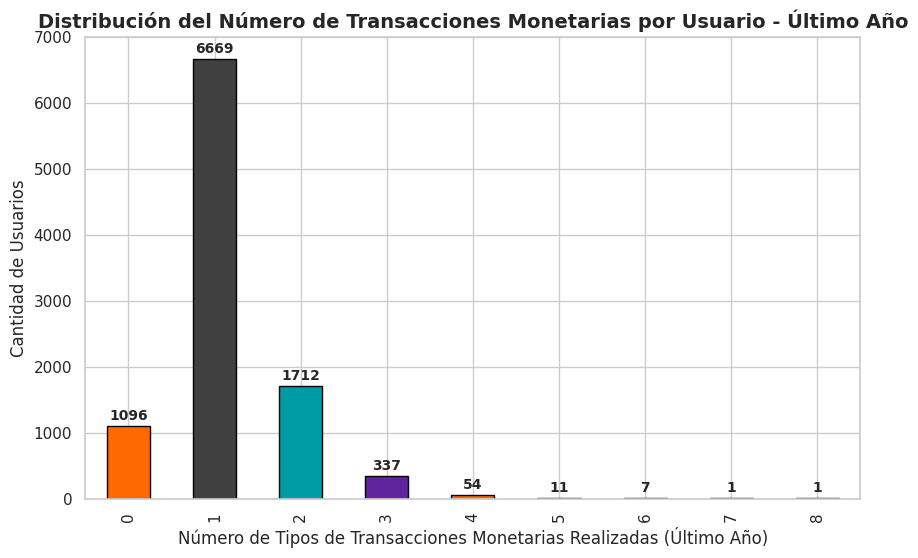

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 📊 Filtrar solo los usuarios donde Indicador_TM es "Si"
df_tm = df[df["Indicador_TM"] == "Si"]

# 📌 Lista de variables de transacciones del último año
variables_transacciones_prom_ultimo_año = [
    "prom_transacciones_ultimo_año_CompracontdigitalbilleteraW",
    "prom_transacciones_ultimo_año_RecargaPSEBilletera",
    "prom_transacciones_ultimo_año_TransInterbanBilletera",
    "prom_transacciones_ultimo_año_TransfentreBilleterasW",
    "prom_transacciones_ultimo_año_Tusaludyseguros",
    "prom_transacciones_ultimo_año_TusTelecomunicaciones",
    "prom_transacciones_ultimo_año_TusfacturasbilleteraW",
    "prom_transacciones_ultimo_año_Tusserviciospúblicosbille",
    "prom_transacciones_ultimo_año_TusviajesbilleteraW"
]

# 📌 Contar cuántas transacciones diferentes ha hecho cada usuario en el último año
df_tm["Total_Transacciones"] = df_tm[variables_transacciones_prom_ultimo_año].ne(0).sum(axis=1)

# 📊 Contar cuántos usuarios hay en cada nivel de transacciones
distribucion_transacciones = df_tm["Total_Transacciones"].value_counts().sort_index()

# 🎨 Paleta de colores institucional
colores = ["#FF6900", "#404040", "#009CA6", "#5F259F"] * (len(distribucion_transacciones) // 4 + 1)

# 📈 Crear gráfico de barras
plt.figure(figsize=(10, 6))
ax = distribucion_transacciones.plot(kind="bar", color=colores[:len(distribucion_transacciones)], edgecolor="black")

# 📌 Etiquetas y título
plt.xlabel("Número de Tipos de Transacciones Monetarias Realizadas (Último Año)")
plt.ylabel("Cantidad de Usuarios")
plt.title("Distribución del Número de Transacciones Monetarias por Usuario - Último Año", fontsize=14, fontweight="bold")

# 📊 Agregar etiquetas sobre las barras
for i, v in enumerate(distribucion_transacciones):
    ax.text(i, v + 50, str(v), ha="center", va="bottom", fontsize=10, fontweight="bold")

# 📊 Mostrar gráfico
plt.show()


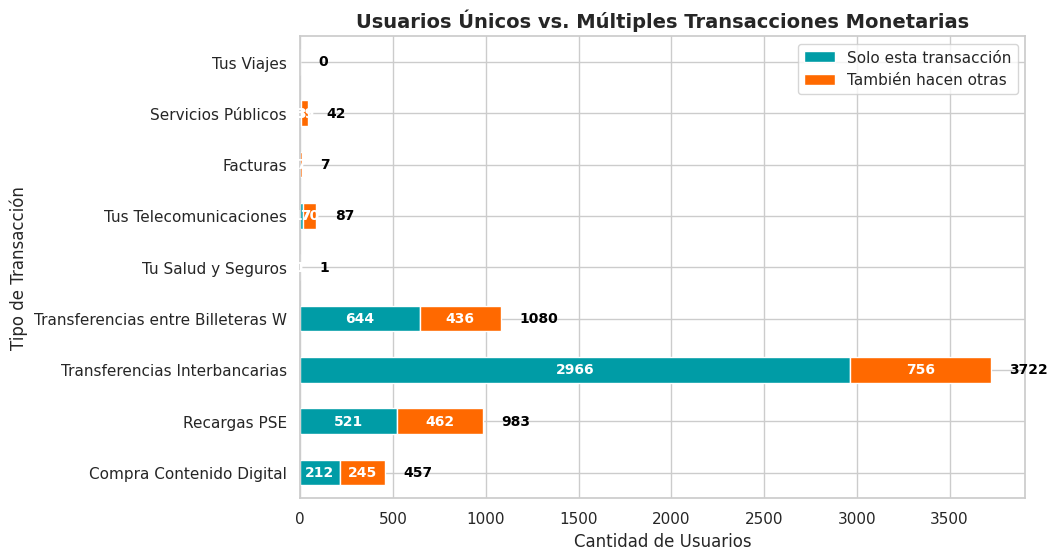

In [ ]:
# 📊 Filtrar solo los usuarios donde Indicador_TM es "Si"
df_tm = df[df["Indicador_TM"] == "Si"]

# 📌 Definir variables de transacciones monetarias (excluyendo montos)
variables_grafico = [
    "prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW",
    "prom_transacciones_ultimos_3m_RecargaPSEBilletera",
    "prom_transacciones_ultimos_3m_TransInterbanBilletera",
    "prom_transacciones_ultimos_3m_TransfentreBilleterasW",
    "prom_transacciones_ultimos_3m_Tusaludyseguros",
    "prom_transacciones_ultimos_3m_TusTelecomunicaciones",
    "prom_transacciones_ultimos_3m_TusfacturasbilleteraW",
    "prom_transacciones_ultimos_3m_Tusserviciospúblicosbille",
    "prom_transacciones_ultimos_3m_TusviajesbilleteraW"
]

# 📌 Etiquetas simplificadas para el gráfico
etiquetas_grafico = {
    "prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW": "Compra Contenido Digital",
    "prom_transacciones_ultimos_3m_RecargaPSEBilletera": "Recargas PSE",
    "prom_transacciones_ultimos_3m_TransInterbanBilletera": "Transferencias Interbancarias",
    "prom_transacciones_ultimos_3m_TransfentreBilleterasW": "Transferencias entre Billeteras W",
    "prom_transacciones_ultimos_3m_Tusaludyseguros": "Tu Salud y Seguros",
    "prom_transacciones_ultimos_3m_TusTelecomunicaciones": "Tus Telecomunicaciones",
    "prom_transacciones_ultimos_3m_TusfacturasbilleteraW": "Facturas",
    "prom_transacciones_ultimos_3m_Tusserviciospúblicosbille": "Servicios Públicos",
    "prom_transacciones_ultimos_3m_TusviajesbilleteraW": "Tus Viajes"
}

# 📊 Contar usuarios que han hecho cada transacción
conteo_transacciones = {var: df_tm[df_tm[var] != 0].shape[0] for var in variables_grafico}

# 📊 Crear un DataFrame con los conteos
df_transacciones = pd.DataFrame.from_dict(conteo_transacciones, orient="index", columns=["Usuarios"])

# 📌 cálculo de usuarios múltiples, filtrando por cada transacción específica
usuarios_multiples = {}
usuarios_solo_una = {}

for var in variables_grafico:
    usuarios_total = df_tm[df_tm[var] != 0].shape[0]  # Total de usuarios que hicieron esta transacción
    usuarios_multi = df_tm[(df_tm[var] != 0) & (df_tm[variables_grafico].ne(0).sum(axis=1) > 1)].shape[0]  # De estos, cuántos hicieron otras también
    usuarios_multiples[var] = usuarios_multi
    usuarios_solo_una[var] = usuarios_total - usuarios_multi  # Complemento para que la suma dé el total

# 📊 Agregar datos al DataFrame
df_transacciones["Usuarios_Multiples"] = df_transacciones.index.map(usuarios_multiples)
df_transacciones["Usuarios_Solo_Una"] = df_transacciones.index.map(usuarios_solo_una)

# 📊 Renombrar índice con etiquetas más claras
df_transacciones.index = [etiquetas_grafico[var] for var in df_transacciones.index]

# 🎨 Colores personalizados
colores_barras = ["#009CA6", "#FF6900"]

# 📈 Crear gráfico de barras apiladas
fig, ax = plt.subplots(figsize=(10, 6))
df_transacciones[["Usuarios_Solo_Una", "Usuarios_Multiples"]].plot(kind="barh", stacked=True, ax=ax, color=colores_barras)

# 📌 Etiquetas y título
plt.xlabel("Cantidad de Usuarios")
plt.ylabel("Tipo de Transacción")
plt.title("Usuarios Únicos vs. Múltiples Transacciones Monetarias", fontsize=14, fontweight="bold")
plt.legend(["Solo esta transacción", "También hacen otras"])

# 📊 Agregar etiquetas sobre cada segmento de la barra
for i, (solo, multi) in enumerate(zip(df_transacciones["Usuarios_Solo_Una"], df_transacciones["Usuarios_Multiples"])):
    total = solo + multi  # Total de la barra

    # 📌 Mostrar etiquetas dentro de cada barra
    if solo > 0:
        ax.text(solo / 2, i, f"{solo:.0f}", ha="center", va="center", color="white", fontsize=10, fontweight="bold")
    if multi > 0:
        ax.text(solo + (multi / 2), i, f"{multi:.0f}", ha="center", va="center", color="white", fontsize=10, fontweight="bold")

    # 📌 Mostrar el total en el extremo derecho de la barra
    ax.text(total + 100, i, f"{total:.0f}", ha="left", va="center", color="black", fontsize=10, fontweight="bold")

# 📊 Ajustar el margen derecho para que las etiquetas no se corten
plt.subplots_adjust(right=0.85)

# 📊 Mostrar gráfico
plt.show()


<ipython-input-42-9e0c7c46addf>:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tm["Recarga_PSE"] = df_tm[var_recargas].apply(lambda x: 1 if x != 0 else 0)
<ipython-input-42-9e0c7c46addf>:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_tm["Compra_Contenido_Digital"] = df_tm[var_contenido].apply(lambda x: 1 if x != 0 else 0)


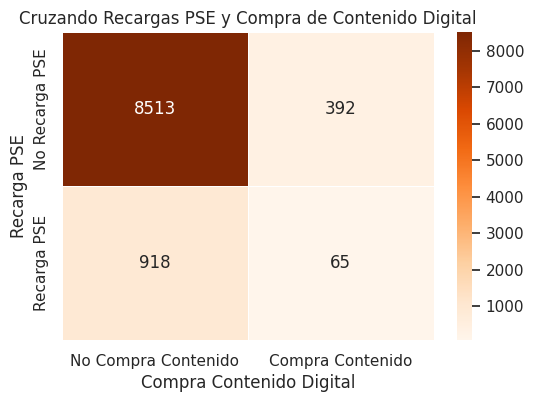


📊 **Cruzando Recargas PSE y Compra de Contenido Digital:**

                No Compra Contenido  Compra Contenido  Total
No Recarga PSE                 8513               392   8905
Recarga PSE                     918                65    983
Total                          9431               457   9888


In [ ]:
#Cruce entre Recargas PSE y compra de contenido digital solo para verificar si se encuentra algo interesante a cara de estrategias de impulsar este modulo#

# 📊 Filtrar solo los usuarios con transacciones monetarias
df_tm = df[df["Indicador_TM"] == "Si"]

# 📌 Definir las variables de transacción a cruzar
var_recargas = "prom_transacciones_ultimos_3m_RecargaPSEBilletera"
var_contenido = "prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW"

# 📌 Crear nueva columna indicando si el usuario ha hecho cada transacción (1 = Sí, 0 = No)
df_tm["Recarga_PSE"] = df_tm[var_recargas].apply(lambda x: 1 if x != 0 else 0)
df_tm["Compra_Contenido_Digital"] = df_tm[var_contenido].apply(lambda x: 1 if x != 0 else 0)

# 📊 Crear tabla cruzada
tabla_cruce = pd.crosstab(df_tm["Recarga_PSE"], df_tm["Compra_Contenido_Digital"], margins=True)
tabla_cruce.index = ["No Recarga PSE", "Recarga PSE", "Total"]
tabla_cruce.columns = ["No Compra Contenido", "Compra Contenido", "Total"]

# 🔥 Visualizar con un mapa de calor
plt.figure(figsize=(6, 4))
sns.heatmap(tabla_cruce.iloc[:-1, :-1], annot=True, fmt="d", cmap="Oranges", linewidths=0.5)
plt.title("Cruzando Recargas PSE y Compra de Contenido Digital")
plt.xlabel("Compra Contenido Digital")
plt.ylabel("Recarga PSE")
plt.show()

# 📊 Mostrar tabla de cruce en consola
print("\n📊 **Cruzando Recargas PSE y Compra de Contenido Digital:**\n")
print(tabla_cruce)


In [ ]:
# Profundizar un poco si de esos que han realizado transferencias interbancarias han tenido credito?#

# 📊 Filtrar solo los usuarios que han hecho transferencias interbancarias (diferente de 0)
df_trans_interban = df[df["promedio_MONTO_ultimos_3m_TransInterbanBilletera"] != 0]

# 📉 Contar cuántos de estos usuarios tienen indicadorCreditos = "Si"
usuarios_con_credito = df_trans_interban[df_trans_interban["indicadorCreditos"] == "Si"].shape[0]

# 📊 Total de usuarios que hicieron transferencias interbancarias
total_usuarios_trans_interban = df_trans_interban.shape[0]

# 📌 Calcular el porcentaje de usuarios con créditos
porcentaje_con_credito = (usuarios_con_credito / total_usuarios_trans_interban * 100) if total_usuarios_trans_interban > 0 else 0

# 🔥 Mostrar resultados
print("\n📊 **Análisis de Transferencias Interbancarias y Créditos:**\n")
print(f"Total de usuarios que hicieron transferencias interbancarias: {total_usuarios_trans_interban}")
print(f"Usuarios con créditos: {usuarios_con_credito}")
print(f"Porcentaje de estos usuarios con créditos: {porcentaje_con_credito:.2f}%")



📊 **Análisis de Transferencias Interbancarias y Créditos:**

Total de usuarios que hicieron transferencias interbancarias: 3722
Usuarios con créditos: 733
Porcentaje de estos usuarios con créditos: 19.69%


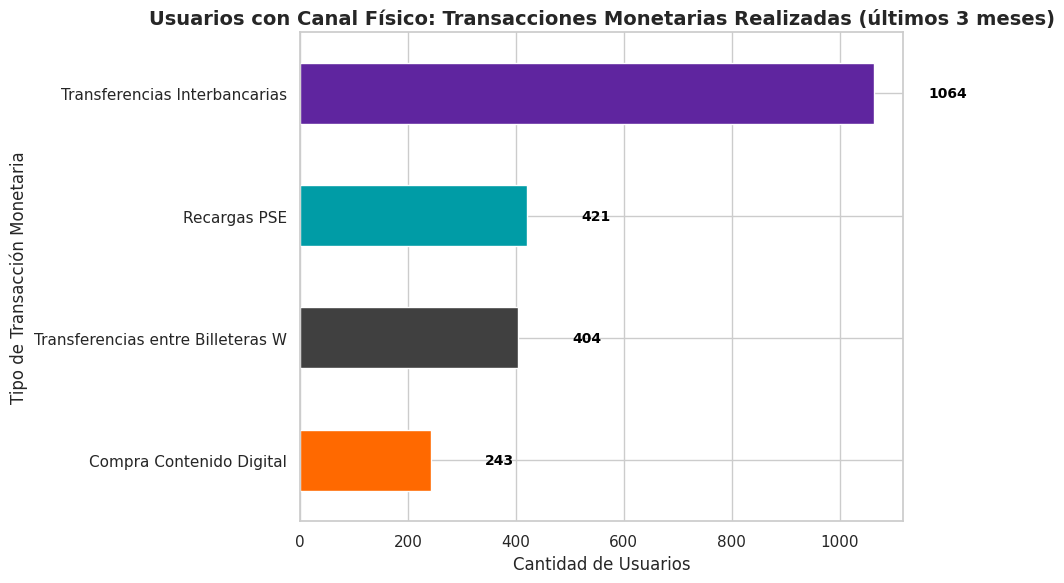

In [ ]:
# 📌 Filtrar solo los usuarios que han usado canal físico
df_fisico = df[df["Indicador_canal_fisico"] == "Si"]

# 📌 Variables transaccionales a analizar
variables_analisis = {
    "prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW": "Compra Contenido Digital",
    "prom_transacciones_ultimos_3m_RecargaPSEBilletera": "Recargas PSE",
    "prom_transacciones_ultimos_3m_TransInterbanBilletera": "Transferencias Interbancarias",
    "prom_transacciones_ultimos_3m_TransfentreBilleterasW": "Transferencias entre Billeteras W"
}

# 📊 Calcular cuántos usuarios han hecho cada transacción (diferente de cero)
conteos = {
    nombre: df_fisico[var][df_fisico[var] != 0].count()
    for var, nombre in variables_analisis.items()
}

# 📌 Crear Series para graficar
conteos_series = pd.Series(conteos).sort_values()

# 🎨 Paleta de colores institucional
colores = ["#FF6900", "#404040", "#009CA6", "#5F259F"]

# 📈 Gráfico de barras horizontal
plt.figure(figsize=(10, 6))
ax = conteos_series.plot(kind="barh", color=colores)

# 📌 Etiquetas
plt.title("Usuarios con Canal Físico: Transacciones Monetarias Realizadas (últimos 3 meses)", fontsize=14, fontweight="bold")
plt.xlabel("Cantidad de Usuarios")
plt.ylabel("Tipo de Transacción Monetaria")

# 📊 Mostrar valores sobre las barras
for i, v in enumerate(conteos_series):
    ax.text(v + 100, i, str(v), color='black', va='center', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


<ipython-input-45-35d9908404d8>:35: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


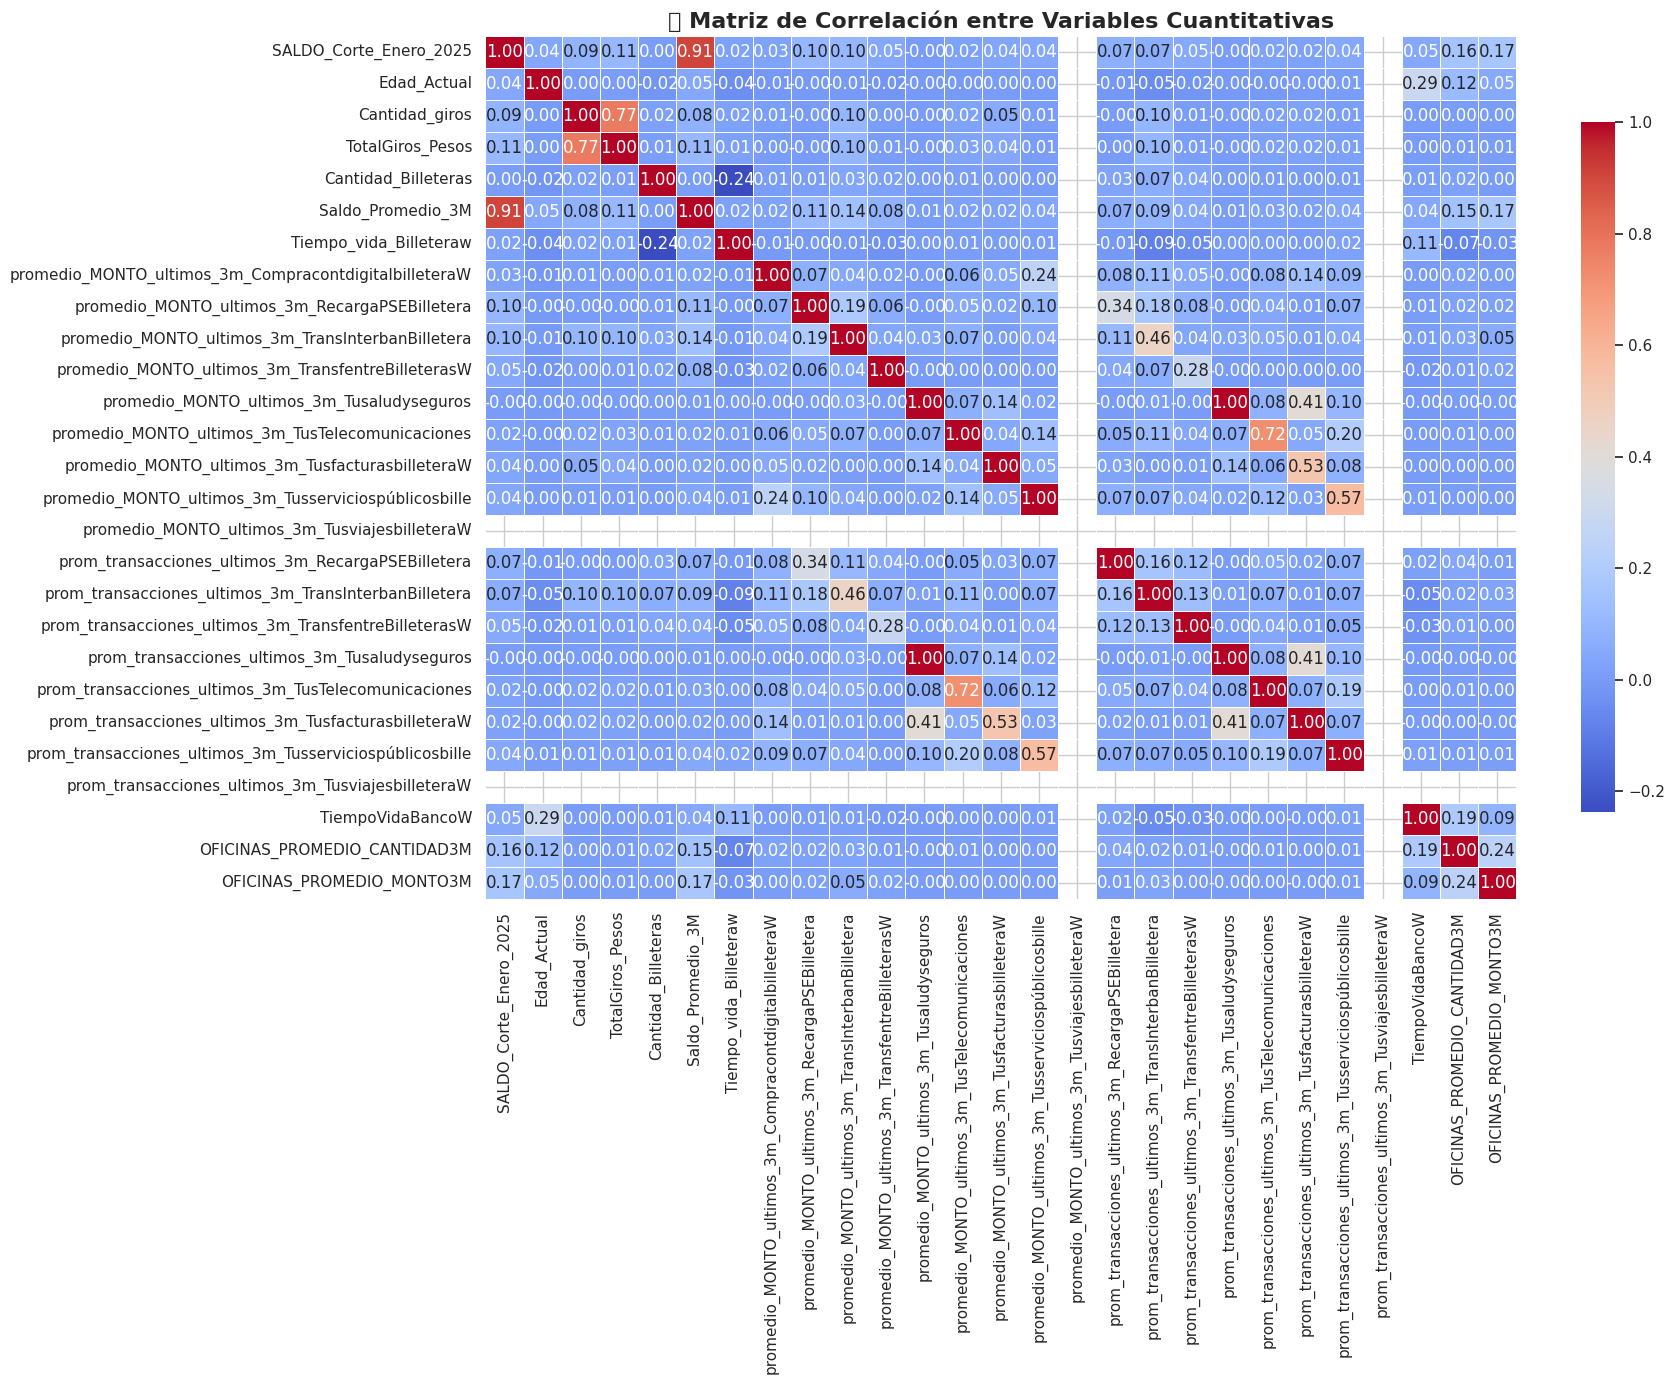

In [ ]:

# 📌 Lista de variables cuantitativas
variables_cuantitativas = [
    "SALDO_Corte_Enero_2025", "Edad_Actual", "Cantidad_giros", "TotalGiros_Pesos", "Cantidad_Billeteras",
    "Saldo_Promedio_3M", "Tiempo_vida_Billeteraw",
    "promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW", "promedio_MONTO_ultimos_3m_RecargaPSEBilletera",
    "promedio_MONTO_ultimos_3m_TransInterbanBilletera", "promedio_MONTO_ultimos_3m_TransfentreBilleterasW",
    "promedio_MONTO_ultimos_3m_Tusaludyseguros", "promedio_MONTO_ultimos_3m_TusTelecomunicaciones",
    "promedio_MONTO_ultimos_3m_TusfacturasbilleteraW", "promedio_MONTO_ultimos_3m_Tusserviciospúblicosbille",
    "promedio_MONTO_ultimos_3m_TusviajesbilleteraW",
    "prom_transacciones_ultimos_3m_RecargaPSEBilletera", "prom_transacciones_ultimos_3m_TransInterbanBilletera",
    "prom_transacciones_ultimos_3m_TransfentreBilleterasW", "prom_transacciones_ultimos_3m_Tusaludyseguros",
    "prom_transacciones_ultimos_3m_TusTelecomunicaciones", "prom_transacciones_ultimos_3m_TusfacturasbilleteraW",
    "prom_transacciones_ultimos_3m_Tusserviciospúblicosbille", "prom_transacciones_ultimos_3m_TusviajesbilleteraW",
    "TiempoVidaBancoW", "OFICINAS_PROMEDIO_CANTIDAD3M", "OFICINAS_PROMEDIO_MONTO3M"
]

# 🔍 Calcular matriz de correlación
matriz_corr = df[variables_cuantitativas].corr(method='pearson')

# 🎨 Crear heatmap con valores anotados
plt.figure(figsize=(18, 14))
sns.heatmap(
    matriz_corr,
    annot=True,  # 👈 Aquí activamos las anotaciones
    fmt=".2f",   # 🔢 Formato de 2 decimales
    cmap="coolwarm",
    linewidths=0.5,
    cbar_kws={"shrink": 0.8}
)

# 📌 Título y estética
plt.title("🔗 Matriz de Correlación entre Variables Cuantitativas", fontsize=16, fontweight="bold")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
# 📌 Convertir la matriz de correlación a un DataFrame plano (long format)
correlaciones_flat = (
    matriz_corr.where(~np.eye(matriz_corr.shape[0], dtype=bool))  # elimina diagonal (autocorrelación)
    .stack()  # convierte a formato largo
    .reset_index()
    .rename(columns={"level_0": "Variable_1", "level_1": "Variable_2", 0: "Correlación"})
)

# 📌 Evitar duplicados tipo A-B y B-A
correlaciones_flat["Pair"] = correlaciones_flat.apply(
    lambda x: tuple(sorted([x["Variable_1"], x["Variable_2"]])), axis=1
)
correlaciones_flat = correlaciones_flat.drop_duplicates("Pair").drop(columns="Pair")

# 📌 Ordenar por valor absoluto de la correlación
correlaciones_ordenadas = correlaciones_flat.reindex(
    correlaciones_flat["Correlación"].abs().sort_values(ascending=False).index
)

# 📊 Mostrar las 15 más altas
top_corr = correlaciones_ordenadas.head(15)

print("\n🔝 **Top 15 pares de variables más correlacionadas (positiva o negativamente):**\n")
print(top_corr)



🔝 **Top 15 pares de variables más correlacionadas (positiva o negativamente):**

                                            Variable_1  \
281          promedio_MONTO_ultimos_3m_Tusaludyseguros   
4                               SALDO_Corte_Enero_2025   
50                                      Cantidad_giros   
306    promedio_MONTO_ultimos_3m_TusTelecomunicaciones   
356  promedio_MONTO_ultimos_3m_Tusserviciospúblicos...   
331    promedio_MONTO_ultimos_3m_TusfacturasbilleteraW   
231   promedio_MONTO_ultimos_3m_TransInterbanBilletera   
451      prom_transacciones_ultimos_3m_Tusaludyseguros   
283          promedio_MONTO_ultimos_3m_Tusaludyseguros   
206      promedio_MONTO_ultimos_3m_RecargaPSEBilletera   
45                                         Edad_Actual   
256   promedio_MONTO_ultimos_3m_TransfentreBilleterasW   
181  promedio_MONTO_ultimos_3m_Compracontdigitalbil...   
101                                Cantidad_Billeteras   
575                       OFICINAS_PROMEDIO_CANT

In [ ]:
bloque_saldos_montos = [
    "SALDO_Corte_Enero_2025",
    "Saldo_Promedio_3M",
    "promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW",
    "promedio_MONTO_ultimos_3m_RecargaPSEBilletera",
    "promedio_MONTO_ultimos_3m_TransInterbanBilletera",
    "promedio_MONTO_ultimos_3m_TransfentreBilleterasW",
    "promedio_MONTO_ultimos_3m_Tusaludyseguros",
    "promedio_MONTO_ultimos_3m_TusTelecomunicaciones",
    "promedio_MONTO_ultimos_3m_TusfacturasbilleteraW",
    "promedio_MONTO_ultimos_3m_Tusserviciospúblicosbille",
    "promedio_MONTO_ultimos_3m_TusviajesbilleteraW"
]


In [ ]:
# Definir la lista de variables cuantitativas proporcionadas
variables_cuantitativas = [
    "Edad_Actual", "SALDO_Corte_Enero_2025", "Saldo_Promedio_3M", "Tiempo_vida_Billeteraw",
    "prom_transacciones_dia_tipo_CompracontdigitalbilleteraW",
    "prom_transacciones_dia_tipo_RecargaPSEBilletera",
    "prom_transacciones_dia_tipo_TransInterbanBilletera",
    "prom_transacciones_dia_tipo_TransfentreBilleterasW",
    "prom_transacciones_dia_tipo_Tusaludyseguros",
    "prom_transacciones_dia_tipo_TusTelecomunicaciones",
    "prom_transacciones_dia_tipo_TusfacturasbilleteraW",
    "prom_transacciones_dia_tipo_Tusserviciospúblicosbille",
    "prom_transacciones_dia_tipo_TusviajesbilleteraW",
    "promedio_MONTO_ultimo_año_CompracontdigitalbilleteraW",
    "promedio_MONTO_ultimo_año_RecargaPSEBilletera",
    "promedio_MONTO_ultimo_año_TransInterbanBilletera",
    "promedio_MONTO_ultimo_año_TransfentreBilleterasW",
    "promedio_MONTO_ultimo_año_Tusaludyseguros",
    "promedio_MONTO_ultimo_año_TusTelecomunicaciones",
    "promedio_MONTO_ultimo_año_TusfacturasbilleteraW",
    "promedio_MONTO_ultimo_año_Tusserviciospúblicosbille",
    "promedio_MONTO_ultimo_año_TusviajesbilleteraW",
    "total_MONTO_ultimo_año_CompracontdigitalbilleteraW",
    "total_MONTO_ultimo_año_RecargaPSEBilletera",
    "total_MONTO_ultimo_año_TransInterbanBilletera",
    "total_MONTO_ultimo_año_TransfentreBilleterasW",
    "total_MONTO_ultimo_año_Tusaludyseguros",
    "total_MONTO_ultimo_año_TusTelecomunicaciones",
    "total_MONTO_ultimo_año_TusfacturasbilleteraW",
    "total_MONTO_ultimo_año_Tusserviciospúblicosbille",
    "total_MONTO_ultimo_año_TusviajesbilleteraW",
    "TiempoVidaBancoW",
    "CORRESPONSALES_PROMEDIO_CANTIDAD12M", "CORRESPONSALES_PROMEDIO_CANTIDAD3M",
    "CORRESPONSALES_PROMEDIO_MONTO12M", "CORRESPONSALES_PROMEDIO_MONTO3M",
    "OFICINAS_PROMEDIO_CANTIDAD12M", "OFICINAS_PROMEDIO_CANTIDAD3M",
    "OFICINAS_PROMEDIO_MONTO12M", "OFICINAS_PROMEDIO_MONTO3M",
    "Total_año_Consulta_Cuenta_Ahorro", "Total_año_Consulta_Estado_Cuenta_Ahorro",
    "Total_año_Consulta_OTP_Retiro", "Total_año_Creación_de_Deposito",

]

# 📊 **1. Estadísticas Descriptivas**
print("\n📊 **Resumen Estadístico de Variables Cuantitativas:**\n")
print(df[variables_cuantitativas].describe())

# 📉 **2. Histogramas y Boxplots para Identificar Distribuciones y Outliers**
for var in variables_cuantitativas:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Histograma con KDE
    sns.histplot(df[var], bins=30, kde=True, ax=axes[0], color="#009CA6")
    axes[0].set_title(f"Distribución de {var}")
    axes[0].set_xlabel(var)

    # Boxplot para detectar outliers
    sns.boxplot(x=df[var], ax=axes[1], color="#FF6900")
    axes[1].set_title(f"Boxplot de {var}")

    plt.tight_layout()
    plt.show()




Output hidden; open in https://colab.research.google.com to view.

## Data visualization

### Subtask:
Create visualizations to illustrate the distributions and relationships between key variables in the dataset. Focus on visualizations that highlight potential segments within the data.



📊 **Resumen estadístico de variables numéricas por Indicador_empleado:**



Saldo_Promedio_3M                                    \
                               count       mean        std  min    25%   
Indicador_empleado                                                       
No                         71,911.00  41,072.12 326,357.03 0.00   0.00   
Si                          1,135.00 210,906.85 803,412.57 0.00 166.49   

                                                    Tiempo_vida_Billeteraw  \
                        50%       75%           max                  count   
Indicador_empleado                                                           
No                     0.00  1,141.83 10,136,956.90              71,911.00   
Si                 2,859.75 25,699.00  9,934,838.27               1,135.00   

                          ... OFICINAS_TOTAL_CANTIDAD12M         \
                    mean  ...                        75%    max   
Indicador_empleado        ...                                     
No                  6.65  ...                       0.00 123.00   
Si                 12.85  ...                       5.00  80.00   

                   OFICINAS_TOTAL_MONTO12M                                    \
                                     count       mean          std  min  25%   
Indicador_empleado                                                             
No                               71,911.00 303,582.26 2,760,755.36 0.00 0.00   
Si                                1,135.00 836,166.34 2,680,668.23 0.00 0.00   

                                                        
                         50%        75%            max  
Indicador_empleado                                      
No                      0.00       0.00 201,858,500.00  
Si                 10,000.00 254,000.00  33,783,876.50  

[2 rows x 96 columns]

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


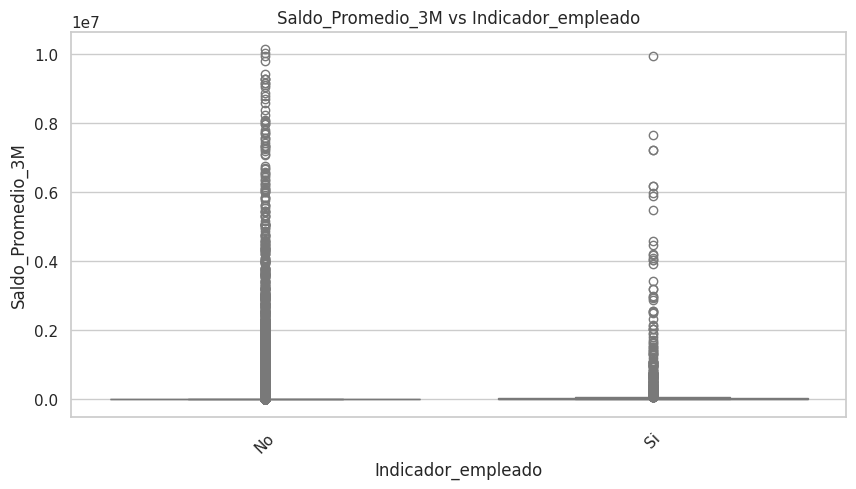

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


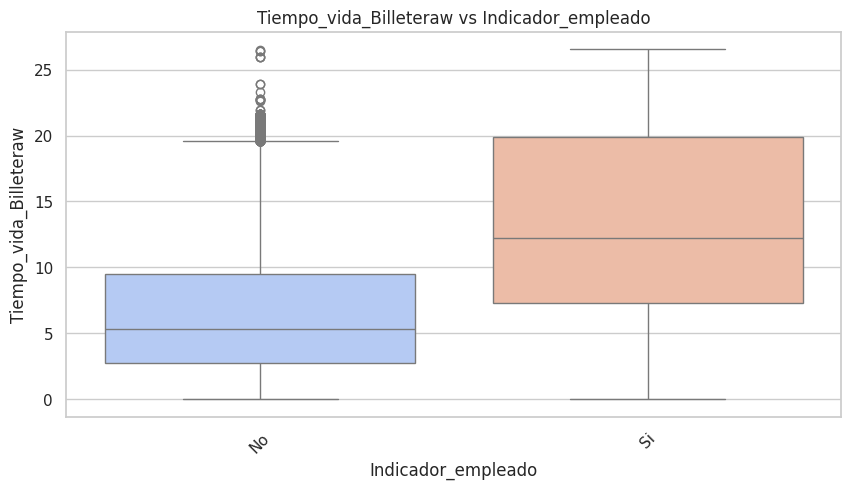

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


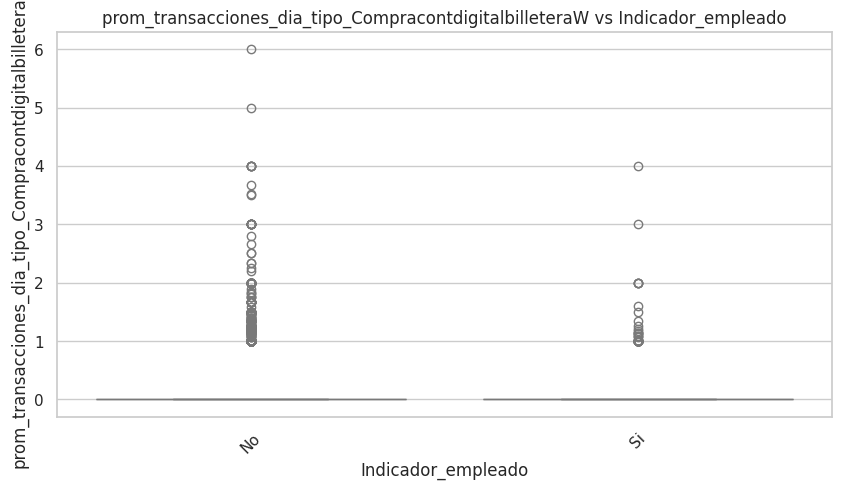

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


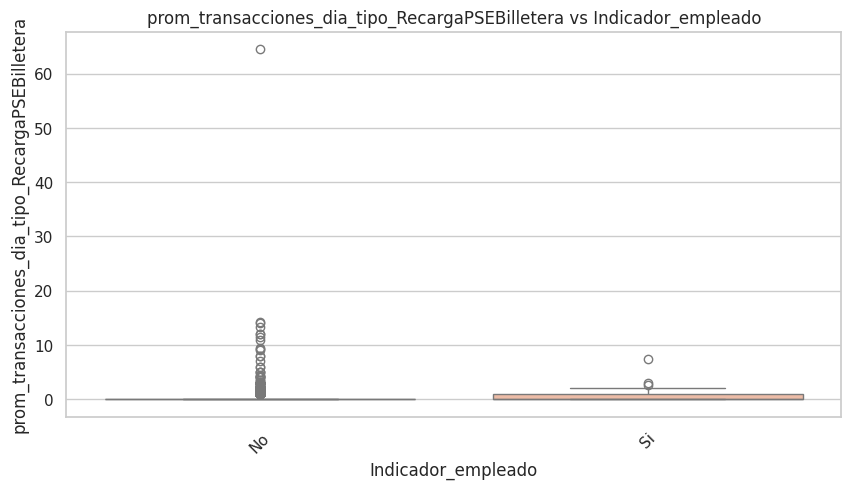

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


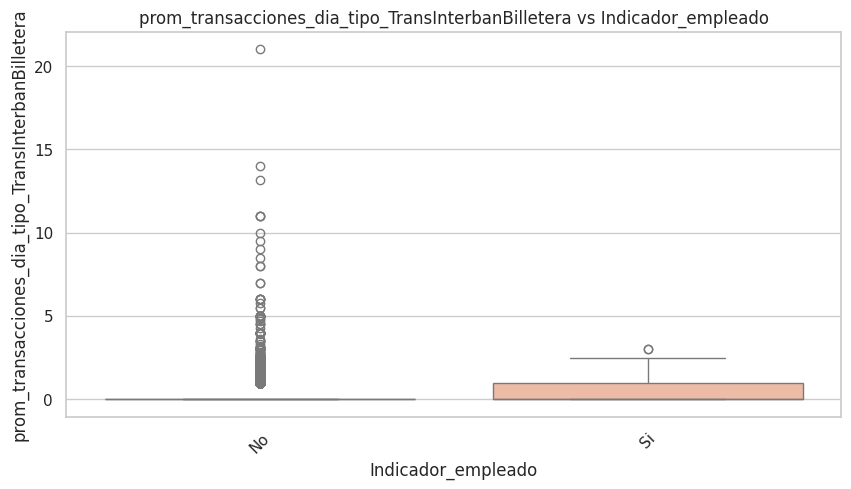

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


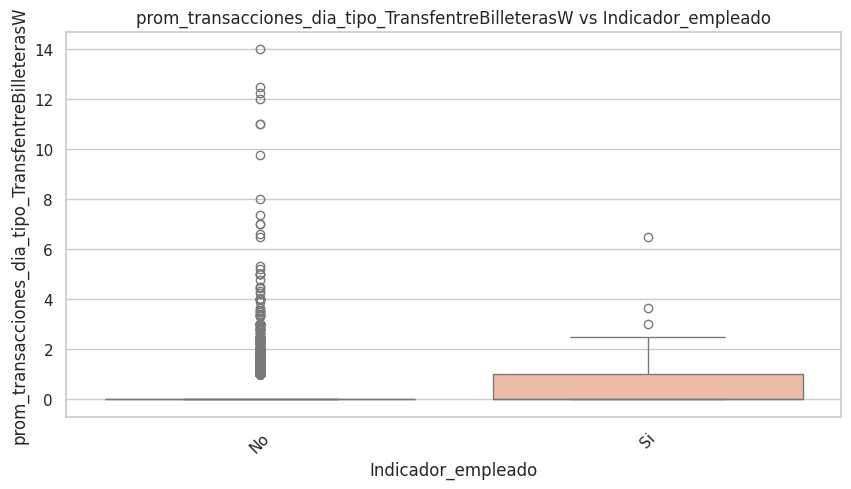

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


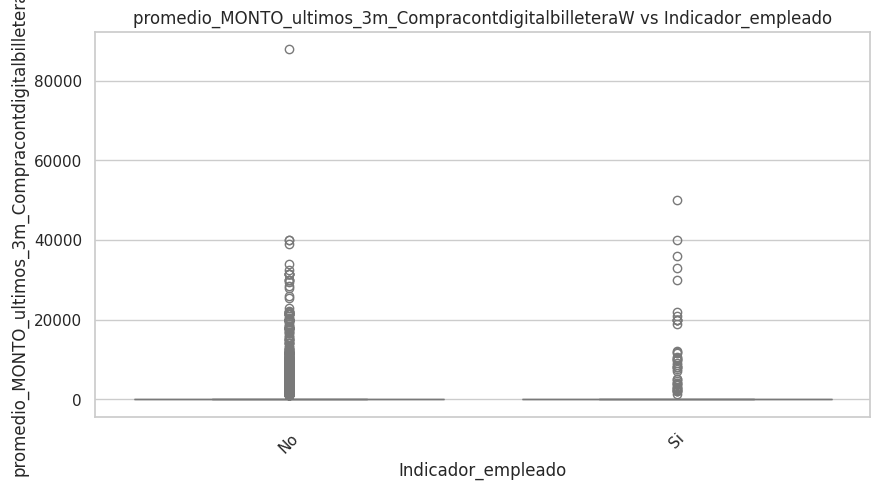

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


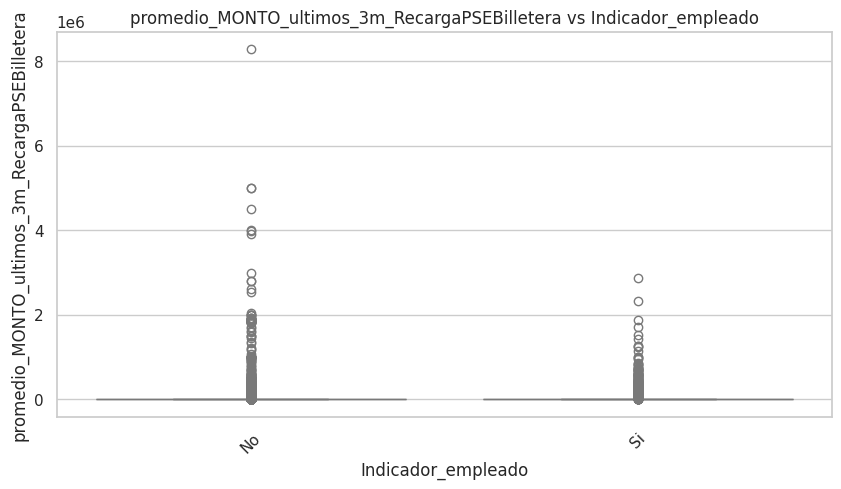

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


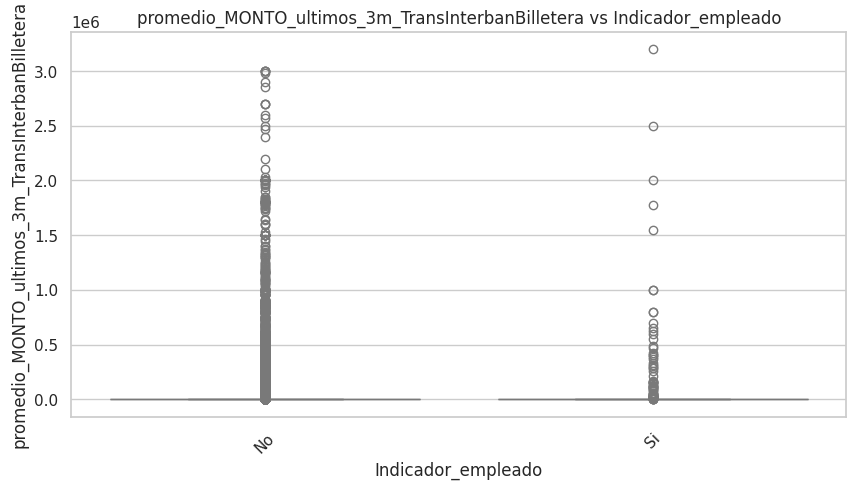

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


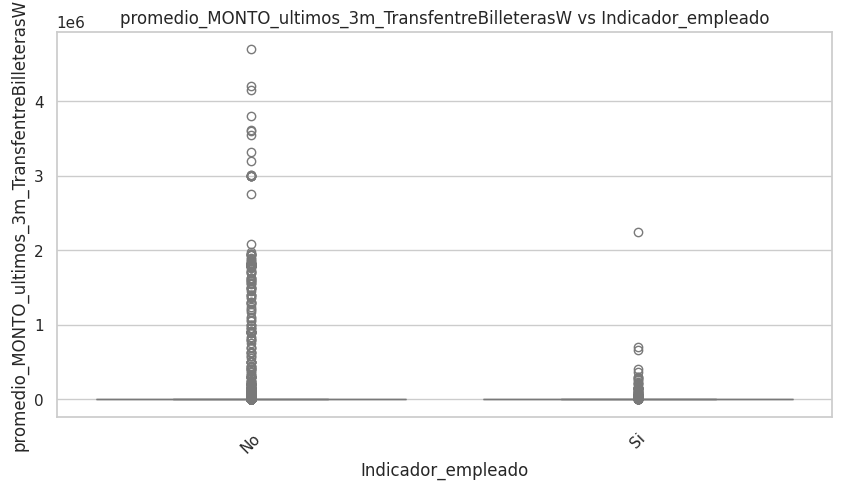

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


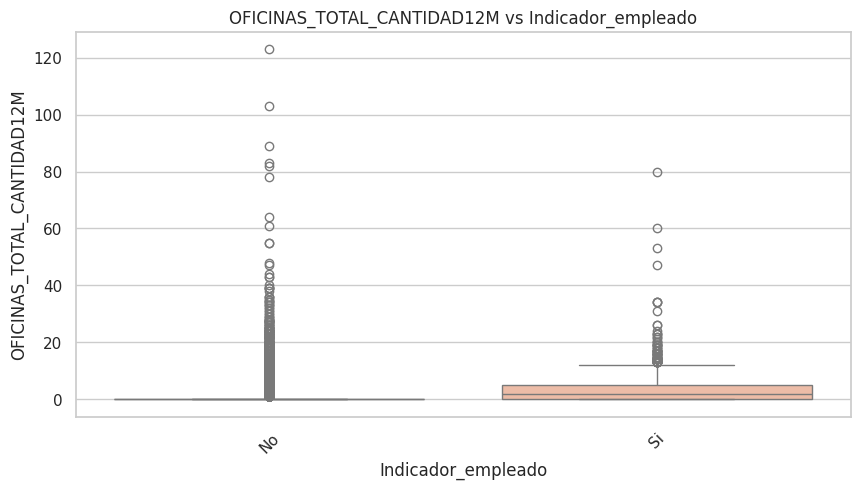

<ipython-input-49-8c6bf75fde73>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


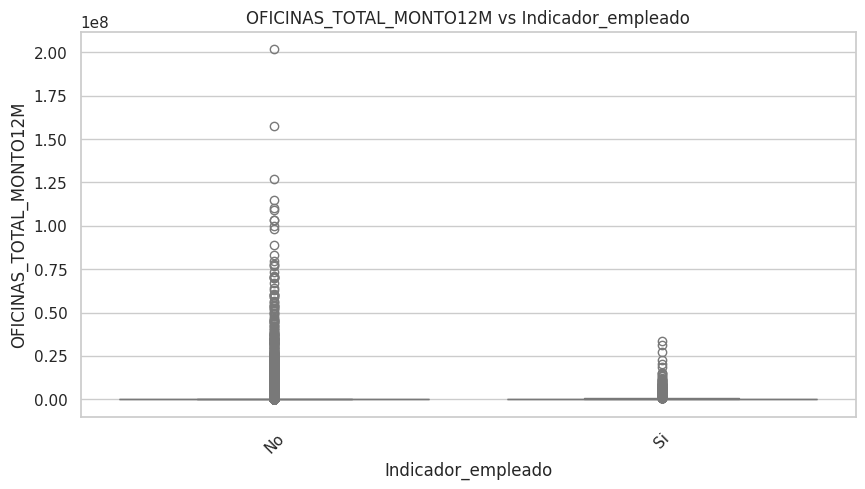

In [ ]:

# 📌 Definir la variable categórica y las numéricas
cat_var = "Indicador_empleado"
num_vars = [
    "Saldo_Promedio_3M", "Tiempo_vida_Billeteraw", "prom_transacciones_dia_tipo_CompracontdigitalbilleteraW",
    "prom_transacciones_dia_tipo_RecargaPSEBilletera", "prom_transacciones_dia_tipo_TransInterbanBilletera",
    "prom_transacciones_dia_tipo_TransfentreBilleterasW", "promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW",
    "promedio_MONTO_ultimos_3m_RecargaPSEBilletera", "promedio_MONTO_ultimos_3m_TransInterbanBilletera",
    "promedio_MONTO_ultimos_3m_TransfentreBilleterasW", "OFICINAS_TOTAL_CANTIDAD12M", "OFICINAS_TOTAL_MONTO12M"
]

# 📊 1. Calcular estadísticas descriptivas por categoría
print(f"\n📊 **Resumen estadístico de variables numéricas por {cat_var}:**\n")
display(df.groupby(cat_var)[num_vars].describe())

# 📈 2. Visualizar relación con Boxplots
for num_var in num_vars:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")
    plt.title(f"{num_var} vs {cat_var}")
    plt.xlabel(cat_var)
    plt.ylabel(num_var)
    plt.xticks(rotation=45)
    plt.show()



📊 **Resumen estadístico de variables numéricas por ESTADOPRODUCTO_Corte:**



Saldo_Promedio_3M                                       \
                                 count         mean        std          min   
ESTADOPRODUCTO_Corte                                                          
Bloqueo Completo                  7.00     1,038.44     541.85        12.78   
Bloqueo Compliance              285.00    42,268.37 200,802.05         0.00   
Bloqueo Debitos                   1.00 1,341,527.92        NaN 1,341,527.92   
Cuentas Inactivas            24,289.00     4,174.09  98,377.76         0.00   
Icetex Inactiva               1,800.00     8,085.17  14,062.89         0.00   
Normal                       46,664.00    65,651.97 416,943.01         0.00   

                                                                           \
                              25%          50%          75%           max   
ESTADOPRODUCTO_Corte                                                        
Bloqueo Completo           827.67     1,287.10     1,397.94      1,518.00   
Bloqueo Compliance           0.00       150.51    10,036.38  1,841,180.20   
Bloqueo Debitos      1,341,527.92 1,341,527.92 1,341,527.92  1,341,527.92   
Cuentas Inactivas            0.00         0.00         0.00  9,277,124.45   
Icetex Inactiva             84.10     1,478.53    10,273.27    109,547.03   
Normal                       0.00        15.40     6,693.77 10,136,956.90   

                     Tiempo_vida_Billeteraw        ...  \
                                      count  mean  ...   
ESTADOPRODUCTO_Corte                               ...   
Bloqueo Completo                       7.00  1.17  ...   
Bloqueo Compliance                   285.00  1.34  ...   
Bloqueo Debitos                        1.00  3.65  ...   
Cuentas Inactivas                 24,289.00 10.94  ...   
Icetex Inactiva                    1,800.00 16.38  ...   
Normal                            46,664.00  4.22  ...   

                     OFICINAS_TOTAL_CANTIDAD12M         \
                                            75%    max   
ESTADOPRODUCTO_Corte                                     
Bloqueo Completo                           0.00   1.00   
Bloqueo Compliance                         0.00   4.00   
Bloqueo Debitos                            1.00   1.00   
Cuentas Inactivas                          0.00 103.00   
Icetex Inactiva                            0.00  14.00   
Normal                                     1.00 123.00   

                     OFICINAS_TOTAL_MONTO12M                                   \
                                       count       mean          std      min   
ESTADOPRODUCTO_Corte                                                            
Bloqueo Completo                        7.00     142.86       377.96     0.00   
Bloqueo Compliance                    285.00  32,566.69   291,734.17     0.00   
Bloqueo Debitos                         1.00   1,000.00          NaN 1,000.00   
Cuentas Inactivas                  24,289.00 180,289.58 1,772,365.90     0.00   
Icetex Inactiva                     1,800.00  57,568.15   971,851.08     0.00   
Normal                             46,664.00 391,907.96 3,199,466.17     0.00   

                                                                
                          25%      50%      75%            max  
ESTADOPRODUCTO_Corte                                            
Bloqueo Completo         0.00     0.00     0.00       1,000.00  
Bloqueo Compliance       0.00     0.00     0.00   3,800,000.00  
Bloqueo Debitos      1,000.00 1,000.00 1,000.00       1,000.00  
Cuentas Inactivas        0.00     0.00     0.00  66,981,200.00  
Icetex Inactiva          0.00     0.00     0.00  29,110,000.00  
Normal                   0.00     0.00   200.00 201,858,500.00  

[6 rows x 96 columns]

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


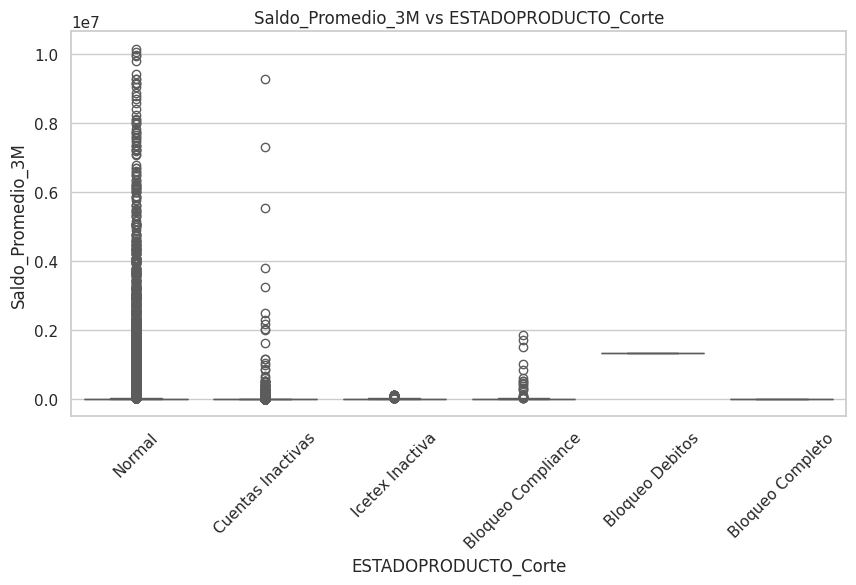

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


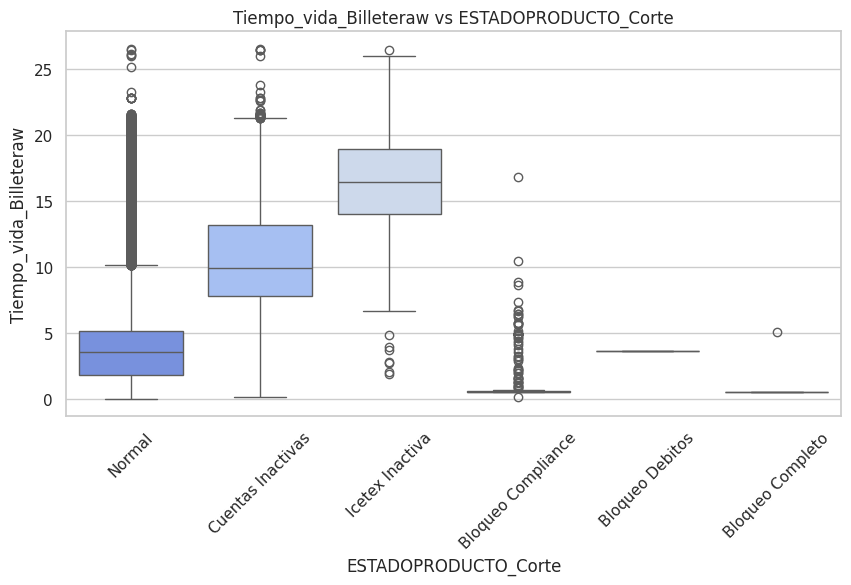

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


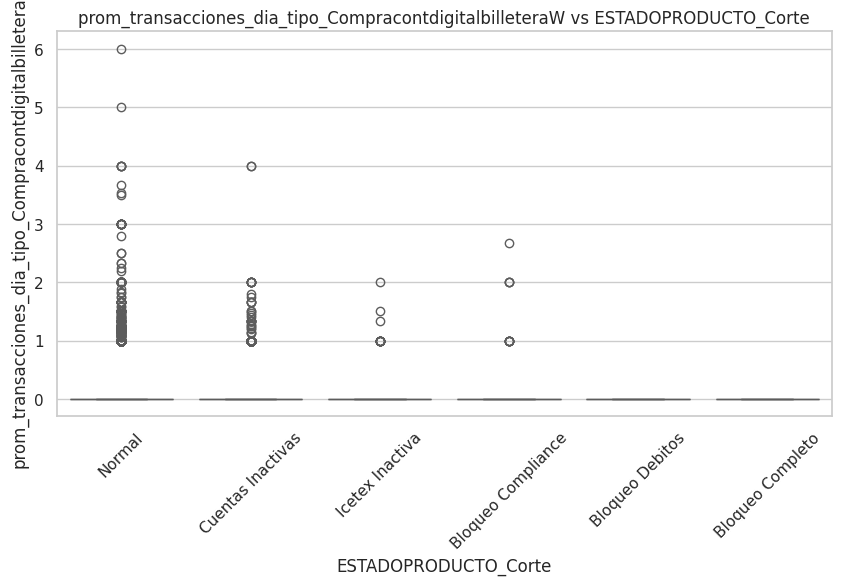

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


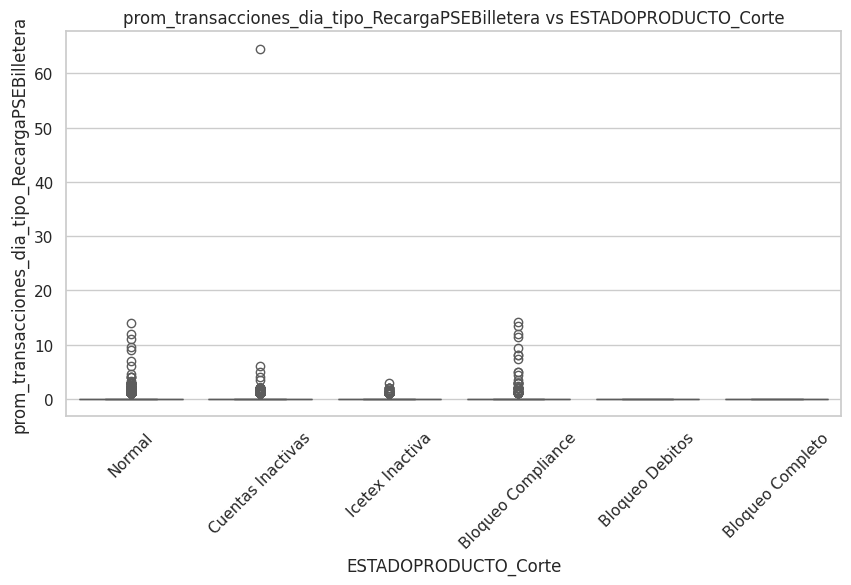

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


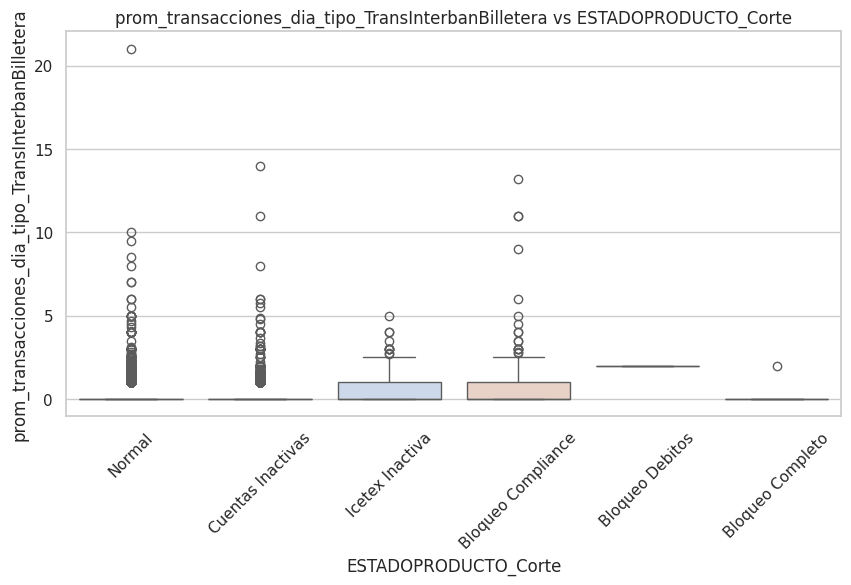

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


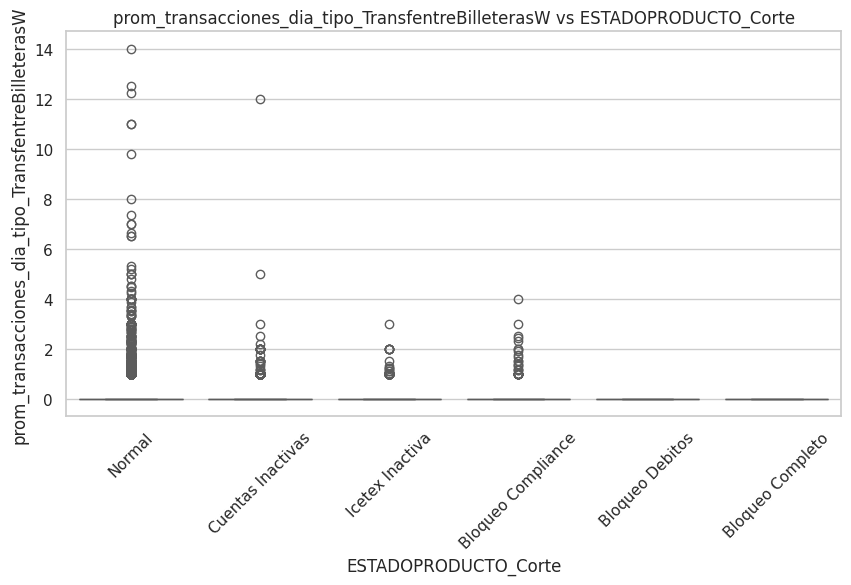

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


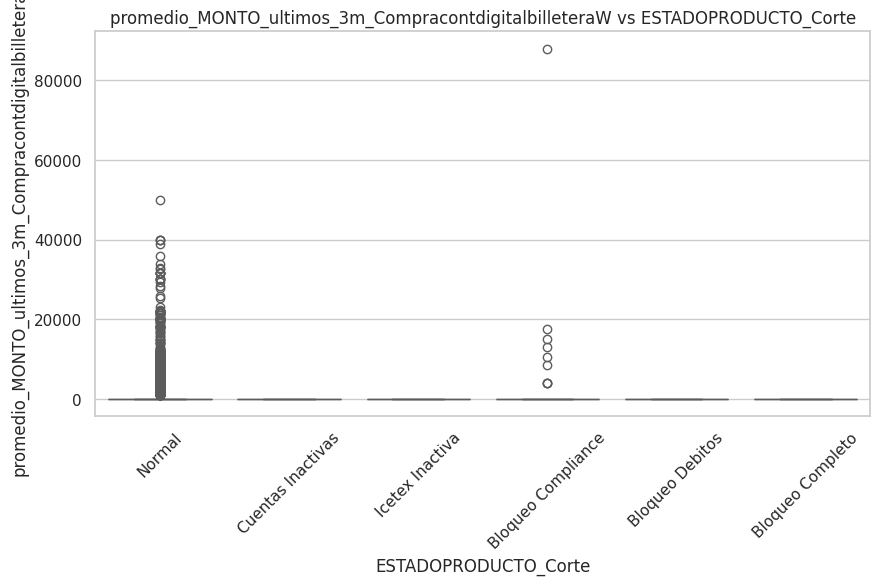

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


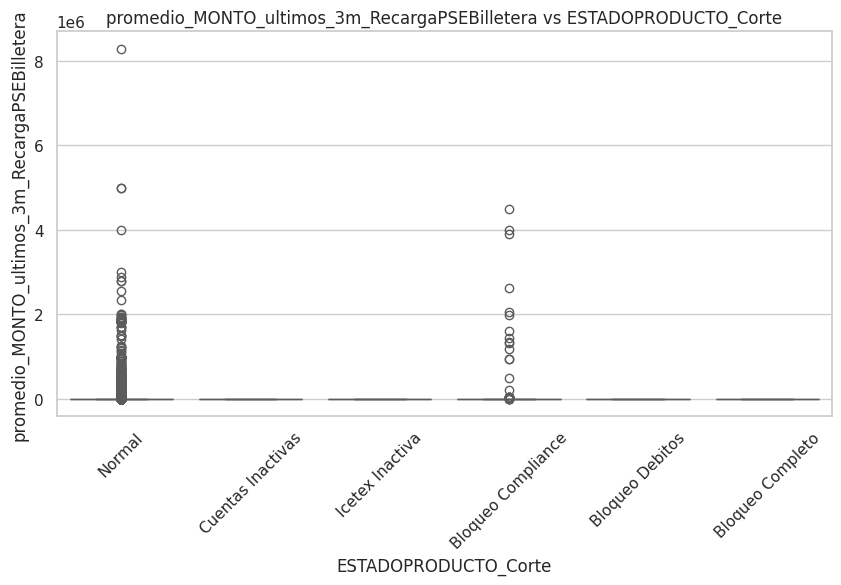

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


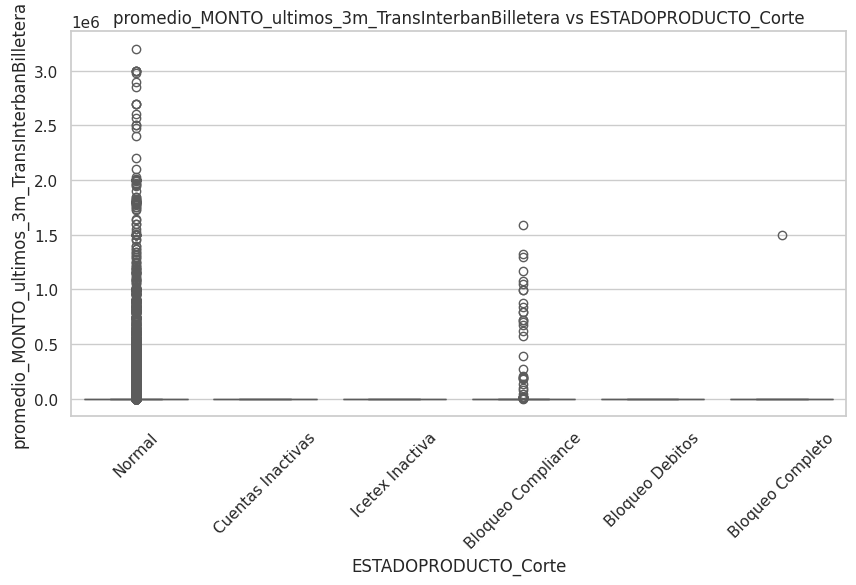

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


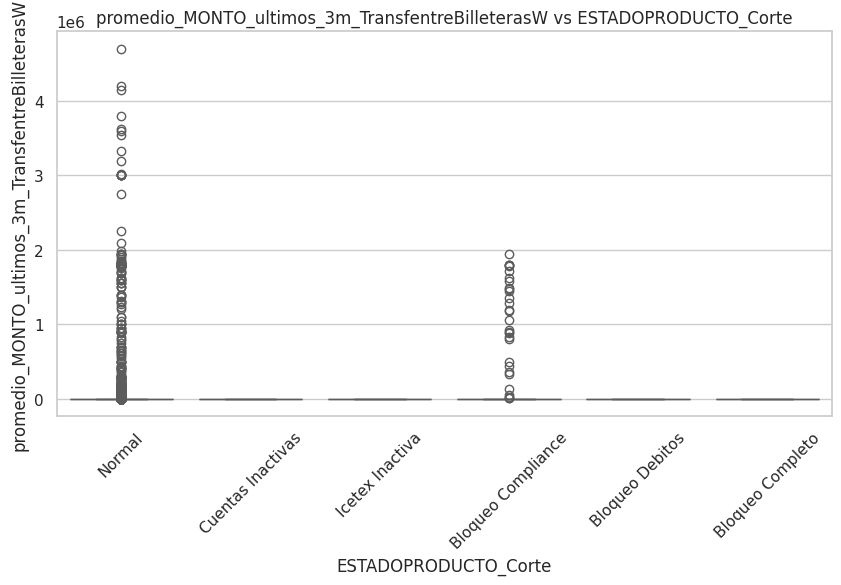

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


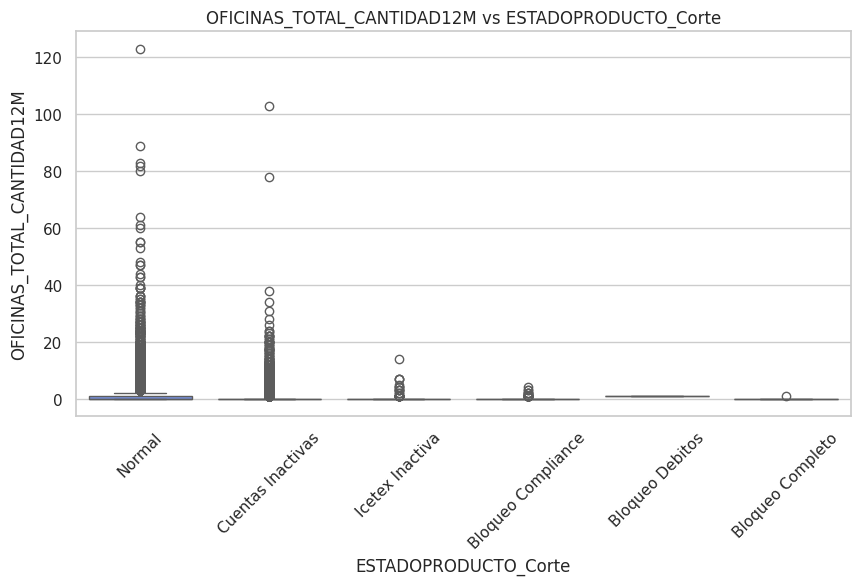

<ipython-input-50-ce657d4b420a>:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


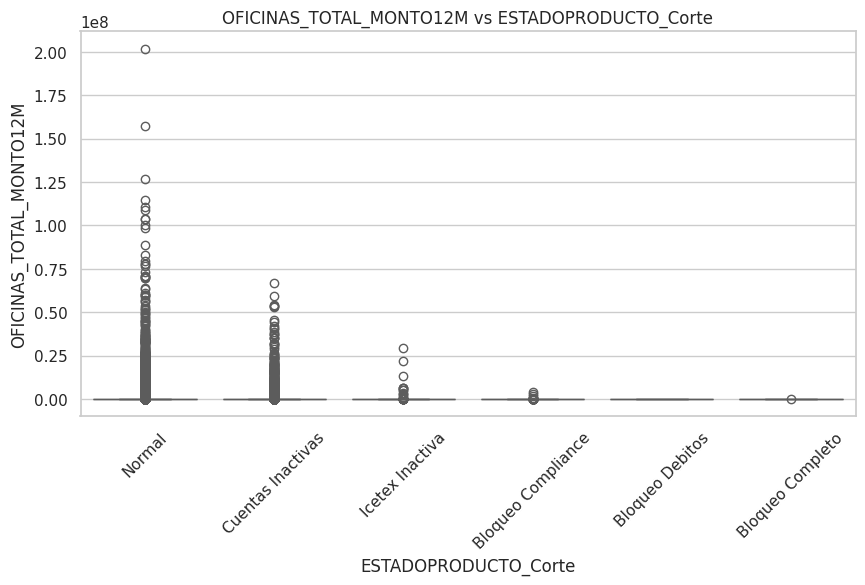

In [ ]:
# 📌 Definir la variable categórica y las numéricas
cat_var = "ESTADOPRODUCTO_Corte"
num_vars = [
    "Saldo_Promedio_3M", "Tiempo_vida_Billeteraw", "prom_transacciones_dia_tipo_CompracontdigitalbilleteraW",
    "prom_transacciones_dia_tipo_RecargaPSEBilletera", "prom_transacciones_dia_tipo_TransInterbanBilletera",
    "prom_transacciones_dia_tipo_TransfentreBilleterasW", "promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW",
    "promedio_MONTO_ultimos_3m_RecargaPSEBilletera", "promedio_MONTO_ultimos_3m_TransInterbanBilletera",
    "promedio_MONTO_ultimos_3m_TransfentreBilleterasW", "OFICINAS_TOTAL_CANTIDAD12M", "OFICINAS_TOTAL_MONTO12M"
]

# 📊 1. Calcular estadísticas descriptivas por categoría
print(f"\n📊 **Resumen estadístico de variables numéricas por {cat_var}:**\n")
display(df.groupby(cat_var)[num_vars].describe())

# 📈 2. Visualizar relación con Boxplots
for num_var in num_vars:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")
    plt.title(f"{num_var} vs {cat_var}")
    plt.xlabel(cat_var)
    plt.ylabel(num_var)
    plt.xticks(rotation=45)
    plt.show()



📊 **Resumen estadístico de variables numéricas por Rangos_Antiguedad_Billeteraw:**



<ipython-input-51-e977535cb013>:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  display(df.groupby(cat_var)[num_vars].describe())


Saldo_Promedio_3M                             \
                                         count       mean        std  min   
Rangos_Antiguedad_Billeteraw                                                
Menos de un mes                       4,909.00  41,812.88 365,116.95 0.00   
De 1 a menos de 3 meses              14,897.00  43,159.22 328,124.46 0.00   
De 3 a menos de 6 meses              20,256.00  41,722.19 310,871.29 0.00   
De 6 a menos de 12 meses             21,526.00  36,632.51 304,905.85 0.00   
De 12 a menos de 18 meses             8,349.00  46,977.47 363,748.11 0.00   
Más de 18 meses                       3,109.00 102,548.58 592,207.46 0.00   

                                                               
                              25%  50%      75%           max  
Rangos_Antiguedad_Billeteraw                                   
Menos de un mes              0.00 0.00 1,416.20 10,038,484.72  
De 1 a menos de 3 meses      0.00 0.00 4,331.38  8,783,276.08  
De 3 a menos de 6 meses      0.00 0.00 1,519.16 10,136,956.90  
De 6 a menos de 12 meses     0.00 0.00   732.15  9,791,195.19  
De 12 a menos de 18 meses    0.00 0.00 1,015.25  9,947,775.43  
Más de 18 meses              0.00 0.00 3,600.89  9,277,124.45

<ipython-input-51-e977535cb013>:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")


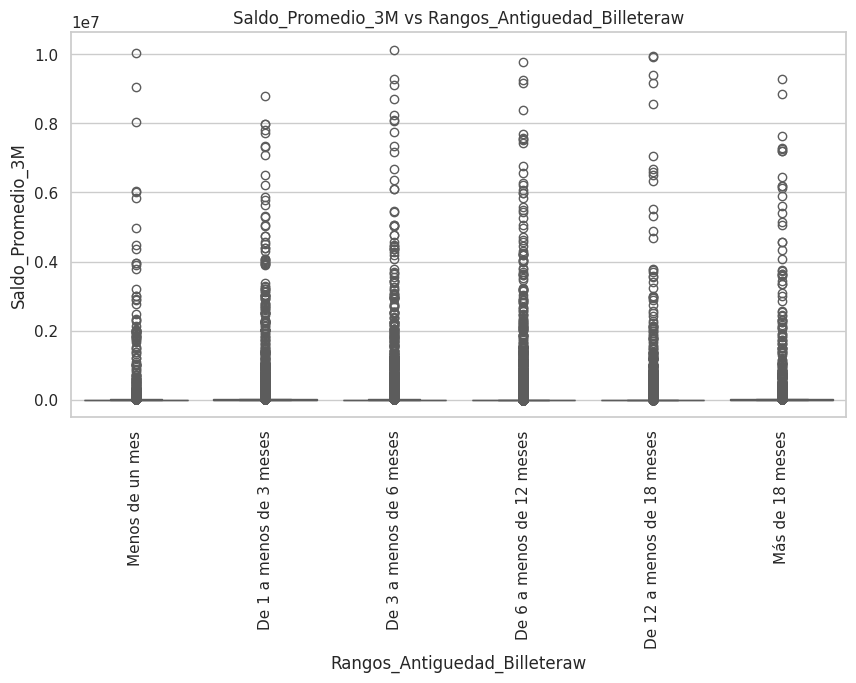

In [ ]:
# 📌 Definir la variable categórica y las numéricas
cat_var = "Rangos_Antiguedad_Billeteraw"
num_vars = [
    "Saldo_Promedio_3M",
]

# 📊 1. Calcular estadísticas descriptivas por categoría
print(f"\n📊 **Resumen estadístico de variables numéricas por {cat_var}:**\n")
display(df.groupby(cat_var)[num_vars].describe())

# 📈 2. Visualizar relación con Boxplots
for num_var in num_vars:
    plt.figure(figsize=(10, 5))
    sns.boxplot(x=df[cat_var], y=df[num_var], palette="coolwarm")
    plt.title(f"{num_var} vs {cat_var}")
    plt.xlabel(cat_var)
    plt.ylabel(num_var)
    plt.xticks(rotation=90)
    plt.show()


In [ ]:
# Filtrar usuarios que NO están marcados como fraude
df = df[df["Indicador_usuario_fraude"] != "Si"]
print(df.shape)
df["Indicador_usuario_fraude"].unique()



(72780, 242)


array(['No'], dtype=object)

## MODELAMIENTO

In [ ]:
# Lista de variables con las cuales se va a segmentar#
variables_segmentacion = [
    "Generacion", "SALDO_Corte_Enero_2025", "Indicador_empleado", "Indicador_Giros_Billetera",
     "tiene_billetera_mercado","Rangos_SaldoPromedio3M", "Rangos_SaldoPromedio6M","Rangos_Antiguedad_Billeteraw", "Indicador_TM",
    "promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW", "promedio_MONTO_ultimos_3m_RecargaPSEBilletera",
    "promedio_MONTO_ultimos_3m_TransInterbanBilletera", "promedio_MONTO_ultimos_3m_TransfentreBilleterasW",
    "prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW", "prom_transacciones_ultimos_3m_RecargaPSEBilletera",
    "prom_transacciones_ultimos_3m_TransInterbanBilletera", "prom_transacciones_ultimos_3m_TransfentreBilleterasW",
    "indicadorCreditos", "indicadorCDT", "indicadorGiros", "indicadorSeguros", "IVC", "CasosPQRS_Ultimos3Meses",
    "exclusivos_billetera", "TiempoVidaBancoW",
    "OFICINAS_PROMEDIO_CANTIDAD3M", "OFICINAS_PROMEDIO_MONTO3M",
    "Indicador_canal_fisico","Promedio3Meses_Consulta_OTP_Retiro", "Promedio3Meses_Creación_de_Deposito",
    "Indicador_TNM"
]

In [ ]:
# Crear el nuevo DataFrame
df_segmentacion = df[variables_segmentacion].copy()


In [ ]:
df_segmentacion.head()


,Generacion,SALDO_Corte_Enero_2025,Indicador_empleado,Indicador_Giros_Billetera,tiene_billetera_mercado,Rangos_SaldoPromedio3M,Rangos_SaldoPromedio6M,Rangos_Antiguedad_Billeteraw,Indicador_TM,promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW,...,IVC,CasosPQRS_Ultimos3Meses,exclusivos_billetera,TiempoVidaBancoW,OFICINAS_PROMEDIO_CANTIDAD3M,OFICINAS_PROMEDIO_MONTO3M,Indicador_canal_fisico,Promedio3Meses_Consulta_OTP_Retiro,Promedio3Meses_Creación_de_Deposito,Indicador_TNM
0,Millennials,"1,020.21",No,No,Si,Hasta $5000,Hasta $5000,De 3 a menos de 6 meses,No,0.00,...,3,0,No,13,0,0.00,Si,0.00,0,No
1,Generación Z,0.00,No,No,No,Sin saldo,Sin saldo,De 12 a menos de 18 meses,No,0.00,...,0,0,Si,13,0,0.00,No,0.00,0,No
2,Generación Z,0.00,No,No,No,Sin saldo,Sin saldo,De 12 a menos de 18 meses,No,0.00,...,0,0,Si,12,0,0.00,No,0.00,0,No
3,Generación Z,0.00,No,No,No,Sin saldo,Sin saldo,De 12 a menos de 18 meses,No,0.00,...,0,0,Si,17,0,0.00,No,0.00,0,No
4,Generación Z,0.00,No,No,No,Sin saldo,Sin saldo,De 12 a menos de 18 meses,No,0.00,...,0,0,Si,14,0,0.00,No,0.00,0,No


In [ ]:
# 📌 Tomar una muestra de 20.000 registros de df_segmentacion
df_sample = df_segmentacion.sample(n=20000, random_state=42)

# 📋 Ver forma de la muestra
print(f"✅ Forma de la muestra: {df_sample.shape}")


✅ Forma de la muestra: (20000, 31)


# **Aplicación K-PROTOTYPES**

In [ ]:
# ---------------------------------------
# 1. 🚀 INSTALACIÓN DEL PAQUETE
# (¡Ejecutar una sola vez!)
# ---------------------------------------
!pip install kmodes --quiet


In [ ]:
# ---------------------------------------
# 2. 📦 IMPORTACIÓN DE LIBRERÍAS
# ---------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as shc
import warnings
warnings.filterwarnings('ignore')

# ✅ Librería para clustering mixto
from kmodes.kprototypes import KPrototypes


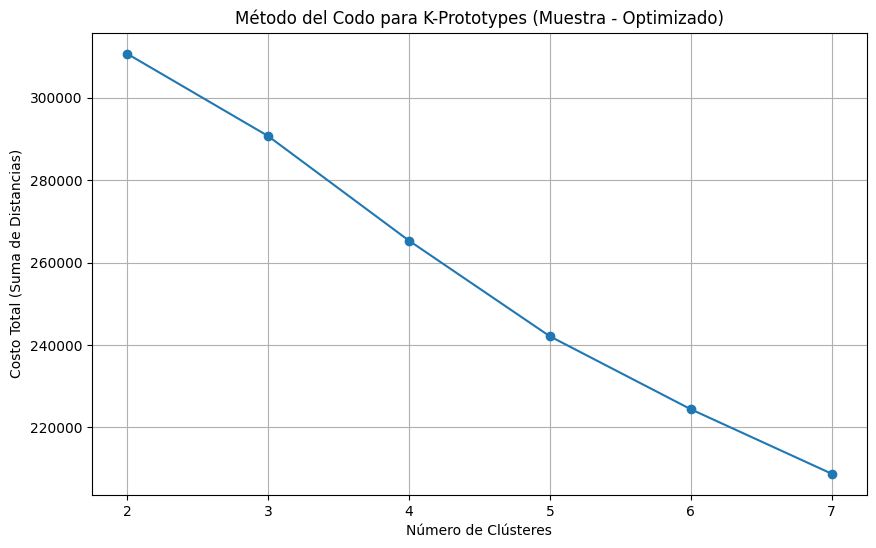

In [ ]:
# 1. Identificar columnas numéricas y categóricas EN LA MUESTRA
columnas_numericas_sample = df_sample.select_dtypes(include=['number']).columns.tolist()
columnas_categoricas_sample = df_sample.select_dtypes(exclude=['number']).columns.tolist()

# 2. Preprocesamiento (Escalado de variables numéricas) EN LA MUESTRA
scaler_sample = StandardScaler()
df_sample[columnas_numericas_sample] = scaler_sample.fit_transform(df_sample[columnas_numericas_sample])

# 3. Convertir el DataFrame de la muestra a un array de NumPy
data_sample = df_sample.values

# 4. Obtener los índices de las columnas categóricas EN LA MUESTRA
indices_categoricas_sample = [df_sample.columns.get_loc(col) for col in columnas_categoricas_sample]

# 5. Aplicar el método del codo EN LA MUESTRA (Optimizado)
costos_sample = []
rango_n_clusters = range(2, 8) # Reducir el rango a 2-7

for n_clusters in rango_n_clusters:
    kproto_sample = KPrototypes(n_clusters=n_clusters, init='Cao', n_init=3, verbose=0, random_state=42) # Reducir n_init
    kproto_sample.fit(data_sample, categorical=indices_categoricas_sample)
    costos_sample.append(kproto_sample.cost_)

# 6. Graficar los resultados para encontrar el "codo"
plt.figure(figsize=(10, 6))
plt.plot(rango_n_clusters, costos_sample, marker='o', linestyle='-')
plt.title('Método del Codo para K-Prototypes (Muestra - Optimizado)')
plt.xlabel('Número de Clústeres')
plt.ylabel('Costo Total (Suma de Distancias)')
plt.xticks(rango_n_clusters)
plt.grid(True)
plt.show()

In [ ]:
df_sample

,Generacion,SALDO_Corte_Enero_2025,Indicador_empleado,Indicador_Giros_Billetera,tiene_billetera_mercado,Rangos_SaldoPromedio3M,Rangos_SaldoPromedio6M,Rangos_Antiguedad_Billeteraw,Indicador_TM,promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW,...,IVC,CasosPQRS_Ultimos3Meses,exclusivos_billetera,TiempoVidaBancoW,OFICINAS_PROMEDIO_CANTIDAD3M,OFICINAS_PROMEDIO_MONTO3M,Indicador_canal_fisico,Promedio3Meses_Consulta_OTP_Retiro,Promedio3Meses_Creación_de_Deposito,Indicador_TNM
62546,Generación X,-0.12,No,No,No,Sin saldo,Sin saldo,De 6 a menos de 12 meses,No,-0.06,...,-1.30,-0.05,Si,-0.48,-0.25,-0.10,No,-0.09,0.00,Si
17789,Millennials,-0.12,No,No,Si,Sin saldo,Sin saldo,Menos de un mes,No,-0.06,...,-0.40,-0.05,No,0.56,-0.25,-0.10,No,-0.09,0.00,Si
37431,Millennials,-0.12,No,No,Si,Hasta $5000,Hasta $5000,De 3 a menos de 6 meses,No,-0.06,...,-0.40,-0.05,Si,-0.61,-0.25,-0.10,Si,-0.09,0.00,Si
40250,Generación Z,-0.11,No,No,No,Hasta $5000,Hasta $5000,Más de 18 meses,Si,-0.06,...,-1.30,-0.05,Si,-0.13,-0.25,-0.10,No,-0.09,0.00,Si
13553,Generación Z,-0.12,No,No,Si,Sin saldo,Sin saldo,De 3 a menos de 6 meses,No,-0.06,...,-0.40,-0.05,Si,-0.58,-0.25,-0.10,No,-0.09,0.00,Si
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
55953,Generación X,-0.07,No,No,Si,De $20.001 a $50.000,De $20.001 a $50.000,De 1 a menos de 3 meses,No,-0.06,...,0.49,-0.05,No,2.26,2.80,0.39,Si,-0.09,0.00,Si
725,Generación Z,-0.12,No,No,Si,Sin saldo,Sin saldo,De 1 a menos de 3 meses,No,-0.06,...,-0.40,-0.05,Si,0.14,-0.25,-0.10,No,-0.09,0.00,No
48598,Generación Z,-0.12,No,No,No,Sin saldo,Sin saldo,De 6 a menos de 12 meses,No,-0.06,...,-1.30,-0.05,Si,-0.42,-0.25,-0.10,No,-0.09,0.00,Si
49479,Millennials,-0.12,No,No,No,Hasta $5000,Hasta $5000,De 12 a menos de 18 meses,Si,-0.06,...,-1.30,-0.05,No,0.29,-0.25,-0.10,No,-0.09,0.00,Si


In [ ]:
# 1. Obtener los índices de las columnas categóricas EN LA MUESTRA
indices_categoricas_sample = [df_sample.columns.get_loc(col) for col in columnas_categoricas_sample]

# 2. Convertir el DataFrame de la muestra a un array de NumPy
data_sample = df_sample.values

# 3. Inicializar y ejecutar K-Prototypes con 5 clústeres
n_clusters = 5
kproto_sample = KPrototypes(n_clusters=n_clusters, init='Cao', n_init=10, verbose=2, random_state=42) # Aumenté n_init para mejor convergencia
clusters_sample = kproto_sample.fit_predict(data_sample, categorical=indices_categoricas_sample)

# 4. Añadir las etiquetas de los clústeres al DataFrame de la muestra
df_sample['Cluster'] = clusters_sample

# 5. Mostrar los primeros resultados
print("Primeras filas de df_sample con las etiquetas de los clústeres:")
print(df_sample.head())

# 6. Mostrar el tamaño de cada clúster en la muestra
print("\nTamaño de cada clúster en la muestra:")
print(df_sample['Cluster'].value_counts().sort_index())

# 7. Mostrar los centroides de los clústeres (prototipos)
print("\nCentroides de los clústeres (prototipos):")
print(kproto_sample.cluster_centers_)

Initialization method and algorithm are deterministic. Setting n_init to 1.
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run: 1, iteration: 1/100, moves: 4948, ncost: 262201.9050455597
Run: 1, iteration: 2/100, moves: 956, ncost: 256123.98459116335
Run: 1, iteration: 3/100, moves: 385, ncost: 251921.99151884537
Run: 1, iteration: 4/100, moves: 148, ncost: 249490.4256839454
Run: 1, iteration: 5/100, moves: 79, ncost: 247500.5903196197
Run: 1, iteration: 6/100, moves: 80, ncost: 245291.40325602642
Run: 1, iteration: 7/100, moves: 78, ncost: 243127.49723221638
Run: 1, iteration: 8/100, moves: 68, ncost: 242898.8498511931
Run: 1, iteration: 9/100, moves: 81, ncost: 242673.96640521192
Run: 1, iteration: 10/100, moves: 23, ncost: 242636.7611557548
Run: 1, iteration: 11/100, moves: 1, ncost: 242636.76028955696
Run: 1, iteration: 12/100, moves: 0, ncost: 242636.76028955696
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run: 2,

AttributeError: 'KPrototypes' object has no attribute 'cluster_centers_'

In [ ]:
lista_columnas_df_sample = df_sample.columns.tolist()
print(lista_columnas_df_sample)

['Generacion', 'SALDO_Corte_Enero_2025', 'Indicador_empleado', 'Indicador_Giros_Billetera', 'tiene_billetera_mercado', 'Rangos_SaldoPromedio3M', 'Rangos_SaldoPromedio6M', 'Rangos_Antiguedad_Billeteraw', 'Indicador_TM', 'promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW', 'promedio_MONTO_ultimos_3m_RecargaPSEBilletera', 'promedio_MONTO_ultimos_3m_TransInterbanBilletera', 'promedio_MONTO_ultimos_3m_TransfentreBilleterasW', 'prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW', 'prom_transacciones_ultimos_3m_RecargaPSEBilletera', 'prom_transacciones_ultimos_3m_TransInterbanBilletera', 'prom_transacciones_ultimos_3m_TransfentreBilleterasW', 'indicadorCreditos', 'indicadorCDT', 'indicadorGiros', 'indicadorSeguros', 'IVC', 'CasosPQRS_Ultimos3Meses', 'exclusivos_billetera', 'TiempoVidaBancoW', 'OFICINAS_PROMEDIO_CANTIDAD3M', 'OFICINAS_PROMEDIO_MONTO3M', 'Indicador_canal_fisico', 'Promedio3Meses_Consulta_OTP_Retiro', 'Promedio3Meses_Creación_de_Deposito', 'Indicador_TNM', 'Cluster']


📊 Resumen de variables más importantes por clúster:


Cluster,0,1,2,3,4,Cluster_Máximo
prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW,-0.04,-0.07,0.15,-0.07,11.69,4
promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW,-0.05,-0.06,0.01,-0.06,10.06,4
prom_transacciones_ultimos_3m_RecargaPSEBilletera,-0.06,-0.11,8.31,-0.11,0.90,2
OFICINAS_PROMEDIO_MONTO3M,4.32,-0.04,0.08,-0.08,0.06,0
promedio_MONTO_ultimos_3m_RecargaPSEBilletera,-0.04,-0.06,4.29,-0.06,0.20,2
SALDO_Corte_Enero_2025,4.01,-0.06,0.45,-0.07,0.18,0
promedio_MONTO_ultimos_3m_TransfentreBilleterasW,2.89,-0.05,0.27,-0.05,0.13,0
promedio_MONTO_ultimos_3m_TransInterbanBilletera,2.97,-0.07,0.83,-0.05,0.45,0
OFICINAS_PROMEDIO_CANTIDAD3M,2.64,0.10,0.30,-0.15,0.36,0
prom_transacciones_ultimos_3m_TransfentreBilleterasW,2.07,-0.09,1.04,-0.02,0.39,0


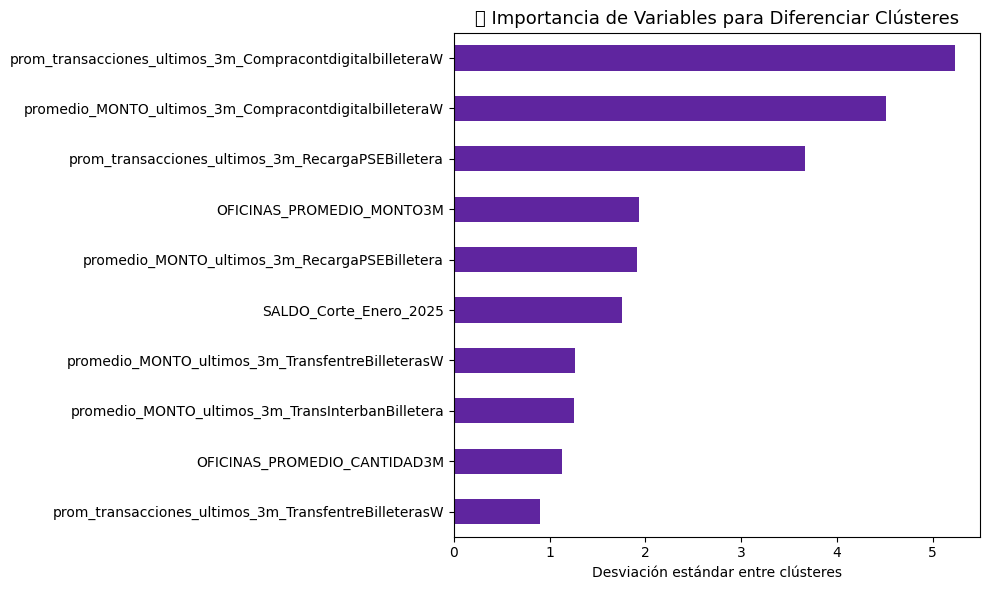

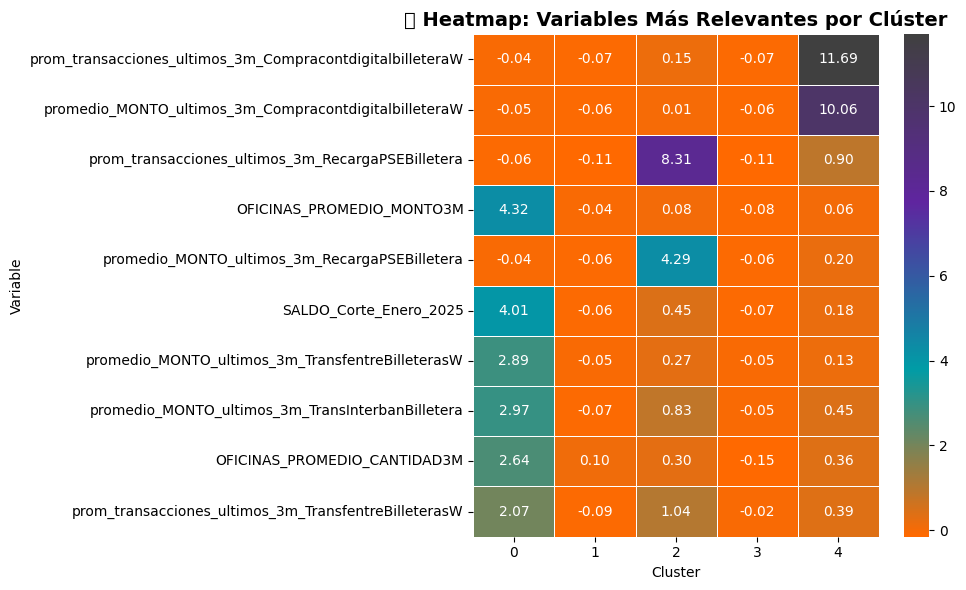

In [ ]:
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# 1️⃣ Variables numéricas sin 'cluster'
numericas = df_sample.select_dtypes(include=["int64", "float64"]).columns.tolist()
numericas = [col for col in numericas if col != "Cluster"]

# 2️⃣ Desviación estándar entre clústeres para evaluar importancia
importancia_vars = df_sample.groupby("Cluster")[numericas].mean().std().sort_values(ascending=False)

# 3️⃣ Seleccionar las top 10 más discriminantes
top_variables = importancia_vars.head(10).index.tolist()

# 4️⃣ Promedios por clúster para estas variables
tabla_resumen = df_sample.groupby("Cluster")[top_variables].mean().round(2)

# 5️⃣ Crear resumen con clúster donde cada variable es más alta
resumen_final = tabla_resumen.T.copy()
resumen_final["Cluster_Máximo"] = resumen_final.idxmax(axis=1)

# 🔹 Mostrar la tabla resumen
print("📊 Resumen de variables más importantes por clúster:")
display(resumen_final)

# 6️⃣ 📊 Gráfico de barras: Importancia de variables
plt.figure(figsize=(10, 6))
importancia_vars.head(10).plot(kind="barh", color="#5F259F")  # Morado institucional
plt.gca().invert_yaxis()
plt.title("🎯 Importancia de Variables para Diferenciar Clústeres", fontsize=13)
plt.xlabel("Desviación estándar entre clústeres")
plt.tight_layout()
plt.show()

# 7️⃣ 🔥 Heatmap con colores institucionales
tabla_heatmap = resumen_final.drop(columns="Cluster_Máximo")

# 🎨 Crear un colormap con la paleta institucional
colores_personalizados = ["#FF6900", "#009CA6", "#5F259F", "#404040"]
cmap_inst = LinearSegmentedColormap.from_list("institucional", colores_personalizados)

plt.figure(figsize=(10, 6))
sns.heatmap(tabla_heatmap, annot=True, cmap=cmap_inst, linewidths=0.5, fmt=".2f")

plt.title("🔥 Heatmap: Variables Más Relevantes por Clúster", fontsize=14, fontweight="bold")
plt.xlabel("Cluster")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# 1️⃣ Quitar la columna de clúster (no usarla en UMAP)
df_umap_input = df_sample.drop(columns=["Cluster"], errors='ignore')

# 2️⃣ Detectar variables numéricas y categóricas
columnas_numericas_umap = df_umap_input.select_dtypes(include=["number"]).columns.tolist()
columnas_categoricas_umap = df_umap_input.select_dtypes(exclude=["number"]).columns.tolist()

# 3️⃣ Codificar variables categóricas
df_umap_cat = pd.DataFrame(index=df_umap_input.index)

for col in columnas_categoricas_umap:
    if df_umap_input[col].nunique() == 2:
        le = LabelEncoder()
        df_umap_cat[col] = le.fit_transform(df_umap_input[col])
    else:
        dummies = pd.get_dummies(df_umap_input[col], prefix=col, drop_first=True)
        df_umap_cat = pd.concat([df_umap_cat, dummies], axis=1)

# 4️⃣ Unir numéricas + categóricas codificadas
df_umap_ready = pd.concat([
    df_umap_input[columnas_numericas_umap],  # numéricas ya normalizadas
    df_umap_cat  # categóricas codificadas
], axis=1)

# ✅ Resultado final
print("✅ Dataset listo para aplicar UMAP:", df_umap_ready.shape)
df_umap_ready.head()


✅ Dataset listo para aplicar UMAP: (20000, 50)


,SALDO_Corte_Enero_2025,promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW,promedio_MONTO_ultimos_3m_RecargaPSEBilletera,promedio_MONTO_ultimos_3m_TransInterbanBilletera,promedio_MONTO_ultimos_3m_TransfentreBilleterasW,prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW,prom_transacciones_ultimos_3m_RecargaPSEBilletera,prom_transacciones_ultimos_3m_TransInterbanBilletera,prom_transacciones_ultimos_3m_TransfentreBilleterasW,IVC,...,Rangos_Antiguedad_Billeteraw_De 12 a menos de 18 meses,Rangos_Antiguedad_Billeteraw_Más de 18 meses,Indicador_TM,indicadorCreditos,indicadorCDT,indicadorGiros,indicadorSeguros,exclusivos_billetera,Indicador_canal_fisico,Indicador_TNM
62546,-0.12,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-1.30,...,False,False,0,0,0,0,0,1,0,1
17789,-0.12,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-0.40,...,False,False,0,0,0,0,0,0,0,1
37431,-0.12,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-0.40,...,False,False,0,0,0,0,0,1,1,1
40250,-0.11,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-1.30,...,False,True,1,0,0,0,0,1,0,1
13553,-0.12,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-0.40,...,False,False,0,0,0,0,0,1,0,1


In [ ]:
!pip install umap-learn


In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# 1️⃣ Quitar la columna de clúster (no usarla en UMAP)
df_umap_input = df_sample.drop(columns=["Cluster"], errors='ignore')

# 2️⃣ Detectar variables numéricas y categóricas
columnas_numericas_umap = df_umap_input.select_dtypes(include=["number"]).columns.tolist()
columnas_categoricas_umap = df_umap_input.select_dtypes(exclude=["number"]).columns.tolist()

# 3️⃣ Codificar variables categóricas
df_umap_cat = pd.DataFrame(index=df_umap_input.index)

for col in columnas_categoricas_umap:
    if df_umap_input[col].nunique() == 2:
        le = LabelEncoder()
        df_umap_cat[col] = le.fit_transform(df_umap_input[col])
    else:
        dummies = pd.get_dummies(df_umap_input[col], prefix=col, drop_first=True)
        df_umap_cat = pd.concat([df_umap_cat, dummies], axis=1)

# 4️⃣ Unir numéricas + categóricas codificadas
df_umap_ready = pd.concat([
    df_umap_input[columnas_numericas_umap],  # numéricas ya normalizadas
    df_umap_cat  # categóricas codificadas
], axis=1)

# ✅ Resultado final
print("✅ Dataset listo para aplicar UMAP:", df_umap_ready.shape)
df_umap_ready.head()


✅ Dataset listo para aplicar UMAP: (20000, 50)


,SALDO_Corte_Enero_2025,promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW,promedio_MONTO_ultimos_3m_RecargaPSEBilletera,promedio_MONTO_ultimos_3m_TransInterbanBilletera,promedio_MONTO_ultimos_3m_TransfentreBilleterasW,prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW,prom_transacciones_ultimos_3m_RecargaPSEBilletera,prom_transacciones_ultimos_3m_TransInterbanBilletera,prom_transacciones_ultimos_3m_TransfentreBilleterasW,IVC,...,Rangos_Antiguedad_Billeteraw_De 12 a menos de 18 meses,Rangos_Antiguedad_Billeteraw_Más de 18 meses,Indicador_TM,indicadorCreditos,indicadorCDT,indicadorGiros,indicadorSeguros,exclusivos_billetera,Indicador_canal_fisico,Indicador_TNM
62546,-0.12,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-1.30,...,False,False,0,0,0,0,0,1,0,1
17789,-0.12,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-0.40,...,False,False,0,0,0,0,0,0,0,1
37431,-0.12,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-0.40,...,False,False,0,0,0,0,0,1,1,1
40250,-0.11,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-1.30,...,False,True,1,0,0,0,0,1,0,1
13553,-0.12,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-0.40,...,False,False,0,0,0,0,0,1,0,1


In [ ]:
import umap.umap_ as umap
import matplotlib.pyplot as plt
import seaborn as sns

# 🎨 Paleta de colores institucional
palette_institucional = ["#FF6900", "#009CA6", "#5F259F", "#404040", "#A1D99B"]

# 🔄 Ejecutar UMAP
umap_model = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=42)
umap_result = umap_model.fit_transform(df_umap_ready)

# 📦 Crear DataFrame con resultado UMAP
df_umap = pd.DataFrame(umap_result, columns=["UMAP1", "UMAP2"])
df_umap["Cluster"] = df_sample["Cluster"].values  # Agregar clúster original


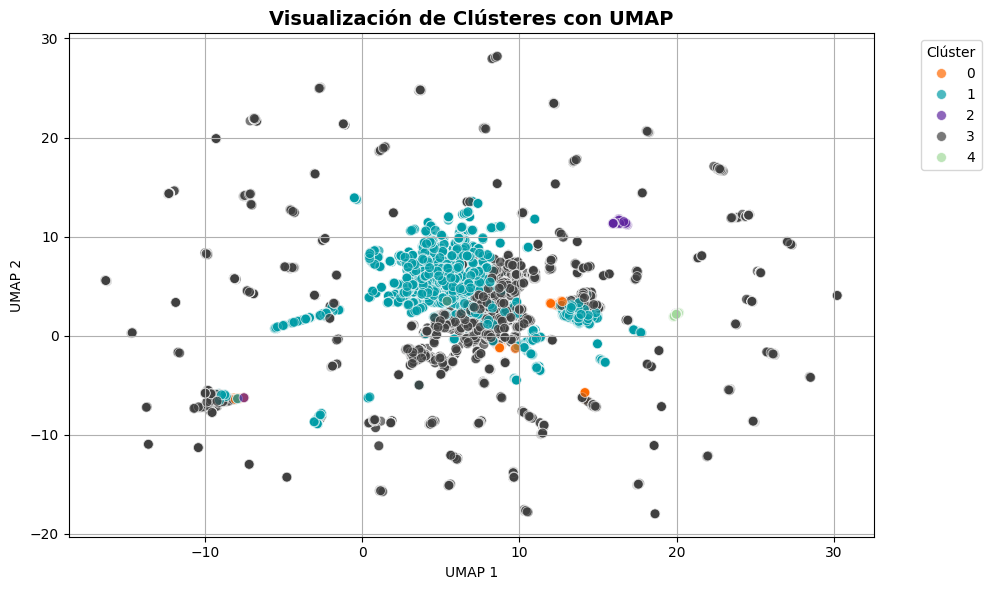

In [ ]:
# 📍 Visualización
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_umap,
    x="UMAP1", y="UMAP2",
    hue="Cluster",
    palette=palette_institucional,
    alpha=0.7,
    s=50
)

plt.title("Visualización de Clústeres con UMAP", fontsize=14, fontweight="bold")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend(title="Clúster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()


SEGUNDA CORRIDA MODELO

In [ ]:
# Lista de variables con las cuales se va a segmentar#
variables_segmentacion_v1 = [
    "Generacion", "SALDO_Corte_Enero_2025", "Promedio_Giro_Pesos","CodActividadEconomica_v2",
 "Saldo_Constante_mayor_10000","tiene_billetera_mercado","Rangos_SaldoPromedio3M","Rangos_Antiguedad_Billeteraw", "Indicador_TM",
    "promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW", "promedio_MONTO_ultimos_3m_RecargaPSEBilletera",
    "promedio_MONTO_ultimos_3m_TransInterbanBilletera", "promedio_MONTO_ultimos_3m_TransfentreBilleterasW",
    "prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW", "prom_transacciones_ultimos_3m_RecargaPSEBilletera",
    "prom_transacciones_ultimos_3m_TransInterbanBilletera", "prom_transacciones_ultimos_3m_TransfentreBilleterasW",
    "indicadorCreditos", "indicadorCDT", "indicadorGiros", "indicadorSeguros", "IVC", "CasosPQRS_Ultimos3Meses",
    "exclusivos_billetera", "TiempoVidaBancoW",
    "OFICINAS_PROMEDIO_CANTIDAD3M", "OFICINAS_PROMEDIO_MONTO3M",
    "Indicador_TNM"
]

In [ ]:
# Crear el nuevo DataFrame
df_segmentacion_v1 = df[variables_segmentacion_v1].copy()

In [ ]:
# 📌 Tomar una muestra de 20.000 registros de df_segmentacion
df_sample_v1 = df_segmentacion_v1.sample(n=20000, random_state=42)

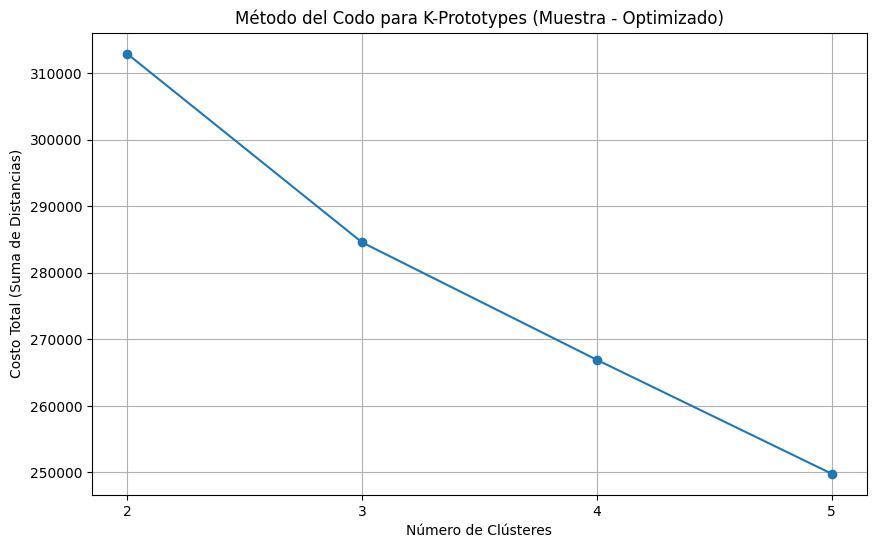

In [ ]:
# 1. Identificar columnas numéricas y categóricas EN LA MUESTRA
columnas_numericas_sample_v1 = df_sample_v1.select_dtypes(include=['number']).columns.tolist()
columnas_categoricas_sample_v1 = df_sample_v1.select_dtypes(exclude=['number']).columns.tolist()

# 2. Preprocesamiento (Escalado de variables numéricas) EN LA MUESTRA
scaler_sample = StandardScaler()
df_sample_v1[columnas_numericas_sample_v1] = scaler_sample.fit_transform(df_sample_v1[columnas_numericas_sample_v1])

# 3. Convertir el DataFrame de la muestra a un array de NumPy
data_sample_v1 = df_sample_v1.values

# 4. Obtener los índices de las columnas categóricas EN LA MUESTRA
indices_categoricas_sample_v1 = [df_sample_v1.columns.get_loc(col) for col in columnas_categoricas_sample_v1]

# 5. Aplicar el método del codo EN LA MUESTRA (Optimizado)
costos_sample_v1 = []
rango_n_clusters_v1 = range(2, 6)

for n_clusters in rango_n_clusters_v1:
    kproto_sample_v1 = KPrototypes(n_clusters=n_clusters, init='Cao', n_init=3, verbose=0, random_state=42) # Reducir n_init
    kproto_sample_v1.fit(data_sample_v1, categorical=indices_categoricas_sample_v1)
    costos_sample_v1.append(kproto_sample_v1.cost_)

# 6. Graficar los resultados para encontrar el "codo"
plt.figure(figsize=(10, 6))
plt.plot(rango_n_clusters_v1, costos_sample_v1, marker='o', linestyle='-')
plt.title('Método del Codo para K-Prototypes (Muestra - Optimizado)')
plt.xlabel('Número de Clústeres')
plt.ylabel('Costo Total (Suma de Distancias)')
plt.xticks(rango_n_clusters_v1)
plt.grid(True)
plt.show()

In [ ]:
# 1. Obtener los índices de las columnas categóricas EN LA MUESTRA
indices_categoricas_sample_v1 = [df_sample_v1.columns.get_loc(col) for col in columnas_categoricas_sample_v1]

# 2. Convertir el DataFrame de la muestra a un array de NumPy
data_sample_v1 = df_sample_v1.values

# 3. Inicializar y ejecutar K-Prototypes con 5 clústeres
n_clusters = 5
kproto_sample_v1 = KPrototypes(n_clusters=n_clusters, init='Cao', n_init=10, verbose=2, random_state=42) # Aumenté n_init para mejor convergencia
clusters_sample_v1 = kproto_sample_v1.fit_predict(data_sample_v1, categorical=indices_categoricas_sample_v1)

# 4. Añadir las etiquetas de los clústeres al DataFrame de la muestra
df_sample_v1['Cluster_v1'] = clusters_sample_v1

# 5. Mostrar los primeros resultados
print("Primeras filas de df_sample con las etiquetas de los clústeres:")
print(df_sample_v1.head())

# 6. Mostrar el tamaño de cada clúster en la muestra
print("\nTamaño de cada clúster en la muestra:")
print(df_sample_v1['Cluster_v1'].value_counts().sort_index())

# 7. Mostrar los centroides de los clústeres (prototipos)
print("\nCentroides de los clústeres (prototipos):")
print(kproto_sample_v1.cluster_centers_)

Initialization method and algorithm are deterministic. Setting n_init to 1.
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run: 1, iteration: 1/100, moves: 1506, ncost: 249183.77706814793
Run: 1, iteration: 2/100, moves: 237, ncost: 244246.6379789931
Run: 1, iteration: 3/100, moves: 62, ncost: 243391.04472594074
Run: 1, iteration: 4/100, moves: 50, ncost: 240561.80076385793
Run: 1, iteration: 5/100, moves: 25, ncost: 240340.4710567776
Run: 1, iteration: 6/100, moves: 24, ncost: 240229.78593154435
Run: 1, iteration: 7/100, moves: 2, ncost: 240228.52097945695
Run: 1, iteration: 8/100, moves: 0, ncost: 240228.52097945695
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run: 2, iteration: 1/100, moves: 5341, ncost: 256758.13392086056
Run: 2, iteration: 2/100, moves: 309, ncost: 253514.04653022642
Run: 2, iteration: 3/100, moves: 66, ncost: 251832.00250953523
Run: 2, iteration: 4/100, moves: 72, ncost: 248826.25772127902
Run: 2

AttributeError: 'KPrototypes' object has no attribute 'cluster_centers_'

In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# 1️⃣ Quitar la columna de clúster (no usarla en UMAP)
df_umap_input_v1 = df_sample_v1.drop(columns=["Cluster_v1"], errors='ignore')

# 2️⃣ Detectar variables numéricas y categóricas
columnas_numericas_umap_v1 = df_umap_input_v1.select_dtypes(include=["number"]).columns.tolist()
columnas_categoricas_umap_v1 = df_umap_input_v1.select_dtypes(exclude=["number"]).columns.tolist()

# 3️⃣ Codificar variables categóricas
df_umap_cat_v1 = pd.DataFrame(index=df_umap_input_v1.index)

for col in columnas_categoricas_umap_v1:
    if df_umap_input_v1[col].nunique() == 2:
        le = LabelEncoder()
        df_umap_cat_v1[col] = le.fit_transform(df_umap_input_v1[col])
    else:
        dummies_v1 = pd.get_dummies(df_umap_input_v1[col], prefix=col, drop_first=True)
        df_umap_cat_v1 = pd.concat([df_umap_cat_v1, dummies_v1], axis=1)

# 4️⃣ Unir numéricas + categóricas codificadas
df_umap_ready_v1 = pd.concat([
    df_umap_input_v1[columnas_numericas_umap_v1],  # numéricas ya normalizadas
    df_umap_cat_v1  # categóricas codificadas
], axis=1)

# ✅ Resultado final
print("✅ Dataset listo para aplicar UMAP:", df_umap_ready_v1.shape)
df_umap_ready_v1.head()

✅ Dataset listo para aplicar UMAP: (20000, 46)


,SALDO_Corte_Enero_2025,Promedio_Giro_Pesos,promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW,promedio_MONTO_ultimos_3m_RecargaPSEBilletera,promedio_MONTO_ultimos_3m_TransInterbanBilletera,promedio_MONTO_ultimos_3m_TransfentreBilleterasW,prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW,prom_transacciones_ultimos_3m_RecargaPSEBilletera,prom_transacciones_ultimos_3m_TransInterbanBilletera,prom_transacciones_ultimos_3m_TransfentreBilleterasW,...,Rangos_Antiguedad_Billeteraw_De 6 a menos de 12 meses,Rangos_Antiguedad_Billeteraw_Menos de un mes,Rangos_Antiguedad_Billeteraw_Más de 18 meses,Indicador_TM,indicadorCreditos,indicadorCDT,indicadorGiros,indicadorSeguros,exclusivos_billetera,Indicador_TNM
62546,-0.12,-0.05,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,...,True,False,False,0,0,0,0,0,1,1
17789,-0.12,-0.05,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,...,False,True,False,0,0,0,0,0,0,1
37431,-0.12,-0.05,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,...,False,False,False,0,0,0,0,0,1,1
40250,-0.11,-0.05,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,...,False,False,True,1,0,0,0,0,1,1
13553,-0.12,-0.05,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,...,False,False,False,0,0,0,0,0,1,1


In [ ]:
import umap.umap_ as umap
import matplotlib.pyplot as plt
import seaborn as sns

# 🎨 Paleta de colores institucional
palette_institucional = ["#FF6900", "#009CA6", "#5F259F", "#404040", "#A1D99B"]

# 🔄 Ejecutar UMAP
umap_model_v1 = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=42)
umap_result_v1 = umap_model_v1.fit_transform(df_umap_ready_v1)

# 📦 Crear DataFrame con resultado UMAP
df_umap_v1 = pd.DataFrame(umap_result_v1, columns=["UMAP1", "UMAP2"])
df_umap_v1["Cluster_v1"] = df_sample_v1["Cluster_v1"].values  # Agregar clúster original

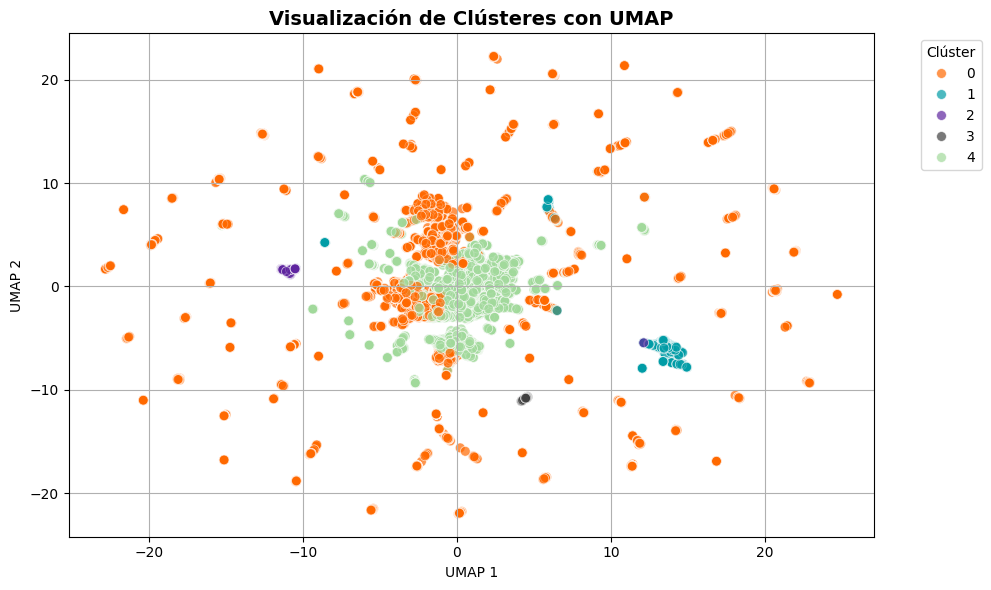

In [ ]:
# 📍 Visualización
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_umap_v1,
    x="UMAP1", y="UMAP2",
    hue="Cluster_v1",
    palette=palette_institucional,
    alpha=0.7,
    s=50
)

plt.title("Visualización de Clústeres con UMAP", fontsize=14, fontweight="bold")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend(title="Clúster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()

TERCERA CORRIDA MODELO

In [ ]:
# Lista de variables con las cuales se va a segmentar#
variables_segmentacion_v2 = [
    "Promedio_Giro_Pesos",
 "Saldo_Constante_mayor_10000","tiene_billetera_mercado","Rangos_SaldoPromedio3M","Rangos_Antiguedad_Billeteraw", "Indicador_TM",
    "promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW", "promedio_MONTO_ultimos_3m_RecargaPSEBilletera",
    "promedio_MONTO_ultimos_3m_TransInterbanBilletera", "promedio_MONTO_ultimos_3m_TransfentreBilleterasW",
    "prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW", "prom_transacciones_ultimos_3m_RecargaPSEBilletera",
    "prom_transacciones_ultimos_3m_TransInterbanBilletera", "prom_transacciones_ultimos_3m_TransfentreBilleterasW",
    "indicadorCreditos", "indicadorCDT", "indicadorGiros", "IVC",
    "exclusivos_billetera", "TiempoVidaBancoW","OFICINAS_PROMEDIO_CANTIDAD3M", "OFICINAS_PROMEDIO_MONTO3M"

]

In [ ]:
# Crear el nuevo DataFrame
df_segmentacion_v2 = df[variables_segmentacion_v2].copy()

In [ ]:
# 📌 Tomar una muestra de 20.000 registros de df_segmentacion
df_sample_v2 = df_segmentacion_v2.sample(n=20000, random_state=42)

In [ ]:
# 1. Identificar columnas numéricas y categóricas EN LA MUESTRA
columnas_numericas_sample_v2 = df_sample_v2.select_dtypes(include=['number']).columns.tolist()
columnas_categoricas_sample_v2 = df_sample_v2.select_dtypes(exclude=['number']).columns.tolist()

# 2. Preprocesamiento (Escalado de variables numéricas) EN LA MUESTRA
scaler_sample = StandardScaler()
df_sample_v2[columnas_numericas_sample_v2] = scaler_sample.fit_transform(df_sample_v2[columnas_numericas_sample_v2])

# 3. Convertir el DataFrame de la muestra a un array de NumPy
data_sample_v2 = df_sample_v2.values

# 4. Obtener los índices de las columnas categóricas EN LA MUESTRA
indices_categoricas_sample_v2 = [df_sample_v2.columns.get_loc(col) for col in columnas_categoricas_sample_v2]

In [ ]:
#por iteracciones anteriores me voy a ir con el mismo numero de cluster k=5#

In [ ]:
# 1. Obtener los índices de las columnas categóricas EN LA MUESTRA
indices_categoricas_sample_v2 = [df_sample_v2.columns.get_loc(col) for col in columnas_categoricas_sample_v2]

# 2. Convertir el DataFrame de la muestra a un array de NumPy
data_sample_v2 = df_sample_v2.values

# 3. Inicializar y ejecutar K-Prototypes con 5 clústeres
n_clusters = 5
kproto_sample_v2 = KPrototypes(n_clusters=n_clusters, init='Cao', n_init=10, verbose=2, random_state=42) # Aumenté n_init para mejor convergencia
clusters_sample_v2 = kproto_sample_v2.fit_predict(data_sample_v2, categorical=indices_categoricas_sample_v2)

# 4. Añadir las etiquetas de los clústeres al DataFrame de la muestra
df_sample_v2['Cluster_v2'] = clusters_sample_v2

# 5. Mostrar los primeros resultados
print("Primeras filas de df_sample con las etiquetas de los clústeres:")
print(df_sample_v2.head())

# 6. Mostrar el tamaño de cada clúster en la muestra
print("\nTamaño de cada clúster en la muestra:")
print(df_sample_v2['Cluster_v2'].value_counts().sort_index())

# 7. Mostrar los centroides de los clústeres (prototipos)
print("\nCentroides de los clústeres (prototipos):")
print(kproto_sample_v2.cluster_centers_)

Initialization method and algorithm are deterministic. Setting n_init to 1.
Init: initializing centroids
Init: initializing clusters
Starting iterations...
Run: 1, iteration: 1/100, moves: 1286, ncost: 250279.51068077574
Run: 1, iteration: 2/100, moves: 3888, ncost: 227159.37373253104
Run: 1, iteration: 3/100, moves: 2500, ncost: 217874.8077234688
Run: 1, iteration: 4/100, moves: 155, ncost: 213778.81517893614
Run: 1, iteration: 5/100, moves: 214, ncost: 208113.50421377236
Run: 1, iteration: 6/100, moves: 107, ncost: 207674.1825811289
Run: 1, iteration: 7/100, moves: 76, ncost: 207029.23318205454
Run: 1, iteration: 8/100, moves: 21, ncost: 207008.30450989385
Run: 1, iteration: 9/100, moves: 10, ncost: 207003.29983832967
Run: 1, iteration: 10/100, moves: 5, ncost: 207000.1041863688
Run: 1, iteration: 11/100, moves: 10, ncost: 206991.7875371583
Run: 1, iteration: 12/100, moves: 6, ncost: 206988.6325776049
Run: 1, iteration: 13/100, moves: 4, ncost: 206987.9010826814
Run: 1, iteration: 14

AttributeError: 'KPrototypes' object has no attribute 'cluster_centers_'

In [ ]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# 1️⃣ Quitar la columna de clúster (no usarla en UMAP)
df_umap_input_v2 = df_sample_v2.drop(columns=["Cluster_v2"], errors='ignore')

# 2️⃣ Detectar variables numéricas y categóricas
columnas_numericas_umap_v2 = df_umap_input_v2.select_dtypes(include=["number"]).columns.tolist()
columnas_categoricas_umap_v2 = df_umap_input_v2.select_dtypes(exclude=["number"]).columns.tolist()

# 3️⃣ Codificar variables categóricas
df_umap_cat_v2 = pd.DataFrame(index=df_umap_input_v2.index)

for col in columnas_categoricas_umap_v2:
    if df_umap_input_v2[col].nunique() == 2:
        le = LabelEncoder()
        df_umap_cat_v2[col] = le.fit_transform(df_umap_input_v2[col])
    else:
        dummies_v2 = pd.get_dummies(df_umap_input_v2[col], prefix=col, drop_first=True)
        df_umap_cat_v2 = pd.concat([df_umap_cat_v2, dummies_v2], axis=1)

# 4️⃣ Unir numéricas + categóricas codificadas
df_umap_ready_v2 = pd.concat([
    df_umap_input_v2[columnas_numericas_umap_v2],  # numéricas ya normalizadas
    df_umap_cat_v2  # categóricas codificadas
], axis=1)

# ✅ Resultado final
print("✅ Dataset listo para aplicar UMAP:", df_umap_ready_v2.shape)
df_umap_ready_v2.head()

✅ Dataset listo para aplicar UMAP: (20000, 31)


,Promedio_Giro_Pesos,promedio_MONTO_ultimos_3m_CompracontdigitalbilleteraW,promedio_MONTO_ultimos_3m_RecargaPSEBilletera,promedio_MONTO_ultimos_3m_TransInterbanBilletera,promedio_MONTO_ultimos_3m_TransfentreBilleterasW,prom_transacciones_ultimos_3m_CompracontdigitalbilleteraW,prom_transacciones_ultimos_3m_RecargaPSEBilletera,prom_transacciones_ultimos_3m_TransInterbanBilletera,prom_transacciones_ultimos_3m_TransfentreBilleterasW,IVC,...,Rangos_Antiguedad_Billeteraw_De 1 a menos de 3 meses,Rangos_Antiguedad_Billeteraw_De 3 a menos de 6 meses,Rangos_Antiguedad_Billeteraw_De 6 a menos de 12 meses,Rangos_Antiguedad_Billeteraw_De 12 a menos de 18 meses,Rangos_Antiguedad_Billeteraw_Más de 18 meses,Indicador_TM,indicadorCreditos,indicadorCDT,indicadorGiros,exclusivos_billetera
62546,-0.05,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-1.30,...,False,False,True,False,False,0,0,0,0,1
17789,-0.05,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-0.40,...,False,False,False,False,False,0,0,0,0,0
37431,-0.05,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-0.40,...,False,True,False,False,False,0,0,0,0,1
40250,-0.05,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-1.30,...,False,False,False,False,True,1,0,0,0,1
13553,-0.05,-0.06,-0.06,-0.09,-0.05,-0.07,-0.11,-0.22,-0.10,-0.40,...,False,True,False,False,False,0,0,0,0,1


In [ ]:
import umap.umap_ as umap
import matplotlib.pyplot as plt
import seaborn as sns

# 🎨 Paleta de colores institucional
palette_institucional = ["#FF6900", "#009CA6", "#5F259F", "#404040", "#A1D99B"]

# 🔄 Ejecutar UMAP
umap_model_v2 = umap.UMAP(n_neighbors=30, min_dist=0.1, random_state=42)
umap_result_v2 = umap_model_v2.fit_transform(df_umap_ready_v2)

# 📦 Crear DataFrame con resultado UMAP
df_umap_v2 = pd.DataFrame(umap_result_v2, columns=["UMAP1", "UMAP2"])
df_umap_v2["Cluster_v2"] = df_sample_v2["Cluster_v2"].values  # Agregar clúster original

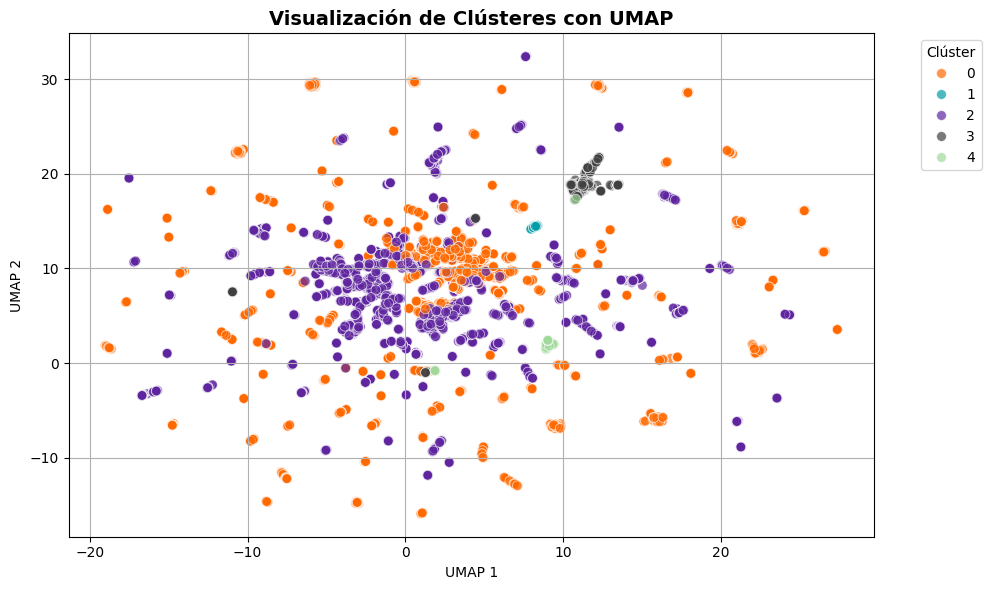

In [ ]:
# 📍 Visualización
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_umap_v2,
    x="UMAP1", y="UMAP2",
    hue="Cluster_v2",
    palette=palette_institucional,
    alpha=0.7,
    s=50
)

plt.title("Visualización de Clústeres con UMAP", fontsize=14, fontweight="bold")
plt.xlabel("UMAP 1")
plt.ylabel("UMAP 2")
plt.legend(title="Clúster", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.tight_layout()
plt.show()